In [4]:
import torch
import torchvision
import torch.nn as nn
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu128
Device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Original image size: (496, 512)
Mask shape: (512, 512)
Mask class IDs: [0 1 2 3 4 5]


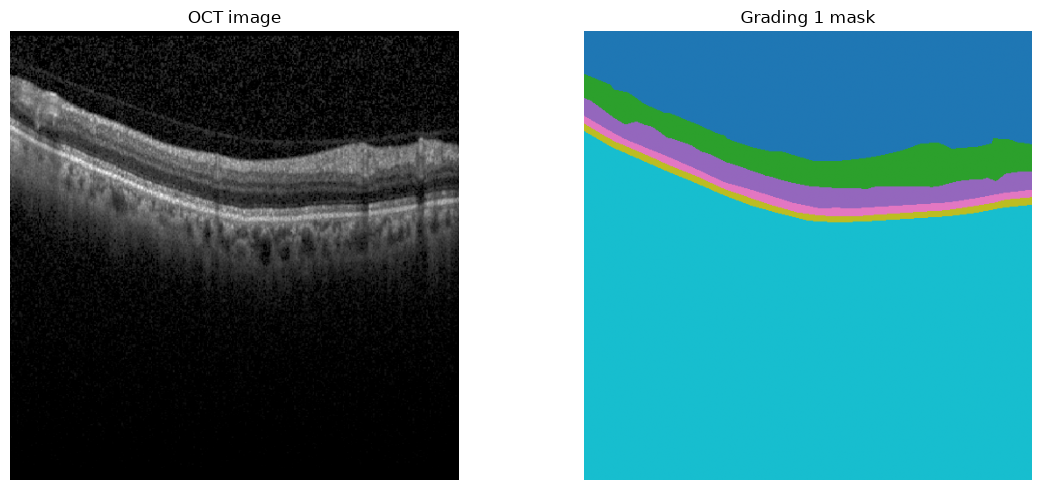

In [ ]:
from pathlib import Path
import csv
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

data_root = Path(r"C:\Users\asus\Documents\OCT5k\OCT5k\OCT5k")
scripts_dir = data_root / "Scripts"

with open(scripts_dir / "paths" / "manual_paths.csv", newline="") as file:
    prepared_path, original_path = next(csv.reader(file)) 
    # path , path of original image

relative_path = Path(prepared_path).relative_to("../Images/Images_Manual")  
#removed part Images/Images Manual
# From ../Images/Images_Manual/AMD Part1/AMD (1).E2E/2- 25- 2017 9- 10- 42 PM/Image 2.png 
# remains AMD Part1/AMD (1).E2E/2- 25- 2017 9- 10- 42 PM/Image 2.png  part only

image_path = scripts_dir / original_path
mask_path = data_root / "Masks" / "Masks_Manual" / "Grading_1" / relative_path
#get the path of manual Grade 1 mask relative to the original image, given 0-5 px based on segment

image = Image.open(image_path).convert("L") #convert original img to grayscale
mask = np.array(Image.open(mask_path))

print("Original image size:", image.size)
print("Mask shape:", mask.shape)
print("Mask class IDs:", np.unique(mask))

image = image.resize((mask.shape[1], mask.shape[0]), Image.Resampling.BILINEAR)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("OCT image")

axes[1].imshow(mask, cmap="tab10", vmin=0, vmax=5)
axes[1].set_title("Grading 1 mask")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class_names = ["AMD", "DME", "Normal"]

# remains AMD Part1/AMD (1).E2E/2- 25- 2017 9- 10- 42 PM/Image 2.png  part only
disease_folder = relative_path.parts[0]
disease_name = disease_folder.split()[0]
disease_label = class_names.index(disease_name)

print("Image:", image_path.name)
print("Disease:", disease_name)
print("Classification label:", disease_label)
print("Segmentation classes present:", np.unique(mask))

Image: Image 2.TIFF
Disease: AMD
Classification label: 0
Segmentation classes present: [0 1 2 3 4 5]


In [7]:
transform = transforms.Compose([
    transforms.Resize((320, 320)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#image transformation
image_tensor = transform(image)

mask_resized = Image.fromarray(mask).resize(
    (320, 320), Image.Resampling.NEAREST #copies the nearest pixel classs id when resizing
)

mask_tensor = torch.from_numpy(np.array(mask_resized)).long() #resized mask -> numpy array -> tensor-> 64bit int type


label_tensor = torch.tensor(disease_label, dtype=torch.long)

print("Image:", image_tensor.shape, image_tensor.dtype)
print("Mask:", mask_tensor.shape, mask_tensor.dtype)
print("Disease label:", label_tensor)

Image: torch.Size([3, 320, 320]) torch.float32
Mask: torch.Size([320, 320]) torch.int64
Disease label: tensor(0)


In [8]:
from torch.utils.data import Dataset

class OCTDataset(Dataset):
    def __init__(self, data_root, transform):
        self.data_root = Path(data_root)
        self.transform = transform
        self.class_names = ["AMD", "DME", "Normal"]

        mapping_path = self.data_root / "Scripts" / "paths" / "manual_paths.csv"

        with open(mapping_path, newline="") as file:
            self.samples = list(csv.reader(file))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        prepared_path, original_path = self.samples[index]

        relative_path = Path(prepared_path).relative_to(
            "../Images/Images_Manual"
        )

        image_path = self.data_root / "Scripts" / original_path
        mask_path = (
            self.data_root / "Masks" / "Masks_Manual"
            / "Grading_1" / relative_path
        )

        image = Image.open(image_path).convert("L")
        mask = Image.open(mask_path)

        image = image.resize(mask.size, Image.Resampling.BILINEAR)
        image_tensor = self.transform(image)

        mask = mask.resize((320, 320), Image.Resampling.NEAREST)
        mask_tensor = torch.from_numpy(np.array(mask)).long()

        disease_name = relative_path.parts[0].split()[0]
        disease_label = self.class_names.index(disease_name)
        label_tensor = torch.tensor(disease_label, dtype=torch.long)

        return image_tensor, label_tensor, mask_tensor

In [10]:
dataset = OCTDataset(data_root, transform)

image_tensor, label_tensor, mask_tensor = dataset[0]

print("Dataset size:", len(dataset))
print("Image:", image_tensor.shape)
print("Disease label:", label_tensor)
print("Mask:", mask_tensor.shape)

Dataset size: 1672
Image: torch.Size([3, 320, 320])
Disease label: tensor(0)
Mask: torch.Size([320, 320])


In [11]:
from torch.utils.data import Subset, DataLoader

groups = {} # {("AMD", "AMD (1).E2E"): [0, 1, 2] ,...,...,..}

for index, (prepared_path, original_path) in enumerate(dataset.samples): #index 0 → first row
    relative_path = Path(prepared_path).relative_to(
        "../Images/Images_Manual"
    )

    # Before
    # ../Images/Images_Manual/AMD Part1/AMD (1).E2E/session/Image 2.png

    # After
    # AMD Part1/AMD (1).E2E/session/Image 2.png

    disease_name = relative_path.parts[0].split()[0]
    # b4 all MD Part1/AMD (1).E2E/session/Image 2.png
    # relative_path.parts[0]       # "AMD Part1"
    # "AMD Part1".split()          # ["AMD", "Part1"]
    # "AMD Part1".split()[0]       # "AMD"

    volume_name = relative_path.parts[1] #AMD (1).E2E  where .E2E has all images of a single scan folder
    #has 24 rows for ex
    # Keep all images from one scan group in the same split.
    group_key = (disease_name, volume_name) #("AMD", "AMD (1).E2E")

    if group_key not in groups:
        groups[group_key] = []

    groups[group_key].append(index)  #("AMD", "AMD (1).E2E"): [0, 1, 2, 3]

group_keys = sorted(groups)

group_labels = []

for disease, volume in group_keys:
    label = dataset.class_names.index(disease)
    group_labels.append(label)

group_labels = torch.tensor(group_labels) # 0 1 1 2.....

#data split
#================================================================
split_seed = 42
split_generator = torch.Generator().manual_seed(split_seed)

train_indices = []
validation_indices = []
test_indices = []

for class_number in range(3):
    class_indices = torch.where(group_labels == class_number)[0]

    # torch.where(group_labels == 0)
    # # (tensor([0, 1, 4]),) -> return a tuple , so we take [0]

    # torch.where(group_labels == 0)[0]
    # # tensor([0, 1, 4])

    shuffled_order = torch.randperm(
        len(class_indices),
        generator=split_generator
    )
    class_indices = class_indices[shuffled_order]

    train_end = int(0.50 * len(class_indices))
    validation_end = train_end + round(0.10 * len(class_indices))

    # group_keys[4] == ("AMD", "AMD (5).E2E")
    # groups[("AMD", "AMD (5).E2E")] == [80, 81, 82]

    for group_index in class_indices[:train_end].tolist():
        train_indices.extend(groups[group_keys[group_index]])

    for group_index in class_indices[train_end:validation_end].tolist():
        validation_indices.extend(groups[group_keys[group_index]])

    for group_index in class_indices[validation_end:].tolist():
        test_indices.extend(groups[group_keys[group_index]])

trainset = Subset(dataset, train_indices)
validationset = Subset(dataset, validation_indices)
testset = Subset(dataset, test_indices)

print("Training images:", len(trainset))
print("Validation images:", len(validationset))
print("Test images:", len(testset))

Training images: 833
Validation images: 124
Test images: 715


In [15]:
batch_size = 2

trainloader = DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=0
)

validationloader = DataLoader(
    validationset, batch_size=batch_size, shuffle=False, num_workers=0
)

testloader = DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=0
)

images, labels, masks = next(iter(trainloader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Masks:", masks.shape)

Images: torch.Size([2, 3, 320, 320])
Labels: torch.Size([2])
Masks: torch.Size([2, 320, 320])


In [9]:
%pip install segmentation-models-pytorch

Note: you may need to restart the kernel to use updated packages.


In [13]:
import segmentation_models_pytorch as smp

class CAMELModel(nn.Module):
    def __init__(self, encoder_name="resnet101"):
        super().__init__()

        self.network = smp.Unet(
            encoder_name=encoder_name,
            encoder_depth=5, #5 downsampling stages
            encoder_weights="imagenet",
            in_channels=3,
            classes=6, #segmentation
            decoder_channels=(256, 128, 64, 32, 16),
            decoder_use_norm="batchnorm",
            decoder_attention_type=None,
            decoder_interpolation="nearest", #how to enlarge decoder  feature maps (upsampling)
            activation=None,

            #classification
            aux_params={
                "pooling": "avg",
                "dropout": 0.5,
                "classes": 3,
                "activation": None
            }
        )

    def forward(self, x):
        segmentation_output, classification_output = self.network(x)

        return classification_output, segmentation_output

c:\Users\asus\Documents\EN3150-PneumoniaMNIST\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Images: [batch, 3, 320, 320]
                  │
            Shared encoder
                  │
          Deepest feature maps
                  │
           ┌──────┴─────────┐
           │                │
    Average pooling      U-Net decoder
           │             + skip connections
       Dropout              │
           │          Segmentation output
    Linear classifier   [batch, 6, 320, 320]
           │
 Classification output
       [batch, 3]

In [16]:
model = CAMELModel().to(device)

images, labels, masks = next(iter(trainloader))

images = images.to(device)

model.eval()

with torch.no_grad():
    classification_output, segmentation_output = model(images) 
    #just running one fwd pass disabling gradient descent

#checking whether dimesions correct for batch of 2
print("Input images:", images.shape)
print("Classification output:", classification_output.shape)
print("Disease labels:", labels.shape)
print("Segmentation output:", segmentation_output.shape) 
#segmentation output bears six probabilities per pixel , whhere target stores one class ID per pixel
print("Target masks:", masks.shape)

Input images: torch.Size([2, 3, 320, 320])
Classification output: torch.Size([2, 3])
Disease labels: torch.Size([2])
Segmentation output: torch.Size([2, 6, 320, 320])
Target masks: torch.Size([2, 320, 320])


In [17]:
criterion_classification = nn.CrossEntropyLoss()
criterion_segmentation_ce = nn.CrossEntropyLoss()

In [20]:
labels = labels.to(device)
masks = masks.to(device)

classification_loss = criterion_classification(
    classification_output, labels
)

segmentation_ce_loss = criterion_segmentation_ce(
    segmentation_output, masks
)

print("Classification loss:", classification_loss.item())
print("Segmentation cross-entropy:", segmentation_ce_loss.item())

Classification loss: 1.8521552085876465
Segmentation cross-entropy: 1.8347222805023193


In [18]:
import torch.nn.functional as F

def dice_loss(segmentation_output, masks):
    probabilities = torch.softmax(segmentation_output, dim=1)
    #convert scores for probabilities sum to 1

    target = F.one_hot(masks, num_classes=6)
    # Class ID:       2
    # One-hot form:   [0, 0, 1, 0, 0, 0]


    target = target.permute(0, 3, 1, 2).float()
    # [batch, height, width, 6] → [batch, 6, height, width]

    intersection = torch.sum(probabilities * target)
    #only onehot encoded as 1's remain with their porbabilities
    total = torch.sum(probabilities) + torch.sum(target)

    dice_score = (2 * intersection) / (total + 1e-7) #to avoid denominator gets 0
    #better intersection -> higher dice score-> lower  dice loss

    return 1 - dice_score

In [21]:
segmentation_dice_loss = dice_loss(segmentation_output, masks)

# Our baseline choice: give both tasks equal loss weights.
# This is not the paper's adaptive task-weighting rule.
segmentation_loss = (
    0.5 * segmentation_ce_loss
    + 0.5 * segmentation_dice_loss
)

print("Dice loss:", segmentation_dice_loss.item())
print("Combined segmentation loss:", segmentation_loss.item())

Dice loss: 0.836628794670105
Combined segmentation loss: 1.3356754779815674


In [17]:
classification_weight = 0.5
segmentation_weight = 0.5

# Our baseline choice: give both tasks equal loss weights.
# This is not the paper's adaptive task-weighting rule.

total_loss = (
    classification_weight * classification_loss
    + segmentation_weight * segmentation_loss
)

print("Classification loss:", classification_loss.item())
print("Segmentation loss:", segmentation_loss.item())
print("Total loss:", total_loss.item())

Classification loss: 1.5310107469558716
Segmentation loss: 1.4352701902389526
Total loss: 1.483140468597412


Classification cross-entropy ──────────────────┐
                                              ├→ Total loss
Segmentation: 0.5 × CE + 0.5 × Dice loss ──────┘

In [18]:
#based on source github code
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.0,
    weight_decay=0.0
)

In [23]:
model.train()

images, labels, masks = next(iter(trainloader))

images = images.to(device)
labels = labels.to(device)
masks = masks.to(device)

optimizer.zero_grad()

classification_output, segmentation_output = model(images)

classification_loss = criterion_classification(
    classification_output, labels
)

segmentation_ce_loss = criterion_segmentation_ce(
    segmentation_output, masks
)

segmentation_dice_loss = dice_loss(
    segmentation_output, masks
)

segmentation_loss = (
    0.5 * segmentation_ce_loss
    + 0.5 * segmentation_dice_loss
)

total_loss = (
    classification_weight * classification_loss
    + segmentation_weight * segmentation_loss
)

total_loss.backward()
optimizer.step()

print("Training step completed")
print("Classification loss:", classification_loss.item())
print("Segmentation loss:", segmentation_loss.item())
print("Total loss:", total_loss.item())

Training step completed
Classification loss: 1.2826216220855713
Segmentation loss: 1.3431575298309326
Total loss: 1.312889575958252


In [19]:
def accuracy(loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for data, labels, masks in loader:
            data, labels = data.to(device), labels.to(device)

            classification_output, segmentation_output = model(data) 
            #get the class id of highest logit and _ discards the score values, we only need the class id    

            _, predicted = torch.max(classification_output, 1)

            total += labels.size(0) #imges in batch
            correct += (predicted == labels).sum().item()

    return 100 * correct / total

In [24]:
optimizer2 = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0
)

In [ ]:
import copy
import time

epochs = 20

sgd_batch_losses = []
sgd_train_losses = []
sgd_validation_losses = []
sgd_train_accuracies = []
sgd_validation_accuracies = []

sgd_start = time.time()

best_validation_loss = float("inf")
best_model_state = None

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    total = 0

    for images, labels, masks in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        classification_output, segmentation_output = model(images)

        classification_loss = criterion_classification(
            classification_output, labels
        )

        segmentation_loss = (
            0.5 * criterion_segmentation_ce(segmentation_output, masks)
            + 0.5 * dice_loss(segmentation_output, masks)
        )

        loss = (
            classification_weight * classification_loss
            + segmentation_weight * segmentation_loss
        )

        sgd_batch_losses.append(loss.item())

        optimizer2.zero_grad()
        loss.backward()
        optimizer2.step()

        batch_count = images.size(0)
        running_loss += loss.item() * batch_count
        total += batch_count

    avg_loss = running_loss / total
    sgd_train_losses.append(avg_loss)

    train_acc = accuracy(trainloader)
    sgd_train_accuracies.append(train_acc)

    model.eval()
    validation_loss_sum = 0.0
    validation_correct = 0
    validation_total = 0

    with torch.no_grad():
        for validation_images, validation_labels, validation_masks in validationloader:
            validation_images = validation_images.to(device)
            validation_labels = validation_labels.to(device)
            validation_masks = validation_masks.to(device)

            validation_classification, validation_segmentation = model(
                validation_images
            )

            validation_classification_loss = criterion_classification(
                validation_classification, validation_labels
            )

            validation_segmentation_loss = (
                0.5 * criterion_segmentation_ce(
                    validation_segmentation, validation_masks
                )
                + 0.5 * dice_loss(
                    validation_segmentation, validation_masks
                )
            )

            validation_batch_loss = (
                classification_weight * validation_classification_loss
                + segmentation_weight * validation_segmentation_loss
            )

            batch_count = validation_images.size(0)
            validation_loss_sum += validation_batch_loss.item() * batch_count

            validation_correct += (
                validation_classification.argmax(dim=1) == validation_labels
            ).sum().item()

            validation_total += batch_count

    avg_validation_loss = validation_loss_sum / validation_total
    validation_acc = 100 * validation_correct / validation_total

    sgd_validation_losses.append(avg_validation_loss)
    sgd_validation_accuracies.append(validation_acc)

    if avg_validation_loss < best_validation_loss:
        best_validation_loss = avg_validation_loss
        best_model_state = copy.deepcopy(model.state_dict())
        torch.save(best_model_state, "camel_best_model.pt")
        #torch.save(best_model_state, "camel_resnet101_lr001.pt")

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Validation Loss: {avg_validation_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Validation Acc: {validation_acc:.2f}%"
    )

sgd_end = time.time()
sgd_time = sgd_end - sgd_start

print("Time for training:", sgd_time, "seconds")

model.load_state_dict(best_model_state)

#eah line checks all training 833 images in batches of 2 images and returns the overall accuracy

Epoch 1/20 | Loss: 0.8427 | Validation Loss: 1.2317 | Train Acc: 46.70% | Validation Acc: 51.61%
Epoch 2/20 | Loss: 0.7286 | Validation Loss: 39.4003 | Train Acc: 45.86% | Validation Acc: 36.29%
Epoch 3/20 | Loss: 0.6120 | Validation Loss: 0.6526 | Train Acc: 40.82% | Validation Acc: 38.71%
Epoch 4/20 | Loss: 0.5871 | Validation Loss: 0.6113 | Train Acc: 43.10% | Validation Acc: 37.10%
Epoch 5/20 | Loss: 0.5742 | Validation Loss: 0.5677 | Train Acc: 48.62% | Validation Acc: 50.00%
Epoch 6/20 | Loss: 0.5633 | Validation Loss: 0.4527 | Train Acc: 58.58% | Validation Acc: 58.87%
Epoch 7/20 | Loss: 0.5351 | Validation Loss: 0.3634 | Train Acc: 58.94% | Validation Acc: 83.87%
Epoch 8/20 | Loss: 0.5142 | Validation Loss: 0.5846 | Train Acc: 42.26% | Validation Acc: 47.58%
Epoch 9/20 | Loss: 0.5005 | Validation Loss: 0.4019 | Train Acc: 69.27% | Validation Acc: 64.52%
Epoch 10/20 | Loss: 0.4813 | Validation Loss: 0.4743 | Train Acc: 59.06% | Validation Acc: 72.58%
Epoch 11/20 | Loss: 0.4359 |

<All keys matched successfully>

              precision    recall  f1-score   support

         AMD       0.73      0.67      0.70       351
         DME       0.79      0.51      0.62       152
      Normal       0.49      0.69      0.58       212

    accuracy                           0.64       715
   macro avg       0.67      0.62      0.63       715
weighted avg       0.67      0.64      0.65       715



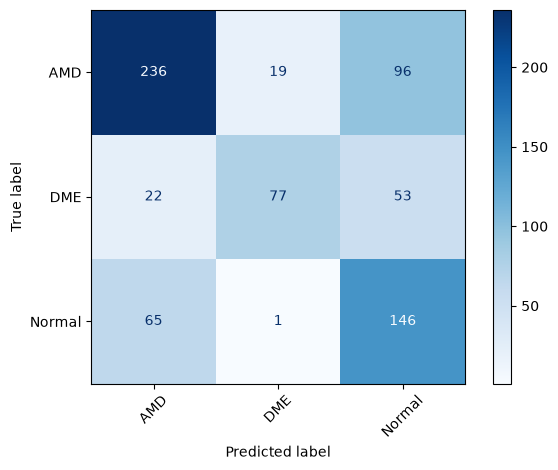

In [22]:
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)

model.eval()

all_true_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels, masks in testloader:
        images = images.to(device)

        classification_output, segmentation_output = model(images)
        predictions = classification_output.argmax(dim=1)

        all_true_labels.extend(labels.tolist())
        all_predictions.extend(predictions.cpu().tolist())

class_names = dataset.class_names

print(classification_report(
    all_true_labels,
    all_predictions,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

matrix = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=list(range(len(class_names)))
)

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_names
).plot(xticks_rotation=45, cmap="Blues")

plt.tight_layout()
plt.show()

In [23]:
model.eval()

intersection = torch.zeros(6, device=device)
predicted_pixels = torch.zeros(6, device=device)
target_pixels = torch.zeros(6, device=device)

with torch.no_grad():
    for images, labels, masks in testloader:
        images = images.to(device)
        masks = masks.to(device)

        classification_output, segmentation_output = model(images)
        predictions = segmentation_output.argmax(dim=1)

        for class_number in range(6):
            predicted_class = predictions == class_number
            target_class = masks == class_number

            intersection[class_number] += (
                predicted_class & target_class
            ).sum()

            predicted_pixels[class_number] += predicted_class.sum()
            target_pixels[class_number] += target_class.sum()

denominator = predicted_pixels + target_pixels
union = denominator - intersection

dice_scores = torch.full_like(intersection, float("nan"))
iou_scores = torch.full_like(intersection, float("nan"))

valid_classes = union > 0

dice_scores[valid_classes] = (
    2 * intersection[valid_classes]
    / denominator[valid_classes]
)

iou_scores[valid_classes] = (
    intersection[valid_classes]
    / union[valid_classes]
)

for class_number in range(6):
    print(
        f"Class {class_number} | "
        f"Dice: {dice_scores[class_number].item():.4f} | "
        f"IoU: {iou_scores[class_number].item():.4f}"
    )

print("Mean Dice:", dice_scores[valid_classes].mean().item())
print("Mean IoU:", iou_scores[valid_classes].mean().item())

final_test_accuracy = accuracy(testloader)
print(f"Final test accuracy: {final_test_accuracy:.2f}%")

Class 0 | Dice: 0.9935 | IoU: 0.9870
Class 1 | Dice: 0.9481 | IoU: 0.9014
Class 2 | Dice: 0.9330 | IoU: 0.8744
Class 3 | Dice: 0.8677 | IoU: 0.7664
Class 4 | Dice: 0.8453 | IoU: 0.7321
Class 5 | Dice: 0.9958 | IoU: 0.9916
Mean Dice: 0.9305847883224487
Mean IoU: 0.8754972219467163
Final test accuracy: 64.20%


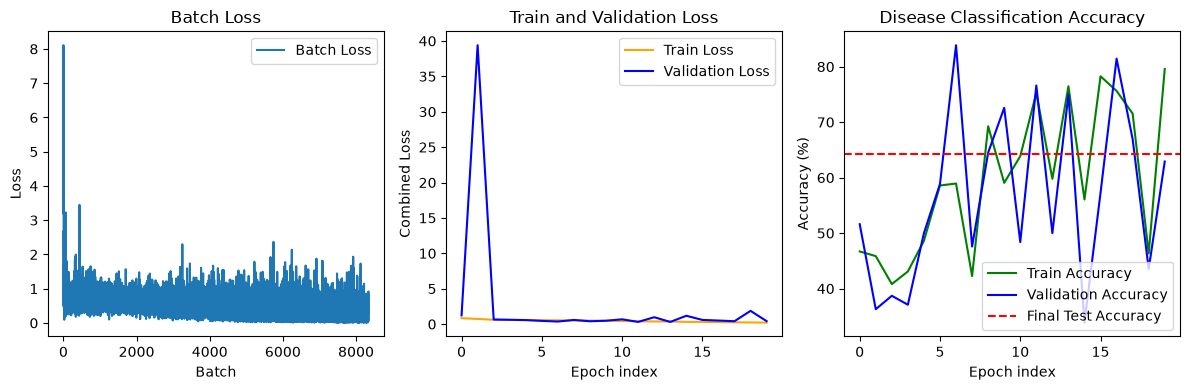

In [24]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.plot(sgd_batch_losses, label="Batch Loss")
plt.title("Batch Loss")
plt.xlabel("Batch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 3, 2)
plt.plot(sgd_train_losses, label="Train Loss", color="orange")
plt.plot(sgd_validation_losses, label="Validation Loss", color="blue")
plt.title("Train and Validation Loss")
plt.xlabel("Epoch index")
plt.ylabel("Combined Loss")
plt.legend()

plt.subplot(1, 3, 3)
plt.plot(sgd_train_accuracies, label="Train Accuracy", color="green")
plt.plot(
    sgd_validation_accuracies,
    label="Validation Accuracy",
    color="blue"
)
plt.axhline(
    final_test_accuracy,
    label="Final Test Accuracy",
    color="red",
    linestyle="--"
)
plt.title("Disease Classification Accuracy")
plt.xlabel("Epoch index")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()

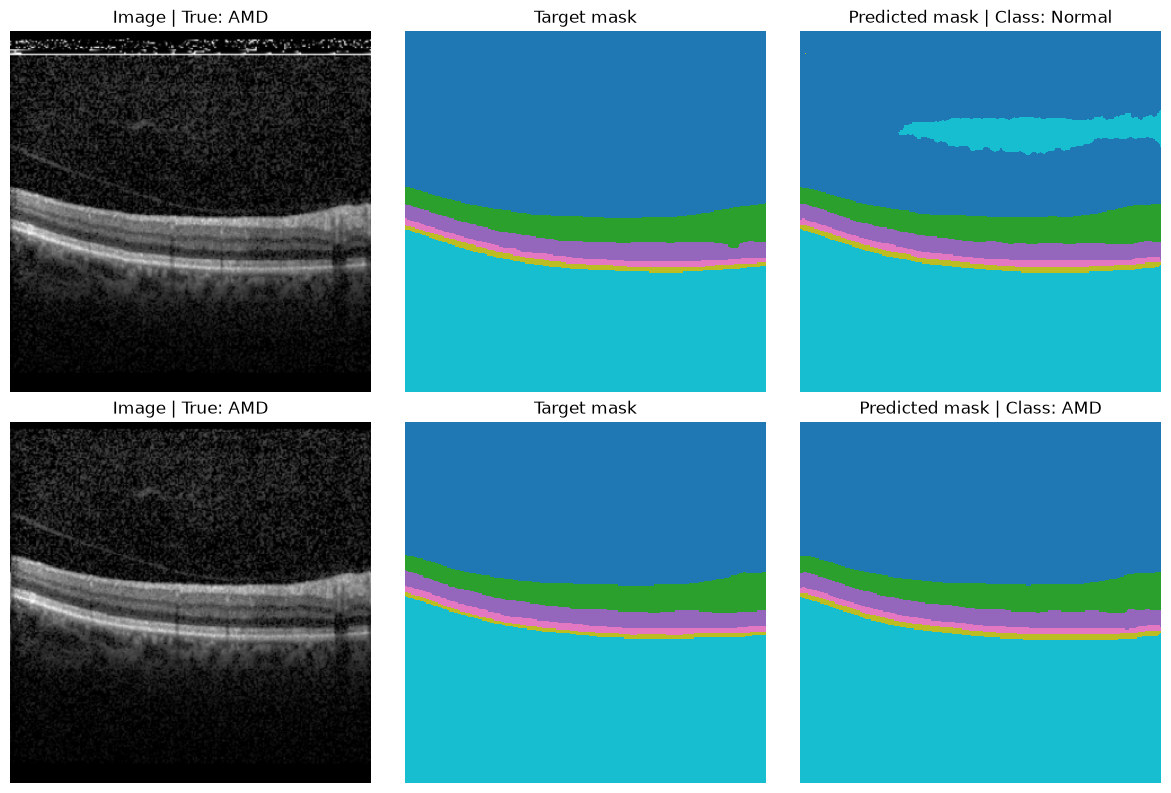

In [25]:
import matplotlib.pyplot as plt

images, labels, masks = next(iter(testloader))

images = images.to(device)
model.eval()

with torch.no_grad():
    classification_output, segmentation_output = model(images)

predicted_classes = classification_output.argmax(dim=1)
predicted_masks = segmentation_output.argmax(dim=1)

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

number_to_show = min(2, images.size(0))
fig, axes = plt.subplots(number_to_show, 3, figsize=(12, 4 * number_to_show))

if number_to_show == 1:
    axes = axes.reshape(1, 3)

for i in range(number_to_show):
    image = (images[i].cpu() * std + mean).clamp(0, 1).mean(dim=0)

    true_disease = dataset.class_names[labels[i].item()]
    predicted_disease = dataset.class_names[predicted_classes[i].item()]

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(f"Image | True: {true_disease}")

    axes[i, 1].imshow(masks[i], cmap="tab10", vmin=0, vmax=5,
                       interpolation="nearest")
    axes[i, 1].set_title("Target mask")

    axes[i, 2].imshow(predicted_masks[i].cpu(), cmap="tab10", vmin=0, vmax=5,
                       interpolation="nearest")
    axes[i, 2].set_title(f"Predicted mask | Class: {predicted_disease}")

    for axis in axes[i]:
        axis.axis("off")

plt.tight_layout()
plt.show()

VERIFYING EPOCH POINT

THE PATCH IN PREDICTION IS UNDESIRABLE

In [26]:
best_epoch = min(
    range(len(sgd_validation_losses)),
    key=lambda i: sgd_validation_losses[i]
)

print("Selected epoch:", best_epoch + 1)
print(
    "Validation loss at that epoch:",
    sgd_validation_losses[best_epoch]
)
print(
    "Classification accuracy at that epoch:",
    sgd_validation_accuracies[best_epoch]
)

model.load_state_dict(
    torch.load(
        "camel_best_model.pt",
        map_location=device,
        weights_only=True
    )
)

validation_acc = accuracy(validationloader)

print(f"Saved model validation accuracy: {validation_acc:.2f}%")

Selected epoch: 14
Validation loss at that epoch: 0.30866231784344683
Classification accuracy at that epoch: 75.0
Saved model validation accuracy: 75.00%


REPEATING THE SAME WITH LESS LEARNING RATE

In [27]:
import shutil
import copy

shutil.copy2(
    "camel_best_model.pt",
    "camel_resnet101_lr01_baseline.pt"
)

baseline_results = {
    "train_losses": copy.deepcopy(sgd_train_losses),
    "validation_losses": copy.deepcopy(sgd_validation_losses),
    "train_accuracies": copy.deepcopy(sgd_train_accuracies),
    "validation_accuracies": copy.deepcopy(sgd_validation_accuracies)
}

In [28]:
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = CAMELModel().to(device)

optimizer2 = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0
)

In [29]:
import copy
import time

epochs = 20

sgd_batch_losses = []
sgd_train_losses = []
sgd_validation_losses = []
sgd_train_accuracies = []
sgd_validation_accuracies = []

sgd_start = time.time()

best_validation_loss = float("inf")
best_model_state = None

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    total = 0

    for images, labels, masks in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        classification_output, segmentation_output = model(images)

        classification_loss = criterion_classification(
            classification_output, labels
        )

        segmentation_loss = (
            0.5 * criterion_segmentation_ce(segmentation_output, masks)
            + 0.5 * dice_loss(segmentation_output, masks)
        )

        loss = (
            classification_weight * classification_loss
            + segmentation_weight * segmentation_loss
        )

        sgd_batch_losses.append(loss.item())

        optimizer2.zero_grad()
        loss.backward()
        optimizer2.step()

        batch_count = images.size(0)
        running_loss += loss.item() * batch_count
        total += batch_count

    avg_loss = running_loss / total
    sgd_train_losses.append(avg_loss)

    train_acc = accuracy(trainloader)
    sgd_train_accuracies.append(train_acc)

    model.eval()
    validation_loss_sum = 0.0
    validation_correct = 0
    validation_total = 0

    with torch.no_grad():
        for validation_images, validation_labels, validation_masks in validationloader:
            validation_images = validation_images.to(device)
            validation_labels = validation_labels.to(device)
            validation_masks = validation_masks.to(device)

            validation_classification, validation_segmentation = model(
                validation_images
            )

            validation_classification_loss = criterion_classification(
                validation_classification, validation_labels
            )

            validation_segmentation_loss = (
                0.5 * criterion_segmentation_ce(
                    validation_segmentation, validation_masks
                )
                + 0.5 * dice_loss(
                    validation_segmentation, validation_masks
                )
            )

            validation_batch_loss = (
                classification_weight * validation_classification_loss
                + segmentation_weight * validation_segmentation_loss
            )

            batch_count = validation_images.size(0)
            validation_loss_sum += validation_batch_loss.item() * batch_count

            validation_correct += (
                validation_classification.argmax(dim=1) == validation_labels
            ).sum().item()

            validation_total += batch_count

    avg_validation_loss = validation_loss_sum / validation_total
    validation_acc = 100 * validation_correct / validation_total

    sgd_validation_losses.append(avg_validation_loss)
    sgd_validation_accuracies.append(validation_acc)

    if avg_validation_loss < best_validation_loss:
        best_validation_loss = avg_validation_loss
        best_model_state = copy.deepcopy(model.state_dict())
        #torch.save(best_model_state, "camel_best_model.pt")
        torch.save(best_model_state, "camel_resnet101_lr001.pt")

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Validation Loss: {avg_validation_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Validation Acc: {validation_acc:.2f}%"
    )

sgd_end = time.time()
sgd_time = sgd_end - sgd_start

print("Time for training:", sgd_time, "seconds")

model.load_state_dict(best_model_state)

Epoch 1/20 | Loss: 0.6999 | Validation Loss: 0.9860 | Train Acc: 78.03% | Validation Acc: 83.06%
Epoch 2/20 | Loss: 0.3136 | Validation Loss: 0.1336 | Train Acc: 94.48% | Validation Acc: 94.35%
Epoch 3/20 | Loss: 0.1846 | Validation Loss: 0.2052 | Train Acc: 99.04% | Validation Acc: 86.29%
Epoch 4/20 | Loss: 0.0781 | Validation Loss: 0.6236 | Train Acc: 97.24% | Validation Acc: 67.74%
Epoch 5/20 | Loss: 0.0504 | Validation Loss: 0.6167 | Train Acc: 100.00% | Validation Acc: 75.00%
Epoch 6/20 | Loss: 0.0273 | Validation Loss: 0.3391 | Train Acc: 100.00% | Validation Acc: 84.68%
Epoch 7/20 | Loss: 0.0330 | Validation Loss: 0.4451 | Train Acc: 100.00% | Validation Acc: 81.45%
Epoch 8/20 | Loss: 0.0212 | Validation Loss: 0.6260 | Train Acc: 100.00% | Validation Acc: 79.84%
Epoch 9/20 | Loss: 0.0228 | Validation Loss: 0.5060 | Train Acc: 100.00% | Validation Acc: 78.23%
Epoch 10/20 | Loss: 0.0193 | Validation Loss: 0.5472 | Train Acc: 99.40% | Validation Acc: 79.84%
Epoch 11/20 | Loss: 0.01

<All keys matched successfully>

In [30]:
validation_acc = accuracy(validationloader)
print(f"New model validation accuracy: {validation_acc:.2f}%")

New model validation accuracy: 94.35%


That is a  improvement validation accuracy increased from 75.00% to 94.35%..a gain of 19.35 percentage points.

But that improvement in classification due to learning rate was not an improvementt in segmentation.


In [ ]:
model.load_state_dict(
    torch.load(
        # "camel_resnet101_lr001.pt",
        "camel_resnet101_lr01_baseline.pt",
        #currently contains the original LR 0.1 checkpoint.
        map_location=device,
        weights_only=True
    )
)

model.eval()

intersection = torch.zeros(6, device=device)  #TP
predicted_pixels = torch.zeros(6, device=device) #TP +FP
target_pixels = torch.zeros(6, device=device) #TP +FN


# predicted_pixels = [
#     30000,  # those who predicted class 0 
#     20000,  # class 1
#     15000,  # class 2
#      2000,  # class 3
#      3000,  # class 4
#     32400   # class 5
# ]

with torch.no_grad():
    for images, labels, masks in validationloader:
        images = images.to(device)
        masks = masks.to(device)

        classification_output, segmentation_output = model(images)
        predictions = segmentation_output.argmax(dim=1)

        for class_number in range(6):
            predicted_class = predictions == class_number
            target_class = masks == class_number

            intersection[class_number] += (
                predicted_class & target_class
            ).sum()

            predicted_pixels[class_number] += predicted_class.sum()
            target_pixels[class_number] += target_class.sum()

denominator = predicted_pixels + target_pixels # 2 * TP + FP + FN
union = denominator - intersection  #TP + FP + FN

dice_scores = torch.full_like(intersection, float("nan")) 
#If the class not in both prediction and target, then dice score is undefined, so we fill it with NaN
iou_scores = torch.full_like(intersection, float("nan"))

valid_classes = union > 0 
#checks which classes are present in either prediction or target, 
#  so that we can calculate dice and iou scores for those classes only

dice_scores[valid_classes] = (
    2 * intersection[valid_classes]
    / denominator[valid_classes]
)

iou_scores[valid_classes] = (
    intersection[valid_classes]
    / union[valid_classes]
)

for class_number in range(6):
    print(
        f"Class {class_number} | "
        f"Dice: {dice_scores[class_number].item():.4f} | "
        f"IoU: {iou_scores[class_number].item():.4f}"
    )

print(
    "Validation Mean Dice:",
    dice_scores[valid_classes].mean().item()
)

print(
    "Validation Mean IoU:",
    iou_scores[valid_classes].mean().item()
)

Class 0 | Dice: 0.9908 | IoU: 0.9818
Class 1 | Dice: 0.9494 | IoU: 0.9037
Class 2 | Dice: 0.9270 | IoU: 0.8639
Class 3 | Dice: 0.8360 | IoU: 0.7181
Class 4 | Dice: 0.8373 | IoU: 0.7201
Class 5 | Dice: 0.9925 | IoU: 0.9850
Validation Mean Dice: 0.9221566915512085
Validation Mean IoU: 0.862123429775238


| Validation metric | Original: LR `0.1` | New: LR `0.01` |
|---|---:|---:|
| Classification accuracy | 75.00% | **94.35%** |
| Mean Dice | **92.22%** | 78.66% |
| Mean IoU | **86.21%** | 68.91% |

In [28]:
def validation_metrics(loader):
    model.eval()

    correct = 0
    total = 0

    intersection = torch.zeros(6, device=device)
    predicted_pixels = torch.zeros(6, device=device)
    target_pixels = torch.zeros(6, device=device)

    with torch.no_grad():
        for images, labels, masks in loader:
            images = images.to(device)
            labels = labels.to(device)
            masks = masks.to(device)

            classification_output, segmentation_output = model(images)

            predicted_labels = classification_output.argmax(dim=1)
            predicted_masks = segmentation_output.argmax(dim=1)

            correct += (predicted_labels == labels).sum().item()
            total += labels.size(0)

            for class_number in range(6):
                predicted_class = predicted_masks == class_number
                target_class = masks == class_number

                intersection[class_number] += (
                    predicted_class & target_class
                ).sum()

                predicted_pixels[class_number] += predicted_class.sum()
                target_pixels[class_number] += target_class.sum()

    denominator = predicted_pixels + target_pixels
    union = denominator - intersection

    valid_classes = union > 0

    dice_scores = (
        2 * intersection[valid_classes]
        / denominator[valid_classes]
    )

    iou_scores = (
        intersection[valid_classes]
        / union[valid_classes]
    )

    classification_accuracy = 100 * correct / total
    mean_dice = dice_scores.mean().item()
    mean_iou = iou_scores.mean().item()

    return classification_accuracy, mean_dice, mean_iou

In [34]:
validation_acc, validation_dice, validation_iou = validation_metrics(
    validationloader
)

print(f"Validation classification accuracy: {validation_acc:.2f}%")
print(f"Validation mean Dice: {validation_dice:.4f}")
print(f"Validation mean IoU: {validation_iou:.4f}")

Validation classification accuracy: 75.00%
Validation mean Dice: 0.9222
Validation mean IoU: 0.8621


### Validation of classification and segmentation

This function evaluates the model without updating its weights. It calculates disease-classification accuracy and the mean segmentation Dice and IoU across the six mask classes.

Evaluating both tasks helps us identify when classification improves while segmentation becomes worse.

In [36]:
import time
import torch
import torch.nn as nn

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = CAMELModel().to(device)

criterion_classification = nn.CrossEntropyLoss()
criterion_segmentation_ce = nn.CrossEntropyLoss()

classification_weight = 0.5
segmentation_weight = 0.5

optimizer2 = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0
)

epochs = 20

sgd_batch_losses = []
sgd_train_losses = []
sgd_validation_losses = []
sgd_train_accuracies = []
sgd_validation_accuracies = []
sgd_validation_dice = []
sgd_validation_iou = []
sgd_validation_joint_scores = []

best_classification_accuracy = -1
best_segmentation_iou = -1
best_joint_score = -1
best_joint_epoch = 0

classification_checkpoint = "camel_run3_best_classification.pt"
segmentation_checkpoint = "camel_run3_best_segmentation.pt"
joint_checkpoint = "camel_run3_best_joint.pt"


def accuracy(loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels, masks in loader:
            images = images.to(device)
            labels = labels.to(device)

            classification_output, segmentation_output = model(images)
            predicted = classification_output.argmax(dim=1)

            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    return 100 * correct / total

if device.type == "cuda":
    torch.cuda.synchronize()

### Training with validation tracking for both tasks

This experiment trains a fresh ResNet101-based multi-task U-Net for 20 epochs using SGD with a learning rate of 0.01. Each batch produces disease predictions and segmentation predictions, whose losses are combined to update the model.

After every epoch, we record validation loss, classification accuracy, Dice, and IoU. We save checkpoints for the highest classification accuracy, highest segmentation IoU, and highest joint score.

The joint score averages classification accuracy expressed as a fraction and mean IoU. This is our checkpoint-selection rule, not a rule from the CAMEL paper.

Training time and metric histories are also saved. Finally, the checkpoint with the highest joint score is loaded and evaluated. These checkpoints belong to one training run; they are not separate ensemble models.

| Setting | First run | Second run | Current run |
|---|---|---|---|
| Architecture | ResNet101 + U-Net decoder + classifier | Same | Same |
| Tasks trained | Classification + segmentation | Both | Both |
| SGD learning rate | `0.1` | `0.01` | `0.01` |
| Epochs | 20 | 20 | 20 |
| Segmentation metrics recorded every epoch | No | No | **Yes** |
| Checkpoint selection | Lowest combined validation loss | Lowest combined validation loss | **Best classification, best IoU, and best joint score** |

In [37]:
import time
import torch

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = CAMELModel().to(device)

optimizer2 = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0
)

classification_weight = 0.5
segmentation_weight = 0.5

epochs = 20

sgd_batch_losses = []
sgd_train_losses = []
sgd_validation_losses = []
sgd_train_accuracies = []
sgd_validation_accuracies = []
sgd_validation_dice = []
sgd_validation_iou = []
sgd_validation_joint_scores = []

best_classification_accuracy = -1
best_segmentation_iou = -1
best_joint_score = -1

best_classification_epoch = 0
best_segmentation_epoch = 0
best_joint_epoch = 0

if device.type == "cuda":
    torch.cuda.synchronize()

sgd_start = time.time()

for epoch in range(epochs):
    epoch_start = time.time()

    model.train()

    running_loss = 0.0
    total = 0

    for images, labels, masks in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        optimizer2.zero_grad()

        classification_output, segmentation_output = model(images)

        classification_loss = criterion_classification(
            classification_output, labels
        )

        segmentation_loss = (
            0.5 * criterion_segmentation_ce(
                segmentation_output, masks
            )
            + 0.5 * dice_loss(segmentation_output, masks)
        )

        loss = (
            classification_weight * classification_loss
            + segmentation_weight * segmentation_loss
        )

        loss.backward()
        optimizer2.step()

        sgd_batch_losses.append(loss.item())

        batch_count = images.size(0)
        running_loss += loss.item() * batch_count
        total += batch_count

    avg_loss = running_loss / total
    sgd_train_losses.append(avg_loss)

    train_acc = accuracy(trainloader)
    sgd_train_accuracies.append(train_acc)

    model.eval()

    validation_loss_sum = 0.0
    validation_total = 0

    with torch.no_grad():
        for validation_images, validation_labels, validation_masks in validationloader:
            validation_images = validation_images.to(device)
            validation_labels = validation_labels.to(device)
            validation_masks = validation_masks.to(device)

            validation_classification, validation_segmentation = model(
                validation_images
            )

            validation_classification_loss = criterion_classification(
                validation_classification, validation_labels
            )

            validation_segmentation_loss = (
                0.5 * criterion_segmentation_ce(
                    validation_segmentation, validation_masks
                )
                + 0.5 * dice_loss(
                    validation_segmentation, validation_masks
                )
            )

            validation_batch_loss = (
                classification_weight * validation_classification_loss
                + segmentation_weight * validation_segmentation_loss
            )

            batch_count = validation_images.size(0)

            validation_loss_sum += (
                validation_batch_loss.item() * batch_count
            )

            validation_total += batch_count

    avg_validation_loss = validation_loss_sum / validation_total

    validation_acc, validation_dice, validation_iou = validation_metrics(
        validationloader
    )

    joint_score = (
        0.5 * (validation_acc / 100)
        + 0.5 * validation_iou
    )

    sgd_validation_losses.append(avg_validation_loss)
    sgd_validation_accuracies.append(validation_acc)
    sgd_validation_dice.append(validation_dice)
    sgd_validation_iou.append(validation_iou)
    sgd_validation_joint_scores.append(joint_score)

    if validation_acc > best_classification_accuracy:
        best_classification_accuracy = validation_acc
        best_classification_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "camel_run3_best_classification.pt"
        )

    if validation_iou > best_segmentation_iou:
        best_segmentation_iou = validation_iou
        best_segmentation_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "camel_run3_best_segmentation.pt"
        )

    if joint_score > best_joint_score:
        best_joint_score = joint_score
        best_joint_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "camel_run3_best_joint.pt"
        )

    epoch_seconds = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {avg_loss:.4f} | "
        f"Validation Loss: {avg_validation_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Validation Acc: {validation_acc:.2f}% | "
        f"Validation Dice: {validation_dice:.4f} | "
        f"Validation IoU: {validation_iou:.4f} | "
        f"Time: {epoch_seconds:.0f}s"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

sgd_time = time.time() - sgd_start

print(f"\nTraining time: {sgd_time / 60:.2f} minutes")
print("Best classification epoch:", best_classification_epoch)
print("Best segmentation epoch:", best_segmentation_epoch)
print("Best joint-score epoch:", best_joint_epoch)

history = {
    "batch_losses": sgd_batch_losses,
    "train_losses": sgd_train_losses,
    "validation_losses": sgd_validation_losses,
    "train_accuracies": sgd_train_accuracies,
    "validation_accuracies": sgd_validation_accuracies,
    "validation_dice": sgd_validation_dice,
    "validation_iou": sgd_validation_iou,
    "validation_joint_scores": sgd_validation_joint_scores,
    "best_classification_epoch": best_classification_epoch,
    "best_segmentation_epoch": best_segmentation_epoch,
    "best_joint_epoch": best_joint_epoch
}

torch.save(history, "camel_run3_history.pt")

model.load_state_dict(
    torch.load(
        "camel_run3_best_joint.pt",
        map_location=device,
        weights_only=True
    )
)

validation_acc, validation_dice, validation_iou = validation_metrics(
    validationloader
)

print("\nSelected joint-score checkpoint:")
print(f"Validation accuracy: {validation_acc:.2f}%")
print(f"Validation Dice: {validation_dice:.4f}")
print(f"Validation IoU: {validation_iou:.4f}")

Epoch 1/20 | Train Loss: 0.6938 | Validation Loss: 0.5816 | Train Acc: 68.31% | Validation Acc: 64.52% | Validation Dice: 0.5914 | Validation IoU: 0.5370 | Time: 60s
Epoch 2/20 | Train Loss: 0.3740 | Validation Loss: 0.2262 | Train Acc: 95.44% | Validation Acc: 89.52% | Validation Dice: 0.7112 | Validation IoU: 0.6158 | Time: 59s
Epoch 3/20 | Train Loss: 0.2066 | Validation Loss: 0.6776 | Train Acc: 99.76% | Validation Acc: 78.23% | Validation Dice: 0.8398 | Validation IoU: 0.7527 | Time: 59s
Epoch 4/20 | Train Loss: 0.1067 | Validation Loss: 0.5027 | Train Acc: 98.56% | Validation Acc: 78.23% | Validation Dice: 0.8488 | Validation IoU: 0.7556 | Time: 60s
Epoch 5/20 | Train Loss: 0.0571 | Validation Loss: 0.8644 | Train Acc: 100.00% | Validation Acc: 74.19% | Validation Dice: 0.8761 | Validation IoU: 0.7959 | Time: 57s
Epoch 6/20 | Train Loss: 0.0672 | Validation Loss: 0.5778 | Train Acc: 99.88% | Validation Acc: 79.03% | Validation Dice: 0.8675 | Validation IoU: 0.7796 | Time: 55s
Epo

How much does each saved checkpoint favour classification or segmentation?

In [38]:
checkpoints = {
    "Best classification": "camel_run3_best_classification.pt",
    "Best segmentation": "camel_run3_best_segmentation.pt",
    "Best joint score": "camel_run3_best_joint.pt"
}

for name, checkpoint_path in checkpoints.items():
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    validation_acc, validation_dice, validation_iou = validation_metrics(
        validationloader
    )

    joint_score = (
        0.5 * (validation_acc / 100)
        + 0.5 * validation_iou
    )

    print(
        f"{name} | "
        f"Accuracy: {validation_acc:.2f}% | "
        f"Dice: {validation_dice:.4f} | "
        f"IoU: {validation_iou:.4f} | "
        f"Joint score: {joint_score:.4f}"
    )

Best classification | Accuracy: 89.52% | Dice: 0.7112 | IoU: 0.6158 | Joint score: 0.7555
Best segmentation | Accuracy: 81.45% | Dice: 0.9090 | IoU: 0.8404 | Joint score: 0.8274
Best joint score | Accuracy: 83.06% | Dice: 0.9080 | IoU: 0.8380 | Joint score: 0.8343


### Checkpoint comparison on the validation set

We evaluated three checkpoints from the same training run:

| Checkpoint | Classification accuracy | Mean Dice | Mean IoU | Joint score |
|---|---:|---:|---:|---:|
| Best classification | 89.52% | 0.7112 | 0.6158 | 0.7555 |
| Best segmentation | 81.45% | 0.9090 | 0.8404 | 0.8274 |
| Best joint score | 83.06% | 0.9080 | 0.8380 | 0.8343 |

The joint score is the average of classification accuracy expressed as a fraction and mean IoU. This is our selection rule, not a checkpoint-selection rule specified by CAMEL.

We selected `camel_run3_best_joint.pt`. Compared with the best segmentation checkpoint, it improves classification accuracy by 1.61 percentage points while reducing mean IoU by only 0.24 points.

The original run achieved 75.00% validation accuracy and 0.8621 mean IoU. The selected checkpoint improves classification but has slightly lower segmentation performance.

This comparison shows why both tasks must be monitored: selecting by classification accuracy alone would choose a checkpoint with substantially weaker segmentation.

These checkpoints come from one training run and are not independent ensemble members. Next, we will measure validation calibration for both tasks before implementing confidence-aware ensembling.

The calculation:
1. Converts logits into probabilities using softmax.
2. Takes the predicted class and its confidence.
3. Groups predictions into 10 confidence intervals.
4. Compares average confidence with accuracy within each interval.
5. Weights each difference by the number of predictions in that interval.
For classification, each observation is one image. For segmentation, each observation is one pixel, pooled across validation images and all six classes. Large regions can therefore dominate segmentation ECE.

In [ ]:
#though we got a model accuracy, we go deep into bins and here we analyse each how confidence and accuracy gap
#in each bin, and then we calculate the overall expected calibration error (ECE) for the model

#lower ECE means better calibrated model, and higher ECE means worse calibrated model
def calibration_error(loader, task, number_of_bins=10):
    model.eval()

    bin_counts = torch.zeros(
        number_of_bins, device=device, dtype=torch.float64
    )
    bin_confidence_sums = torch.zeros_like(bin_counts)
    bin_correct_sums = torch.zeros_like(bin_counts)

    with torch.no_grad():
        # += sums things for all batches in the loader, so we get the total counts for all images in the loader
        for images, labels, masks in loader:
            images = images.to(device)

            classification_output, segmentation_output = model(images)

            if task == "classification":
                output = classification_output
                targets = labels.to(device)
            elif task == "segmentation":
                output = segmentation_output
                targets = masks.to(device)
            else:
                raise ValueError(
                    "Task must be classification or segmentation."
                )

            probabilities = torch.softmax(output, dim=1)
            confidences, predictions = probabilities.max(dim=1)

            #                  AMD   DME   Normal
            # Probabilities = [0.85, 0.10, 0.05]

            # Prediction = AMD
            # Confidence = 0.85

            correct = predictions == targets  #for 4 images, correct= [True, False, True, True]

            # Bin 0: (0.0, 0.1]
            # Bin 1: (0.1, 0.2]
            # ...
            # Bin 8: (0.8, 0.9]  <--confidence 0.85 comes to this bin
            # Bin 9: (0.9, 1.0]

            for bin_number in range(number_of_bins):
                lower = bin_number / number_of_bins #bin 1 => 0.1
                upper = (bin_number + 1) / number_of_bins #bin 1 -> 0.2

                in_bin = (
                    (confidences > lower)
                    & (confidences <= upper)
                )

                bin_counts[bin_number] += in_bin.sum() # number of observations in this bin

                bin_confidence_sums[bin_number] += (
                    confidences[in_bin].sum(dtype=torch.float64) #sum of confidence values in this bin
                )

                bin_correct_sums[bin_number] += correct[in_bin].sum() #number of correct predictions in this bin

    nonempty_bins = bin_counts > 0


#bin accuracies, bin_confidences, and bin_weights are arrays of length of non empty bins
#which bears data from all batches in the loader, so we get the total counts for all images in the loader
    bin_accuracies = (
        bin_correct_sums[nonempty_bins]
        / bin_counts[nonempty_bins]
    )

    bin_confidences = (
        bin_confidence_sums[nonempty_bins]
        / bin_counts[nonempty_bins]
    )

    bin_weights = (
        bin_counts[nonempty_bins]
        / bin_counts.sum()
    )

    #calculating expected calibration error per non empty bin, 
    # and then summing them up to get the overall expected calibration error
    ece = torch.sum(
        bin_weights * torch.abs(bin_accuracies - bin_confidences)
    )

    return ece.item() #.item() converts the single value tensor to a Python float


model.load_state_dict(
    torch.load(
        "camel_run3_best_joint.pt", # Loading the best joint checkpoint
        map_location=device,
        weights_only=True
    )
)

classification_ece = calibration_error(
    validationloader, task="classification"
)

segmentation_ece = calibration_error(
    validationloader, task="segmentation"
)

print(f"Validation classification ECE: {classification_ece:.4f}")
print(f"Validation segmentation ECE: {segmentation_ece:.4f}")

Validation classification ECE: 0.1636
Validation segmentation ECE: 0.0160


| Task | Validation ECE | Interpretation |
|---|---:|---|
| Classification | **0.1636** | Weighted confidence–accuracy gap of about **16.36 percentage points** |
| Segmentation | **0.0160** | Weighted gap of about **1.60 percentage points** |

In [ ]:
model.load_state_dict(  #loading saved joint checkpoint to compare with baseline model
    torch.load(
        "camel_resnet101_lr01_baseline.pt",
        map_location=device,
        weights_only=True
    )
)

baseline_classification_ece = calibration_error(
    validationloader, task="classification"
)

baseline_segmentation_ece = calibration_error(
    validationloader, task="segmentation"
)

print(
    f"Original model classification ECE: "
    f"{baseline_classification_ece:.4f}"
)

print(
    f"Original model segmentation ECE: "
    f"{baseline_segmentation_ece:.4f}"
)

Original model classification ECE: 0.0755
Original model segmentation ECE: 0.0067


### Validation calibration comparison

| Setting | Original | Run 3 |
|---|---|---|
| Architecture | ResNet101 + U-Net + classifier | Same |
| Tasks | Classification + segmentation | Same |
| Training loss weights | 0.5 / 0.5 | Same |
| Optimizer | SGD, momentum 0 | Same |
| **Learning rate** | **0.1** | **0.01** |
| Epochs | 20 | 20 |
| **Checkpoint selection** | Lowest validation loss | Highest joint score |
| Selected epoch | 14 | 20 |

The original model had lower ECE for classification (0.0755) and segmentation (0.0067) than Run 3 (0.1636 and 0.0160). However, Run 3 had higher classification accuracy. Calibration and accuracy therefore measure different aspects of performance.

Next, we compare equal averaging with CAMEL-style confidence-aware weighting using these two trained models. This is a preliminary two-model adaptation of the paper.


### Accuracy vs ECE: two different questions

- **Accuracy:** How often is the predicted disease correct? **Higher is better.**
- **ECE (Expected Calibration Error):** Does confidence match observed correctness across confidence bins? **Lower is better.**



### Our validation results

| Metric | Original model | Run 3 joint |
|---|---:|---:|
| Classification accuracy ↑ | 75.00% | **83.06%** |
| Segmentation mean IoU ↑ | **0.8621** | 0.8380 |
| Classification ECE ↓ | **0.0755** | 0.1636 |
| Segmentation ECE ↓ | **0.0067** | 0.0160 |

**Conclusion:** Run 3 classifies more images correctly. The original model has better segmentation IoU and lower ECE for both tasks. Lower ECE alone does not mean better predictive performance.

In [ ]:
def validation_probabilities(checkpoint_path):
    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )
    model.eval()

    classification_batches = []
    segmentation_batches = []
    label_batches = []
    mask_batches = []

    with torch.no_grad():
        for images, labels, masks in validationloader:
            images = images.to(device)

            classification_output, segmentation_output = model(images)

            classification_batches.append(
                torch.softmax(classification_output, dim=1).cpu()
            )
            segmentation_batches.append(
                torch.softmax(segmentation_output, dim=1).cpu()
            )

            label_batches.append(labels.cpu())
            mask_batches.append(masks.cpu())

    return (
        classification_batches,
        segmentation_batches,
        label_batches,
        mask_batches
    )


# Each list contains one tensor per validation batch, 2 images per batch. 
# Each tensor has shape (batch_size, num_classes, height, width) for segmentation and 
# (batch_size, num_classes) for classification.
# Segmentation stores six class probabilities per pixel.

original_cls, original_seg, original_labels, original_masks = (
    validation_probabilities("camel_resnet101_lr01_baseline.pt")
)

new_cls, new_seg, new_labels, new_masks = (
    validation_probabilities("camel_run3_best_joint.pt")
)


#check that the labels and masks are the same for both models, 
# since they are evaluated on the same validation set
assert len(original_labels) == len(new_labels)

for labels1, labels2, masks1, masks2 in zip(
    original_labels, new_labels, original_masks, new_masks
):
    assert torch.equal(labels1, labels2)
    assert torch.equal(masks1, masks2)

#input is 2 ece values of original and new model, 
# and output is 2 weights for classification and segmentation
def reliability_weights(ece_values):
    errors = torch.tensor(ece_values, dtype=torch.float64)


   
    if errors.sum().item() == 0:
        return torch.ones_like(errors) / len(errors)

    weights = 1 - errors / errors.sum()
    return weights / weights.sum()
#case 1
 #errors = [0, 0] then, [1, 1] / 2 → [0.5, 0.5]

 #case2 
 # ex for classification, 2 models with ece values of 0.0755 and 0.1636

 #         Original  Run 3
 #errors = [0.0755, 0.1636] then errors.sum() = 0.0755 + 0.1636 = 0.2391 
 # then 1 − 0.0755 / 0.2391	= 0.6842 , 1 − 0.1636 / 0.2391	= 0.3158

#  Weight sum = 0.6842 + 0.3158 = 1

# Original → 0.6842 / 1 = 0.6842
# Run 3    → 0.3158 / 1 = 0.3158





classification_weights = reliability_weights([
    baseline_classification_ece,
    classification_ece
])

segmentation_weights = reliability_weights([
    baseline_segmentation_ece,
    segmentation_ece
])

print("Classification weights:", classification_weights.tolist())
print("Segmentation weights:", segmentation_weights.tolist())


def evaluate_ensemble(classification_weights, segmentation_weights):
    correct = 0
    total = 0

    intersection = torch.zeros(6, dtype=torch.float64)
    predicted_pixels = torch.zeros(6, dtype=torch.float64)
    target_pixels = torch.zeros(6, dtype=torch.float64)

    for cls1, cls2, seg1, seg2, labels, masks in zip(
        original_cls, new_cls,
        original_seg, new_seg,
        original_labels, original_masks
    ):
        classification_probabilities = (
            classification_weights[0] * cls1
            + classification_weights[1] * cls2
        )

        segmentation_probabilities = (
            #doing this for each pixel which bears 6 probabilities for 6 classes, 
            # and then we will take the argmax to get the predicted class for each pixel
            segmentation_weights[0] * seg1
            + segmentation_weights[1] * seg2
        )

        predicted_labels = classification_probabilities.argmax(dim=1)
        predicted_masks = segmentation_probabilities.argmax(dim=1)

        correct += (predicted_labels == labels).sum().item()
        total += labels.size(0)

        for class_number in range(6):
            predicted_class = predicted_masks == class_number
            target_class = masks == class_number

            intersection[class_number] += ( #TP
                predicted_class & target_class
            ).sum()

            predicted_pixels[class_number] += predicted_class.sum()
            target_pixels[class_number] += target_class.sum()

    denominator = predicted_pixels + target_pixels
    union = denominator - intersection
    valid_classes = union > 0

    mean_dice = (
        2 * intersection[valid_classes]
        / denominator[valid_classes]
    ).mean().item()

    mean_iou = (
        intersection[valid_classes]
        / union[valid_classes]
    ).mean().item()

    return 100 * correct / total, mean_dice, mean_iou


equal_results = evaluate_ensemble(
    [0.5, 0.5],
    [0.5, 0.5]
)

weighted_results = evaluate_ensemble(
    classification_weights,
    segmentation_weights
)

for name, results in [
    ("Equal averaging", equal_results),
    ("Confidence-aware weighting", weighted_results)
]:
    accuracy_value, dice_value, iou_value = results

    print(
        f"{name} | "
        f"Validation accuracy: {accuracy_value:.2f}% | "
        f"Dice: {dice_value:.4f} | "
        f"IoU: {iou_value:.4f}"
    )

Classification weights: [0.684208189098983, 0.31579181090101704]
Segmentation weights: [0.7038799889736203, 0.29612001102637986]
Equal averaging | Validation accuracy: 83.06% | Dice: 0.9247 | IoU: 0.8661
Confidence-aware weighting | Validation accuracy: 82.26% | Dice: 0.9247 | IoU: 0.8661


VALIDATION ACCURACY= CLASSIFICATION
IOU = SEGMENTATION


**The ensemble improved segmentation slightly, but confidence-aware weighting did not outperform equal averaging.**

| Model/method | Validation accuracy (CLASSIFICATION TASK) | Mean IoU (SEGMENTATION TASK) |
|---|---:|---:|
| Original model | 75.00% | 86.21% |
| Run 3 | 83.06% | 83.80% |
| Equal averaging | **83.06%** | **86.61%** |
| Confidence-aware weighting | 82.26% | **86.61%** |

Equal averaging retained Run 3’s classification accuracy and improved IoU by **0.40 percentage points** over the original model.

Confidence-aware weighting reduced classification accuracy by **0.80 points** compared with equal averaging. Segmentation scores match at the displayed precision; the probabilities or individual predictions may still differ.

**This is a valid critical finding for your viva:** lower calibration error does not automatically make a model a better ensemble contributor. Here, weighting favoured the original model, which had lower classification accuracy.

You have now implemented and evaluated **a preliminary confidence-aware ensemble**. It uses two ResNet101 runs, so it remains an adaptation of the paper’s five-model configuration.

**Next: save this comparison, then add an independently trained EfficientNet-B0 member.** That introduces a different encoder architecture and lets us investigate whether model diversity helps. Keep the same data split and evaluate decisions on validation. We should report the current negative result honestly rather than adjust weights until they appear better.

In [42]:
import time
import torch

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = CAMELModel(
    encoder_name="efficientnet-b0"
).to(device)

optimizer2 = torch.optim.SGD(
    model.parameters(),
    lr=0.01,
    momentum=0
)

classification_weight = 0.5
segmentation_weight = 0.5

epochs = 20

efficientnetB0_batch_losses = []
efficientnetB0_train_losses = []
efficientnetB0_train_accuracies = []
efficientnetB0_validation_accuracies = []
efficientnetB0_validation_dice = []
efficientnetB0_validation_iou = []
efficientnetB0_validation_joint_scores = []

best_classification_accuracy = -1
best_segmentation_iou = -1
best_joint_score = -1

best_classification_epoch = 0
best_segmentation_epoch = 0
best_joint_epoch = 0

if device.type == "cuda":
    torch.cuda.synchronize()

efficientnetB0_start = time.time()

for epoch in range(epochs):
    epoch_start = time.time()

    model.train()
    running_loss = 0.0
    total = 0

    for images, labels, masks in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        optimizer2.zero_grad()

        classification_output, segmentation_output = model(images)

        classification_loss = criterion_classification(
            classification_output, labels
        )

        segmentation_loss = (
            0.5 * criterion_segmentation_ce(
                segmentation_output, masks
            )
            + 0.5 * dice_loss(segmentation_output, masks)
        )

        loss = (
            classification_weight * classification_loss
            + segmentation_weight * segmentation_loss
        )

        loss.backward()
        optimizer2.step()

        efficientnetB0_batch_losses.append(loss.item())

        batch_count = images.size(0)
        running_loss += loss.item() * batch_count
        total += batch_count

    avg_loss = running_loss / total
    train_acc = accuracy(trainloader)

    validation_acc, validation_dice, validation_iou = validation_metrics(
        validationloader
    )

    joint_score = (
        0.5 * (validation_acc / 100)
        + 0.5 * validation_iou
    )

    efficientnetB0_train_losses.append(avg_loss)
    efficientnetB0_train_accuracies.append(train_acc)
    efficientnetB0_validation_accuracies.append(validation_acc)
    efficientnetB0_validation_dice.append(validation_dice)
    efficientnetB0_validation_iou.append(validation_iou)
    efficientnetB0_validation_joint_scores.append(joint_score)

    if validation_acc > best_classification_accuracy:
        best_classification_accuracy = validation_acc
        best_classification_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "camel_efficientnetB0_best_classification.pt"
        )

    if validation_iou > best_segmentation_iou:
        best_segmentation_iou = validation_iou
        best_segmentation_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "camel_efficientnetB0_best_segmentation.pt"
        )

    if joint_score > best_joint_score:
        best_joint_score = joint_score
        best_joint_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "camel_efficientnetB0_best_joint.pt"
        )

    epoch_seconds = time.time() - epoch_start

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train Loss: {avg_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Validation Acc: {validation_acc:.2f}% | "
        f"Validation Dice: {validation_dice:.4f} | "
        f"Validation IoU: {validation_iou:.4f} | "
        f"Time: {epoch_seconds:.0f}s"
    )

if device.type == "cuda":
    torch.cuda.synchronize()

efficientnetB0_time = time.time() - efficientnetB0_start

history = {
    "encoder": "efficientnet-b0",
    "learning_rate": 0.01,
    "seed": 42,
    "epochs": epochs,
    "batch_size": trainloader.batch_size,
    "classification_weight": classification_weight,
    "segmentation_weight": segmentation_weight,
    "batch_losses": efficientnetB0_batch_losses,
    "train_losses": efficientnetB0_train_losses,
    "train_accuracies": efficientnetB0_train_accuracies,
    "validation_accuracies": efficientnetB0_validation_accuracies,
    "validation_dice": efficientnetB0_validation_dice,
    "validation_iou": efficientnetB0_validation_iou,
    "validation_joint_scores": efficientnetB0_validation_joint_scores,
    "best_classification_epoch": best_classification_epoch,
    "best_segmentation_epoch": best_segmentation_epoch,
    "best_joint_epoch": best_joint_epoch,
    "training_seconds": efficientnetB0_time
}

torch.save(history, "camel_efficientnetB0_history.pt")

model.load_state_dict(
    torch.load(
        "camel_efficientnetB0_best_joint.pt",
        map_location=device,
        weights_only=True
    )
)

validation_acc, validation_dice, validation_iou = validation_metrics(
    validationloader
)

print(f"\nTraining time: {efficientnetB0_time / 60:.2f} minutes")
print("Best classification epoch:", best_classification_epoch)
print("Best segmentation epoch:", best_segmentation_epoch)
print("Best joint-score epoch:", best_joint_epoch)

print("\nSelected EfficientNet-B0 checkpoint:")
print(f"Validation accuracy: {validation_acc:.2f}%")
print(f"Validation Dice: {validation_dice:.4f}")
print(f"Validation IoU: {validation_iou:.4f}")

c:\Users\asus\Documents\EN3150-PneumoniaMNIST\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\asus\.cache\huggingface\hub\models--smp-hub--efficientnet-b0.imagenet. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\asus\Documents\EN3150-PneumoniaMNIST\.venv\Lib\site-packages\huggingface_hub

Epoch 1/20 | Train Loss: 0.7617 | Train Acc: 89.56% | Validation Acc: 76.61% | Validation Dice: 0.3230 | Validation IoU: 0.2374 | Time: 43s
Epoch 2/20 | Train Loss: 0.5012 | Train Acc: 86.55% | Validation Acc: 66.13% | Validation Dice: 0.5234 | Validation IoU: 0.4371 | Time: 42s
Epoch 3/20 | Train Loss: 0.4032 | Train Acc: 95.56% | Validation Acc: 71.77% | Validation Dice: 0.5727 | Validation IoU: 0.4665 | Time: 43s
Epoch 4/20 | Train Loss: 0.3398 | Train Acc: 98.08% | Validation Acc: 83.87% | Validation Dice: 0.7037 | Validation IoU: 0.5977 | Time: 43s
Epoch 5/20 | Train Loss: 0.3478 | Train Acc: 99.88% | Validation Acc: 83.06% | Validation Dice: 0.7772 | Validation IoU: 0.6651 | Time: 44s
Epoch 6/20 | Train Loss: 0.3159 | Train Acc: 99.88% | Validation Acc: 84.68% | Validation Dice: 0.8160 | Validation IoU: 0.7075 | Time: 44s
Epoch 7/20 | Train Loss: 0.2955 | Train Acc: 99.88% | Validation Acc: 75.00% | Validation Dice: 0.8471 | Validation IoU: 0.7499 | Time: 44s
Epoch 8/20 | Train L

Its selected checkpoint is epoch 15, giving stronger classification than the selected ResNet models, with slightly weaker segmentation.


| Model | Validation accuracy | Mean IoU |
|---|---:|---:|
| Original ResNet101 | 75.00% | **86.21%** |
| Run 3 ResNet101 | 83.06% | 83.80% |
| EfficientNet-B0 | **86.29%** | 81.68% |


Training accuracy reached 100%, while validation accuracy remained lower. This shows a generalization gap; we should judge it using validation results.


Next, measure EfficientNet-B0’s calibration before adding it to the ensemble.

In [43]:
model.load_state_dict(
    torch.load(
        "camel_efficientnetB0_best_joint.pt",
        map_location=device,
        weights_only=True
    )
)

efficientnetB0_classification_ece = calibration_error(
    validationloader,
    task="classification"
)

efficientnetB0_segmentation_ece = calibration_error(
    validationloader,
    task="segmentation"
)

print(
    f"EfficientNet-B0 classification ECE: "
    f"{efficientnetB0_classification_ece:.4f}"
)

print(
    f"EfficientNet-B0 segmentation ECE: "
    f"{efficientnetB0_segmentation_ece:.4f}"
)

EfficientNet-B0 classification ECE: 0.0702
EfficientNet-B0 segmentation ECE: 0.0104


| Validation metric | Original ResNet101 | Run 3 ResNet101 | EfficientNet-B0 |
|---|---:|---:|---:|
| Classification accuracy ↑ | 75.00% | 83.06% | **86.29%** |
| Segmentation mean IoU ↑ | **86.21%** | 83.80% | 81.68% |
| Classification ECE ↓ | 0.0755 | 0.1636 | **0.0702** |
| Segmentation ECE ↓ | **0.0067** | 0.0160 | 0.0104 |

In [ ]:
import torch

model_settings = [
    (
        "Original ResNet101",
        "resnet101",
        "camel_resnet101_lr01_baseline.pt"
    ),
    (
        "Run 3 ResNet101",
        "resnet101",
        "camel_run3_best_joint.pt"
    ),
    (
        "EfficientNet-B0",
        "efficientnet-b0",
        "camel_efficientnetB0_best_joint.pt"
    )
]

saved_predictions = []
classification_errors = []
segmentation_errors = []

for name, encoder_name, checkpoint_path in model_settings:
    model.cpu()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    model = CAMELModel(
        encoder_name=encoder_name
    ).to(device)

    predictions = validation_probabilities(checkpoint_path)
    saved_predictions.append(predictions)

    #expected calibration error (ECE) is calculated for both classification and segmentation tasks

    classification_error = calibration_error(
        validationloader,
        task="classification"
    )

    segmentation_error = calibration_error(
        validationloader,
        task="segmentation"
    )

    classification_errors.append(classification_error)
    segmentation_errors.append(segmentation_error)

# classification_errors ≈ [0.0755, 0.1636, 0.0702]
# segmentation_errors   ≈ [0.0067, 0.0160, 0.0104]
#                            Original Run3    B0

    print(
        f"{name} | "
        f"Classification ECE: {classification_error:.4f} | "
        f"Segmentation ECE: {segmentation_error:.4f}"
    )

# saved_predictions # recall that each of 4 has one tensor per batch, which had 2 images, 
# so each tensor has shape (batch_size, num_classes, height, width) for segmentation and (batch_size, num_classes) for classification
# │
# ├── [0] Original
# │   ├── [0] classification batches
# │   ├── [1] segmentation batches
# │   ├── [2] true-label batches
# │   └── [3] true-mask batches
# │
# ├── [1] Run 3 → same 4 lits as above
# └── [2] B0    → same 4 lists as above

#saving what to consider as reference labels and masks, 
# which are the true labels and masks for the validation set
reference_labels = saved_predictions[0][2]
reference_masks = saved_predictions[0][3]

#for run 3, b0, we check that the true labels and masks are the same as the reference labels and masks,
for predictions in saved_predictions[1:]:
    assert len(predictions[2]) == len(reference_labels)

    for labels1, labels2, masks1, masks2 in zip(
        reference_labels,
        predictions[2],
        reference_masks,
        predictions[3]
    ):
        assert torch.equal(labels1, labels2)
        assert torch.equal(masks1, masks2)


def reliability_weights(ece_values): #same as before, now 3
    errors = torch.tensor(ece_values, dtype=torch.float64)

    if errors.sum().item() == 0:
        return torch.ones_like(errors) / len(errors) #[1/3, 1/3, 1/3]

    weights = 1 - errors / errors.sum()
    return weights / weights.sum()


classification_weights = reliability_weights(classification_errors)
segmentation_weights = reliability_weights(segmentation_errors)

print("\nWeight order:")
for name, encoder_name, checkpoint_path in model_settings:
    print(name)

print("Classification weights:", classification_weights.tolist())
print("Segmentation weights:", segmentation_weights.tolist())


def evaluate_three_model_ensemble(classification_weights, segmentation_weights):
    correct = 0
    total = 0

    intersection = torch.zeros(6, dtype=torch.float64)
    predicted_pixels = torch.zeros(6, dtype=torch.float64)
    target_pixels = torch.zeros(6, dtype=torch.float64)

    for batch_index in range(len(reference_labels)):

    # saved_predictions[model_index][task_index][batch_index]
    # #                  model         0=cls        batch
    # #                                1=seg
        classification_probabilities = torch.zeros_like(
            saved_predictions[0][0][batch_index]
        )
        segmentation_probabilities = torch.zeros_like(
            saved_predictions[0][1][batch_index]
        )

        for model_index in range(len(saved_predictions)):
            classification_probabilities += (
                float(classification_weights[model_index])
                * saved_predictions[model_index][0][batch_index]
            )

            segmentation_probabilities += (
                float(segmentation_weights[model_index])
                * saved_predictions[model_index][1][batch_index]
            )

        labels = reference_labels[batch_index]
        masks = reference_masks[batch_index]

        predicted_labels = classification_probabilities.argmax(dim=1)
        predicted_masks = segmentation_probabilities.argmax(dim=1)

        correct += (predicted_labels == labels).sum().item()
        total += labels.size(0)

        for class_number in range(6):
            predicted_class = predicted_masks == class_number
            target_class = masks == class_number

            intersection[class_number] += (
                predicted_class & target_class
            ).sum()

            predicted_pixels[class_number] += predicted_class.sum()
            target_pixels[class_number] += target_class.sum()

    denominator = predicted_pixels + target_pixels
    union = denominator - intersection

    valid_classes = union > 0

    mean_dice = (
        2 * intersection[valid_classes]
        / denominator[valid_classes]
    ).mean().item()

    mean_iou = (
        intersection[valid_classes]
        / union[valid_classes]
    ).mean().item()

    return 100 * correct / total, mean_dice, mean_iou

# intersection     → TP
# predicted_pixels → TP + FP
# target_pixels    → TP + FN


equal_weights = [1 / 3, 1 / 3, 1 / 3]

equal_results = evaluate_three_model_ensemble(
    equal_weights,
    equal_weights
)

weighted_results = evaluate_three_model_ensemble(
    classification_weights,
    segmentation_weights
)

print("\nThree-model validation comparison:")

for name, results in [
    ("Equal averaging", equal_results),
    ("Confidence-aware weighting", weighted_results)
]:
    accuracy_value, dice_value, iou_value = results

    print(
        f"{name} | "
        f"Accuracy: {accuracy_value:.2f}% | "
        f"Dice: {dice_value:.4f} | "
        f"IoU: {iou_value:.4f}"
    )


ensemble_results = {
    "models": model_settings,
    "classification_ece": classification_errors,
    "segmentation_ece": segmentation_errors,
    "classification_weights": classification_weights.tolist(),
    "segmentation_weights": segmentation_weights.tolist(),
    "equal_averaging": equal_results,
    "confidence_aware": weighted_results,
    "metric_order": ["accuracy_percent", "mean_dice", "mean_iou"]
}

torch.save(
    ensemble_results,
    "camel_three_model_validation_results.pt"
)

print("\nSaved ensemble weights and validation results.")

Original ResNet101 | Classification ECE: 0.0755 | Segmentation ECE: 0.0067
Run 3 ResNet101 | Classification ECE: 0.1636 | Segmentation ECE: 0.0160
EfficientNet-B0 | Classification ECE: 0.0702 | Segmentation ECE: 0.0104

Weight order:
Original ResNet101
Run 3 ResNet101
EfficientNet-B0
Classification weights: [0.377936087341595, 0.23553105004194796, 0.38653286261645703]
Segmentation weights: [0.39855968284159726, 0.25887543339117247, 0.34256488376723027]

Three-model validation comparison:
Equal averaging | Accuracy: 83.06% | Dice: 0.9255 | IoU: 0.8674
Confidence-aware weighting | Accuracy: 83.06% | Dice: 0.9258 | IoU: 0.8678

Saved ensemble weights and validation results.


### Validation comparison: individual models and ensembles

| Model / method | Classification accuracy ↑ | Mean Dice ↑ | Mean IoU ↑ |
|---|---:|---:|---:|
| Original ResNet101 | 75.00% | 0.9222 | 0.8621 |
| Run 3 ResNet101 — joint checkpoint | 83.06% | 0.9080 | 0.8380 |
| EfficientNet-B0 — joint checkpoint | **86.29%** | 0.8942 | 0.8168 |
| Two-model equal averaging | 83.06% | 0.9247 | 0.8661 |
| Two-model ECE-weighted | 82.26% | 0.9247 | 0.8661 |
| Three-model equal averaging | 83.06% | 0.9255 | 0.8674 |
| Three-model ECE-weighted | 83.06% | **0.9258** | **0.8678** |

- **Two-model ensemble:** Original ResNet101 + Run 3 ResNet101.
- **Three-model ensemble:** Both ResNet101 members + EfficientNet-B0.



- Ensembling improves segmentation here, but does not improve every task. These small differences do not establish statistical significance.

This cell evaluates the saved models on the test set using the weights already calculated from validation. It prints individual-model and ensemble results, produces classification confusion matrices, and saves the results.

### We checked validation test using 5 different ways, now lets run that on test images each 5.

Finished test evaluation: Original ResNet101
Finished test evaluation: Run 3 ResNet101
Finished test evaluation: EfficientNet-B0

Final test comparison:
Original ResNet101 | Accuracy: 64.20% | Dice: 0.9306 | IoU: 0.8755
Run 3 ResNet101 | Accuracy: 71.05% | Dice: 0.9261 | IoU: 0.8683
EfficientNet-B0 | Accuracy: 75.66% | Dice: 0.9102 | IoU: 0.8415
Equal averaging | Accuracy: 75.10% | Dice: 0.9347 | IoU: 0.8823
Confidence-aware weighting | Accuracy: 76.78% | Dice: 0.9346 | IoU: 0.8820

Equal averaging — classification report
              precision    recall  f1-score   support

         AMD       0.88      0.60      0.71       351
         DME       0.87      0.93      0.90       152
      Normal       0.59      0.87      0.71       212

    accuracy                           0.75       715
   macro avg       0.78      0.80      0.77       715
weighted avg       0.79      0.75      0.75       715



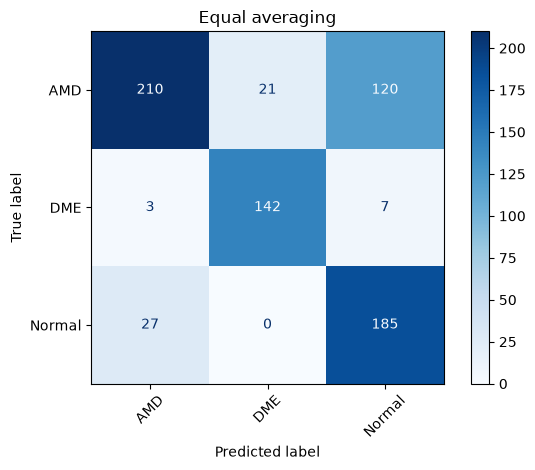


Confidence-aware weighting — classification report
              precision    recall  f1-score   support

         AMD       0.90      0.61      0.73       351
         DME       0.91      0.94      0.92       152
      Normal       0.60      0.90      0.72       212

    accuracy                           0.77       715
   macro avg       0.80      0.82      0.79       715
weighted avg       0.81      0.77      0.77       715



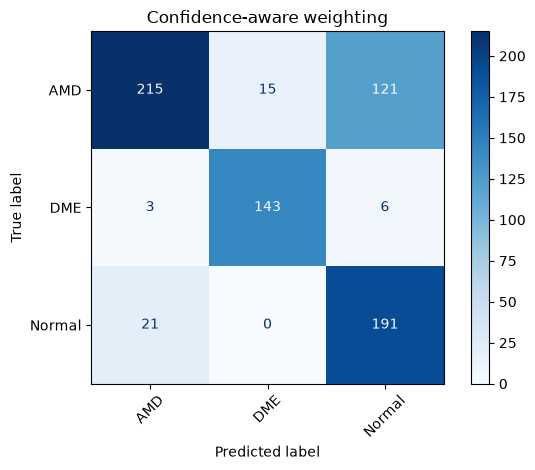


Saved results to camel_final_test_results.pt


In [45]:
import torch
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

ensemble_settings = torch.load(
    "camel_three_model_validation_results.pt",
    map_location="cpu",
    weights_only=True
)

model_settings = ensemble_settings["models"]

classification_weights = ensemble_settings["classification_weights"]
segmentation_weights = ensemble_settings["segmentation_weights"]

class_names = dataset.class_names

equal_classification_batches = []
weighted_classification_batches = []
equal_segmentation_batches = []
weighted_segmentation_batches = []

test_labels = []
test_masks = []
test_results = {}


def segmentation_scores(intersection, predicted_pixels, target_pixels):
    denominator = predicted_pixels + target_pixels
    union = denominator - intersection

    valid_classes = union > 0

    dice_scores = torch.full_like(intersection, float("nan"))
    iou_scores = torch.full_like(intersection, float("nan"))

    dice_scores[valid_classes] = (
        2 * intersection[valid_classes]
        / denominator[valid_classes]
    )

    iou_scores[valid_classes] = (
        intersection[valid_classes]
        / union[valid_classes]
    )

    return (
        dice_scores[valid_classes].mean().item(),
        iou_scores[valid_classes].mean().item(),
        dice_scores.tolist(),
        iou_scores.tolist()
    )


for model_index, (name, encoder_name, checkpoint_path) in enumerate(model_settings):
    model.cpu()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    model = CAMELModel(
        encoder_name=encoder_name
    ).to(device)

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    model.eval()

    correct = 0
    total = 0

    all_true_labels = []
    all_predictions = []

    intersection = torch.zeros(6, dtype=torch.float64)
    predicted_pixels = torch.zeros(6, dtype=torch.float64)
    target_pixels = torch.zeros(6, dtype=torch.float64)

    with torch.no_grad():
        for batch_index, (images, labels, masks) in enumerate(testloader):
            images = images.to(device)
            labels = labels.cpu()
            masks = masks.cpu()

            classification_output, segmentation_output = model(images)

            classification_probabilities = torch.softmax(
                classification_output, dim=1
            ).cpu()

            segmentation_probabilities = torch.softmax(
                segmentation_output, dim=1
            ).cpu()

            predicted_labels = classification_probabilities.argmax(dim=1)
            predicted_masks = segmentation_probabilities.argmax(dim=1)

            correct += (predicted_labels == labels).sum().item()
            total += labels.size(0)

            all_true_labels.extend(labels.tolist())
            all_predictions.extend(predicted_labels.tolist())

            for class_number in range(6):
                predicted_class = predicted_masks == class_number
                target_class = masks == class_number

                intersection[class_number] += (
                    predicted_class & target_class
                ).sum()

                predicted_pixels[class_number] += predicted_class.sum()
                target_pixels[class_number] += target_class.sum()

            if model_index == 0:
                test_labels.append(labels)
                test_masks.append(masks)

                equal_classification_batches.append(
                    classification_probabilities / len(model_settings)
                )

                weighted_classification_batches.append(
                    classification_weights[model_index]
                    * classification_probabilities
                )

                equal_segmentation_batches.append(
                    segmentation_probabilities / len(model_settings)
                )

                weighted_segmentation_batches.append(
                    segmentation_weights[model_index]
                    * segmentation_probabilities
                )

            else:
                assert torch.equal(labels, test_labels[batch_index])
                assert torch.equal(masks, test_masks[batch_index])

                equal_classification_batches[batch_index] += (
                    classification_probabilities / len(model_settings)
                )

                weighted_classification_batches[batch_index] += (
                    classification_weights[model_index]
                    * classification_probabilities
                )

                equal_segmentation_batches[batch_index] += (
                    segmentation_probabilities / len(model_settings)
                )

                weighted_segmentation_batches[batch_index] += (
                    segmentation_weights[model_index]
                    * segmentation_probabilities
                )

    mean_dice, mean_iou, class_dice, class_iou = segmentation_scores(
        intersection, predicted_pixels, target_pixels
    )

    test_results[name] = {
        "accuracy": 100 * correct / total,
        "mean_dice": mean_dice,
        "mean_iou": mean_iou,
        "class_dice": class_dice,
        "class_iou": class_iou,
        "true_labels": all_true_labels,
        "predictions": all_predictions
    }

    print(f"Finished test evaluation: {name}")


for name, classification_batches, segmentation_batches in [
    (
        "Equal averaging",
        equal_classification_batches,
        equal_segmentation_batches
    ),
    (
        "Confidence-aware weighting",
        weighted_classification_batches,
        weighted_segmentation_batches
    )
]:
    correct = 0
    total = 0

    all_true_labels = []
    all_predictions = []

    intersection = torch.zeros(6, dtype=torch.float64)
    predicted_pixels = torch.zeros(6, dtype=torch.float64)
    target_pixels = torch.zeros(6, dtype=torch.float64)

    for classification_probabilities, segmentation_probabilities, labels, masks in zip(
        classification_batches,
        segmentation_batches,
        test_labels,
        test_masks
    ):
        predicted_labels = classification_probabilities.argmax(dim=1)
        predicted_masks = segmentation_probabilities.argmax(dim=1)

        correct += (predicted_labels == labels).sum().item()
        total += labels.size(0)

        all_true_labels.extend(labels.tolist())
        all_predictions.extend(predicted_labels.tolist())

        for class_number in range(6):
            predicted_class = predicted_masks == class_number
            target_class = masks == class_number

            intersection[class_number] += (
                predicted_class & target_class
            ).sum()

            predicted_pixels[class_number] += predicted_class.sum()
            target_pixels[class_number] += target_class.sum()

    mean_dice, mean_iou, class_dice, class_iou = segmentation_scores(
        intersection, predicted_pixels, target_pixels
    )

    test_results[name] = {
        "accuracy": 100 * correct / total,
        "mean_dice": mean_dice,
        "mean_iou": mean_iou,
        "class_dice": class_dice,
        "class_iou": class_iou,
        "true_labels": all_true_labels,
        "predictions": all_predictions
    }


print("\nFinal test comparison:")

for name, results in test_results.items():
    print(
        f"{name} | "
        f"Accuracy: {results['accuracy']:.2f}% | "
        f"Dice: {results['mean_dice']:.4f} | "
        f"IoU: {results['mean_iou']:.4f}"
    )


for name in ["Equal averaging", "Confidence-aware weighting"]:
    results = test_results[name]

    print(f"\n{name} — classification report")

    print(classification_report(
        results["true_labels"],
        results["predictions"],
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    ))

    matrix = confusion_matrix(
        results["true_labels"],
        results["predictions"],
        labels=list(range(len(class_names)))
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=class_names
    ).plot(xticks_rotation=45, cmap="Blues")

    plt.title(name)
    plt.tight_layout()
    plt.show()


torch.save(
    {
        "results": test_results,
        "ensemble_settings": ensemble_settings
    },
    "camel_final_test_results.pt"
)

print("\nSaved results to camel_final_test_results.pt")

| Method | Test accuracy | Mean Dice | Mean IoU |
|---|---:|---:|---:|
| Original ResNet101 | 64.20% | 93.06% | 87.55% |
| Run 3 ResNet101 | 71.05% | 92.61% | 86.83% |
| EfficientNet-B0 | 75.66% | 91.02% | 84.15% |
| Equal averaging | 75.10% | **93.47%** | **88.23%** |
| Confidence-aware weighting | **76.78%** | 93.46% | 88.20% |

Next: verify the original-checkpoint discrepancy and freeze the exact split, checkpoints, and settings used for this evaluation.

### Debugging Check,  that we evaluated the same model correctly
test accuracyy 55.94% vs 64.20%

Earlier, we saw different accuracy values for the original model. So we checked it again.

- We loaded the saved original ResNet101 model.
- We tested it twice using the same 715 test images.
- Both times, we got exactly the same results:

| Metric | Both evaluations |
|---|---:|
| Classification accuracy | 64.20% |
| Segmentation Dice | 0.930585 |
| Segmentation IoU | 0.875497 |

We also saved a record of the model files, selected images, and settings. Each checkpoint gets a fingerprint so we can later check whether that file has changed.

**Conclusion:** This saved model consistently gives 64.20% test accuracy in these two checks. We still do not know why the earlier result was different. No training happened here—we only checked and recorded the results.

In [46]:
import hashlib
import json
from pathlib import Path
from datetime import datetime

import torch
import segmentation_models_pytorch as smp


def file_fingerprint(path):
    fingerprint = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            fingerprint.update(chunk)

    return fingerprint.hexdigest()


def split_fingerprint(subset):
    samples = [
        {
            "index": int(index),
            "paths": list(subset.dataset.samples[int(index)])
        }
        for index in subset.indices
    ]

    text = json.dumps(samples, sort_keys=True, default=str)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


checkpoint_paths = [
    "camel_resnet101_lr01_baseline.pt",
    "camel_run3_best_joint.pt",
    "camel_efficientnetB0_best_joint.pt"
]

checkpoint_details = {}

for checkpoint_path in checkpoint_paths:
    path = Path(checkpoint_path).resolve()

    checkpoint_details[checkpoint_path] = {
        "path": str(path),
        "sha256": file_fingerprint(path),
        "modified": datetime.fromtimestamp(
            path.stat().st_mtime
        ).isoformat()
    }

    print(f"\nCheckpoint: {path.name}")
    print("Location:", path)
    print("Last modified:", checkpoint_details[checkpoint_path]["modified"])
    print("Fingerprint:", checkpoint_details[checkpoint_path]["sha256"])


split_details = {}

for name, subset in [
    ("training", trainset),
    ("validation", validationset),
    ("test", testset)
]:
    split_details[name] = {
        "image_count": len(subset),
        "sha256": split_fingerprint(subset),
        "indices": [int(index) for index in subset.indices]
    }

    print(f"\n{name.capitalize()} images:", len(subset))
    print("Split fingerprint:", split_details[name]["sha256"])


print("\nTest sampler:", type(testloader.sampler).__name__)
print("Test batch size:", testloader.batch_size)

model.cpu()

if device.type == "cuda":
    torch.cuda.empty_cache()

model = CAMELModel(
    encoder_name="resnet101"
).to(device)

model.load_state_dict(
    torch.load(
        "camel_resnet101_lr01_baseline.pt",
        map_location=device,
        weights_only=True
    )
)

first_result = validation_metrics(testloader)
second_result = validation_metrics(testloader)

for name, result in [
    ("First evaluation", first_result),
    ("Second evaluation", second_result)
]:
    accuracy_value, dice_value, iou_value = result

    print(
        f"\n{name} | "
        f"Accuracy: {accuracy_value:.2f}% | "
        f"Dice: {dice_value:.6f} | "
        f"IoU: {iou_value:.6f}"
    )

matching_results = all(
    abs(first - second) < 1e-6
    for first, second in zip(first_result, second_result)
)

print("\nRepeated evaluations match:", matching_results)

audit = {
    "created": datetime.now().isoformat(),
    "torch_version": str(torch.__version__),
    "smp_version": str(smp.__version__),
    "device": str(device),
    "checkpoints": checkpoint_details,
    "splits": split_details,
    "test_batch_size": testloader.batch_size,
    "test_sampler": type(testloader.sampler).__name__,
    "metric_order": ["accuracy_percent", "mean_dice", "mean_iou"],
    "first_evaluation": first_result,
    "second_evaluation": second_result,
    "repeated_evaluations_match": matching_results
}

audit_path = Path(
    f"camel_evaluation_audit_{datetime.now():%Y%m%d_%H%M%S}.json"
)

with open(audit_path, "w", encoding="utf-8") as file:
    json.dump(audit, file, indent=2)

print("\nAudit saved:", audit_path.resolve())


Checkpoint: camel_resnet101_lr01_baseline.pt
Location: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_resnet101_lr01_baseline.pt
Last modified: 2026-10-22T21:10:34.393936
Fingerprint: e3b91e7ab73494d39236b3486c60649e78bc46676765b3d49ea3f97cd4dda5e1

Checkpoint: camel_run3_best_joint.pt
Location: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_run3_best_joint.pt
Last modified: 2026-10-22T22:12:12.403326
Fingerprint: b99fd80593c61fd15d66cf8eaf06394c55f977d2f9d4741a65b5ecedc7a119dc

Checkpoint: camel_efficientnetB0_best_joint.pt
Location: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_efficientnetB0_best_joint.pt
Last modified: 2026-10-22T23:08:10.877373
Fingerprint: 48aa7decbf3b05fa89437ab51794c737f14ff09e9b3f7cb6f8ec372df3393812

Training images: 833
Split fingerprint: 04352f181f31dc9f132ba3f0079c31a8c39668724d983d0f9849be67434c623f

Validation images: 124
Split fingerprint: 038dbb19bde5050ed0b02926d49d80b942ac95b99417

Finished predictions: Original ResNet101
Finished predictions: Run 3 ResNet101
Finished predictions: EfficientNet-B0


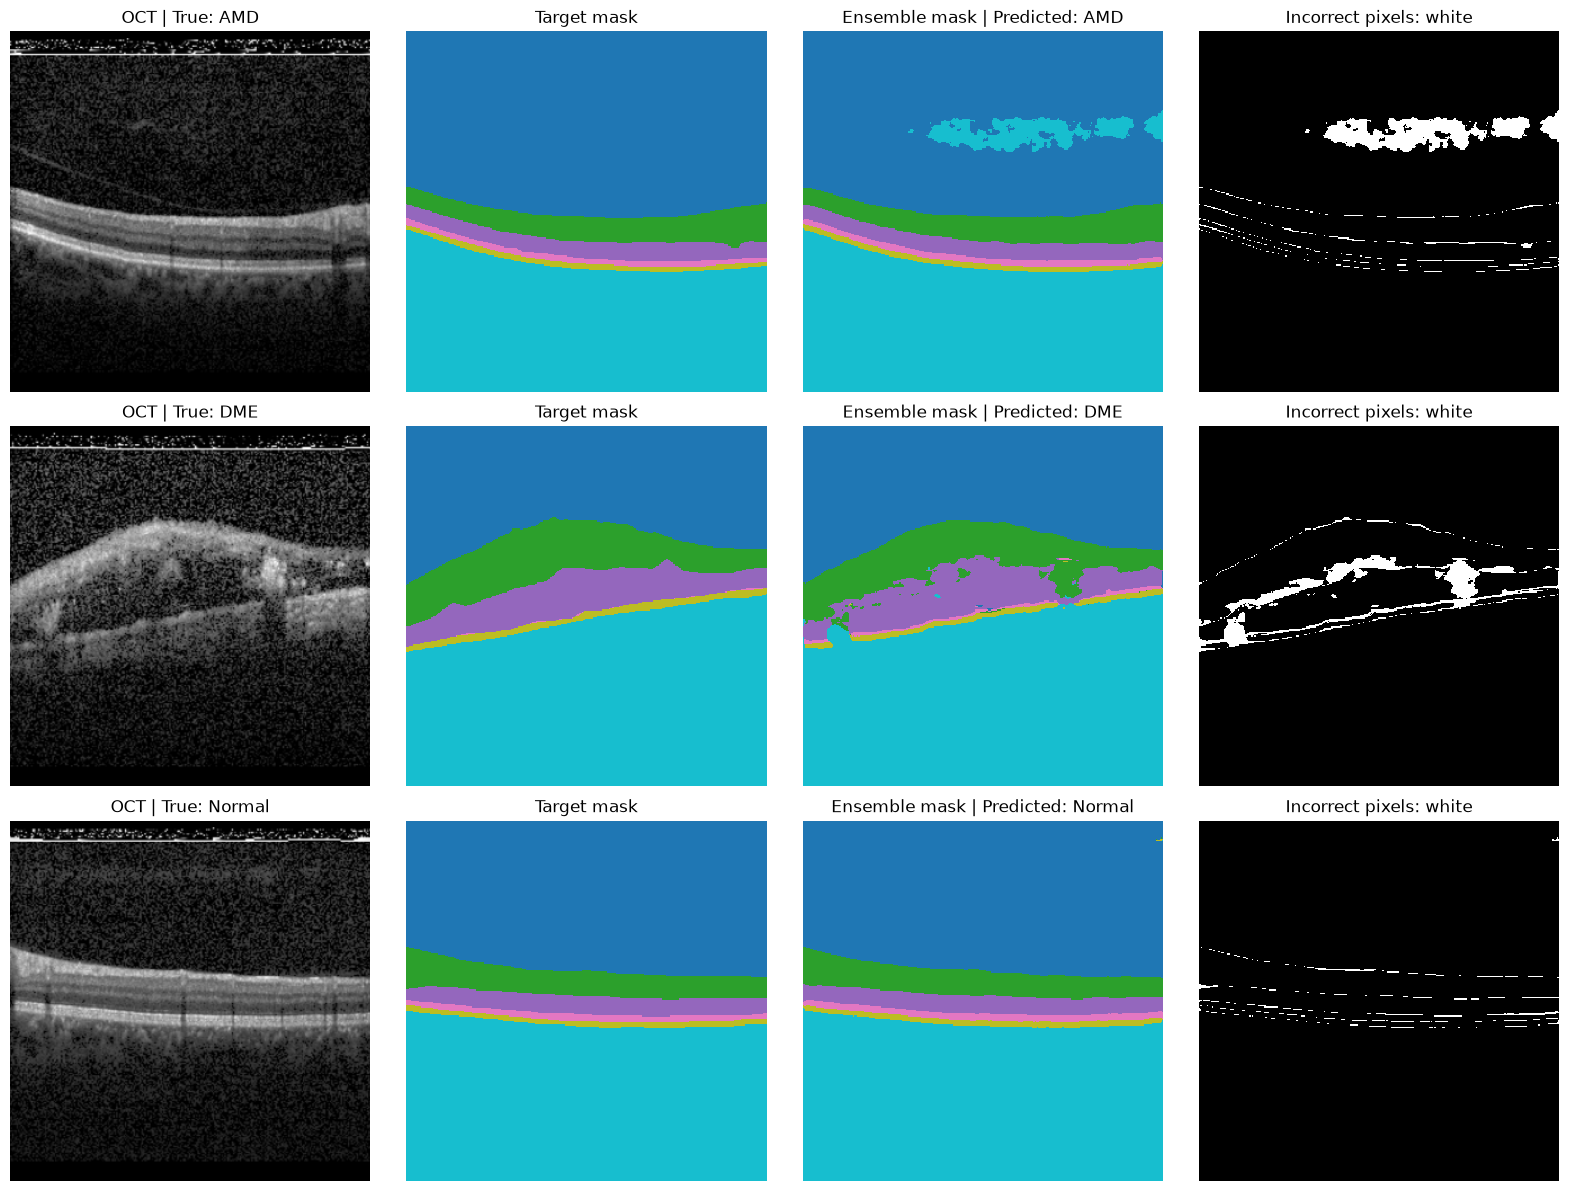

Saved figure: camel_ensemble_examples.png


CAMELModel(
  (network): Unet(
    (encoder): ResNetEncoder(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (relu): ReLU(i

In [ ]:
import torch
import matplotlib.pyplot as plt

settings = torch.load(
    "camel_three_model_validation_results.pt",
    map_location="cpu",
    weights_only=True
)

model_settings = settings["models"]
classification_weights = settings["classification_weights"]
segmentation_weights = settings["segmentation_weights"]

class_names = dataset.class_names

examples = {}

#selecting one example image  for each disease class from the test set, 
#that one is tested for segmentation also

for images, labels, masks in testloader: # test batches of 2 images each one by one
    for i in range(images.size(0)): # 2 images per batch, so i = 0, 1
        class_number = labels[i].item() #getting true label for the image

        if class_number not in examples:
            examples[class_number] = (
                images[i].cpu(), #whole image tensor
                masks[i].cpu() #320x320 target mask tensor
            )

    if len(examples) == len(class_names):
        break

if len(examples) != len(class_names):
    raise ValueError("The test loader did not contain every disease class.")

selected_classes = sorted(examples)  #[0, 1, 2]  # AMD, DME, Normal

selected_images = torch.stack([
    examples[class_number][0]
    for class_number in selected_classes
])

selected_masks = torch.stack([
    examples[class_number][1]
    for class_number in selected_classes
])

number_of_images = len(selected_classes)
height, width = selected_masks.shape[-2:]

classification_probabilities = torch.zeros(
    number_of_images, len(class_names) #shape (3, 3) for 3 images, 3 classes
)

segmentation_probabilities = torch.zeros(
    number_of_images, 6, height, width  #shape (3, 6, 320, 320) for 3 images, 6 classes, 320x320 pixels
)

model.cpu()

if device.type == "cuda":
    torch.cuda.empty_cache()

for model_index, (name, encoder_name, checkpoint_path) in enumerate(model_settings):
    member = CAMELModel(
        encoder_name=encoder_name
    ).to(device)

    member.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    )

    member.eval()

    with torch.no_grad():
        for i in range(number_of_images):
            image = selected_images[i:i + 1].to(device)

            classification_output, segmentation_output = member(image)

            classification_probabilities[i] += (
                classification_weights[model_index]
                * torch.softmax(classification_output, dim=1)[0].cpu()
            )

            # Original: [0.70, 0.20, 0.10] × 0.3779
            # Run 3:    [0.40, 0.40, 0.20] × 0.2355
            # B0:       [0.80, 0.10, 0.10] × 0.3865
            #                         ↓ summation
            # Ensemble = [0.668, 0.208, 0.124]
            #                         ↓
            #                        predicted as  AMD

            segmentation_probabilities[i] += (
                segmentation_weights[model_index]
                * torch.softmax(segmentation_output, dim=1)[0].cpu()
            )

    print("Finished predictions:", name)

    member.cpu()
    del member

    if device.type == "cuda":
        torch.cuda.empty_cache()

predicted_classes = classification_probabilities.argmax(dim=1)
predicted_masks = segmentation_probabilities.argmax(dim=1)

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

mask_colors = plt.get_cmap("tab10", 6) #selecting 6 colors

fig, axes = plt.subplots(
    number_of_images,
    4,
    figsize=(16, 4 * number_of_images),
    squeeze=False
)

for i, class_number in enumerate(selected_classes):
    image = (
        selected_images[i] * std + mean
    ).clamp(0, 1).mean(dim=0)

    # Normalized by:       z = (image − mean) / std
    # recovered original by reversing it:      image = z × std + mean

    true_disease = class_names[class_number]
    predicted_disease = class_names[predicted_classes[i].item()]

    errors = predicted_masks[i] != selected_masks[i]

    axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"OCT | True: {true_disease}")

    axes[i, 1].imshow(
        selected_masks[i],
        cmap=mask_colors,
        vmin=-0.5,
        vmax=5.5,
        interpolation="nearest"
    )
    axes[i, 1].set_title("Target mask")

    axes[i, 2].imshow(
        predicted_masks[i],
        cmap=mask_colors,
        vmin=-0.5,
        vmax=5.5,
        interpolation="nearest"
    )
    axes[i, 2].set_title(
        f"Ensemble mask | Predicted: {predicted_disease}"
    )

    axes[i, 3].imshow(
        errors,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )
    axes[i, 3].set_title("Incorrect pixels: white")

    for axis in axes[i]:
        axis.axis("off")

plt.tight_layout()

plt.savefig(
    "camel_ensemble_examples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Saved figure: camel_ensemble_examples.png")

model.to(device)
model.eval()

### This cell checks that:
- Images from the same scan stay in one split... training, validation, or test.
- Every image is included exactly once across the three splits.


It only checks the data setup. It does not train the model.

In [9]:
from pathlib import Path
import torch

print("Device:", device)
print("Disease classes:", dataset.class_names)
print("Total images:", len(dataset))

print("\nTraining images:", len(trainset))
print("Validation images:", len(validationset))
print("Test images:", len(testset))


def scan_groups(subset):
    group_names = set()

    for index in subset.indices:
        prepared_path, original_path = dataset.samples[int(index)]

        relative_path = Path(prepared_path).relative_to(
            "../Images/Images_Manual"
        )

            # earlier:
            # ../Images/Images_Manual/AMD Part1/AMD (1).E2E/session/Image 2.png

            # now:
            # AMD Part1/AMD (1).E2E/session/Image 2.png

        disease_name = relative_path.parts[0].split()[0]
        volume_name = relative_path.parts[1]
            # disease_name → "AMD"
            # volume_name  → "AMD (1).E2E"

        group_names.add((disease_name, volume_name))

    return group_names


train_groups = scan_groups(trainset)
validation_groups = scan_groups(validationset)
test_groups = scan_groups(testset)

#checks whether ("AMD", "AMD (1).E2E") scan grooup is in more than one of the splits, 
# which would be a data leakage problem
assert train_groups.isdisjoint(validation_groups)
assert train_groups.isdisjoint(test_groups)
assert validation_groups.isdisjoint(test_groups)

all_indices = (
    list(trainset.indices)
    + list(validationset.indices)
    + list(testset.indices)
)

assert sorted(all_indices) == list(range(len(dataset)))
#each dataset index has to appear in exactly one of the splits, 
# and all indices from 0 to len(dataset)-1 must be present

print("\nSplit check passed: no shared scan groups.")

images, labels, masks = next(iter(validationloader))

print("\nImage shape:", images.shape)
print("Disease label shape:", labels.shape)
print("Mask shape:", masks.shape)
print("Mask IDs in this batch:", torch.unique(masks).tolist())

Device: cuda
Disease classes: ['AMD', 'DME', 'Normal']
Total images: 1672

Training images: 833
Validation images: 124
Test images: 715

Split check passed: no shared scan groups.

Image shape: torch.Size([2, 3, 320, 320])
Disease label shape: torch.Size([2])
Mask shape: torch.Size([2, 320, 320])
Mask IDs in this batch: [0, 1, 2, 3, 4, 5]


this check determines how we should handle the segmentation classes in the reproduction loss.

In [26]:
from pathlib import Path

data_root = Path(data_root)

print("Dataset folder:", data_root)

readme_files = [
    path for path in data_root.iterdir()
    if path.is_file() and path.name.lower().startswith("readme")
]

for path in readme_files:
    print(f"\n--- {path.name} ---")
    print(path.read_text(encoding="utf-8", errors="replace"))

print("\nDataset scripts:")

scripts_folder = data_root / "Scripts"

for path in sorted(scripts_folder.rglob("*")):
    if path.is_file() and path.suffix.lower() in {
        ".py", ".m", ".ipynb", ".txt", ".md"
    }:
        print(path.relative_to(data_root))

Dataset folder: C:\Users\asus\Documents\OCT5k\OCT5k\OCT5k

--- README.txt ---
The dataset consists of five folders

1) "Images": Folder where the original images are downloaded by using the jupyter notebooks inside the Script folder. Images belonging to manual gradings and automatic gradings and also images in original resolution and format are downloaded.
2) "Masks" containting pixel-wise annotations with three manual gradings for 1672 images and 2924 masks with single automatic grading
3) "Boundaries" containing layers as CSV files for individual layers.
4) "Detection" containing CSV files for object detection labels.
and 5) "Scripts" containing jupyterlab notebooks to prepare the data (check README.txt inside).

The dataset covers semantic segmentation and object detection tasks.
For semantic segmentation the layers/bands included are ILM, OPL-Henles, IS/OS junction, IBRPE and OBRPE.
For object detection the labels cover choroidal folds, fluid, geographicatrophy, harddrusen, hyperfl

| Folder | What it includes? |
|---|---|
| `Images` | OCT images |
| `Masks` | Pixel-wise labels |
| `Boundaries` |  CSV files with Layer boundary positions  |
| `Detection` | Object-detection annotations |
| `Scripts` |notebooks that does  Data prepare/download   |

In [ ]:
import csv
import numpy as np
from PIL import Image

boundary_root = (
    data_root / "Boundaries" / "Boundaries_Manual" / "Grading_1"
)

boundary_path = next(boundary_root.rglob("*.csv"))
relative_path = boundary_path.relative_to(boundary_root)

#finding the mask corresponding to the same image as the boundary CSV file,
mask_path = (
    data_root / "Masks" / "Masks_Manual" / "Grading_1"
    / relative_path.with_suffix(".png")
)

with open(boundary_path, newline="") as file:
    boundary_rows = list(csv.DictReader(file))

mask = np.array(Image.open(mask_path))

print("Example:", relative_path)
print("Mask dimensions:", mask.shape)
print("Boundary columns:", list(boundary_rows[0]))
print("Number of boundary rows:", len(boundary_rows))

middle_row = boundary_rows[len(boundary_rows) // 2]   # 512//2 = 256
print("\nMiddle boundary entry:", middle_row)  # get the x=256 th column, middle column of the mask image

column = mask.shape[1] // 2  # get the same 256th column in mask
column_ids = mask[:, column] #fixing 256th column get all rows of that column, which is a 512x1 array of mask IDs

change_rows = np.flatnonzero(
    column_ids[1:] != column_ids[:-1] #compare each px with px above it, if they are different, 
    #that means a transition in mask ID, so get the row indices of those transitions
) + 1  #we add one to get where new segment id starts

print(f"\nMask transitions at column {column}:")
print(f"Starting ID: {column_ids[0]}")

for row in change_rows:
    print(
        f"Row {row}: "
        f"ID {column_ids[row - 1]} → ID {column_ids[row]}"  #row bears the change
    )

Example: AMD Part1\AMD (1).E2E\2- 25- 2017 9- 10- 42 PM\Image 10.csv
Mask dimensions: (512, 512)
Boundary columns: ['x', 'ILM', 'OPL', 'IS-OS', 'IBRPE', 'OBRPE']
Number of boundary rows: 512

Middle boundary entry: {'x': '256', 'ILM': '209', 'OPL': '270', 'IS-OS': '279', 'IBRPE': '280', 'OBRPE': '290'}

Mask transitions at column 256:
Starting ID: 0
Row 209: ID 0 → ID 1
Row 270: ID 1 → ID 2
Row 279: ID 2 → ID 3
Row 280: ID 3 → ID 4
Row 290: ID 4 → ID 5


### Understanding our segmentation targets

Dateset images looks black due to 0-5 pixel colors looks black, but bears segmentation label info


| Mask ID | Region in this example |
|---|---|
| 0 | Above ILM |
| 1 | Between ILM and OPL |
| 2 | Between OPL and IS/OS |
| 3 | Between IS/OS and IBRPE |
| 4 | Between IBRPE and OBRPE |
| 5 | Below OBRPE |

### Consistency check in Masks_Manual and Boundaries-> Boundaries_Manual which contains ground truth for same image set

In [ ]:
import csv
from pathlib import Path
import numpy as np
from PIL import Image

boundary_root = (
    data_root / "Boundaries" / "Boundaries_Manual" / "Grading_1"
)

mask_root = (
    data_root / "Masks" / "Masks_Manual" / "Grading_1"
)

boundary_names = ["ILM", "OPL", "IS-OS", "IBRPE", "OBRPE"]

checked_images = 0
matching_images = 0
checked_pixels = 0
matching_pixels = 0
issues = []

boundary_files = sorted(boundary_root.rglob("*.csv"))

for boundary_path in boundary_files:
    relative_path = boundary_path.relative_to(boundary_root)
    mask_path = mask_root / relative_path.with_suffix(".png")

    #finding png related to csv rom path suffix matching
    # CSV: .../AMD (1).E2E/session/Image 10.csv
    # PNG: .../AMD (1).E2E/session/Image 10.png

    if not mask_path.exists():
        issues.append((str(relative_path), "Mask missing"))
        continue

    mask = np.array(Image.open(mask_path))

    if mask.ndim != 2:
        issues.append((str(relative_path), "Mask is not a 2D ID mask"))
        continue

    # we need [h,w] if the mask is [h,w,3] we are skipping

    height, width = mask.shape

    try:
        with open(boundary_path, newline="") as file:
            rows = list(csv.DictReader(file))

        x_values = np.array(
            [float(row["x"]) for row in rows]
        ) #[0, 1, 2, ..., 511]

        boundaries = np.array([
            [float(row[name]) for name in boundary_names]
            for row in rows
        ]) #size [512, 5] for each column x=0 to x=511, we have 5 boundaries

        #               ILM  OPL  IS-OS  IBRPE  OBRPE
        # x = 0         ...  ...  ...    ...    ...
        # x = 1         ...  ...  ...    ...    ...
        # ...
        # x = 256       209  270  279    280    290

        if not (
            np.isfinite(x_values).all()
            and np.isfinite(boundaries).all()
        ):
            raise ValueError("Missing or non-finite coordinates")

        if not np.equal(x_values, np.floor(x_values)).all():
            raise ValueError("Non-integer x coordinates")

        x_values = x_values.astype(int)

        if len(x_values) != width or not np.array_equal(
            np.sort(x_values), np.arange(width)
        ):
            raise ValueError("CSV columns do not cover the mask width")

        boundaries = boundaries[np.argsort(x_values)]

        if np.any(np.diff(boundaries, axis=1) < 0):
            raise ValueError("Boundary order crosses in some columns")
        #influennced 66 files
        # Expected order: [209, 270, 279, 280, 290]
        # Differences:     [61,   9,   1,  10] → okayy

        # Problem column: [209, 270, 281, 280, 290]
        # Differences:     [61,  11,  -1,  10] → negative!

        if np.any(boundaries < 0) or np.any(boundaries > height):
            raise ValueError("Boundary coordinates outside mask height")

        if not np.isin(mask, np.arange(6)).all():
            raise ValueError("Mask contains IDs outside 0–5")

    except (ValueError, KeyError) as error:
        issues.append((str(relative_path), str(error)))
        continue

    expected_mask = np.zeros((height, width), dtype=np.uint8)


    pixel_rows = np.arange(height)[:, None]  
    # [[  0],
    # [  1],
    # [  2],
    # ...
    # [511]]

#numpy does this for whole columns, and boundary values taken from the CSV file available in dataset
    for boundary_number in range(5):
        expected_mask += (
            pixel_rows >= boundaries[:, boundary_number][None, :]
        ).astype(np.uint8)


# | Pixel row | passed boundaries | Expected ID |
#
# | 100 | not passed | 0 |
# | 230 | 209 | 1 |
# | 275 | 209, 270 | 2 |
# | 279 | 209, 270, 279 | 3 |
# | 285 | 209, 270, 279, 280 | 4 |
# | 350 | passed all | 5 |


    matches = mask == expected_mask

    checked_images += 1
    checked_pixels += mask.size
    matching_pixels += int(matches.sum())

    if matches.all():
        matching_images += 1
    else:
        agreement = 100 * matches.mean()
        issues.append((
            str(relative_path),
            f"Pixel agreement: {agreement:.4f}%"
        ))

    if checked_images % 200 == 0: #show progress every 200 images
        print(f"Checked {checked_images} images")

print("\nBoundary CSV files:", len(boundary_files))
print("Images checked:", checked_images)
print("Exactly matching images:", matching_images)

if checked_pixels:
    print(
        "Overall pixel agreement:",
        f"{100 * matching_pixels / checked_pixels:.6f}%"
    )

print("Files with mismatches or skipped checks:", len(issues))

for filename, reason in issues[:10]:
    print(filename, "|", reason)

Checked 200 images
Checked 400 images
Checked 600 images
Checked 800 images
Checked 1000 images
Checked 1200 images
Checked 1400 images
Checked 1600 images

Boundary CSV files: 1672
Images checked: 1606
Exactly matching images: 1606
Overall pixel agreement: 100.000000%
Files with mismatches or skipped checks: 66
AMD Part1\AMD (13).E2E\2- 25- 2017 4- 48- 43 PM\Image 30.csv | Boundary order crosses in some columns
AMD Part1\AMD (13).E2E\2- 25- 2017 4- 48- 43 PM\Image 33.csv | Boundary order crosses in some columns
AMD Part1\AMD (2).E2E\2- 25- 2017 9- 12- 39 PM\Image 15.csv | Boundary order crosses in some columns
AMD Part1\AMD (2).E2E\2- 25- 2017 9- 12- 39 PM\Image 4.csv | Boundary order crosses in some columns
AMD Part1\AMD (21).E2E\2- 25- 2017 5- 10- 29 PM\Image 40.csv | Boundary order crosses in some columns
AMD Part1\AMD (21).E2E\2- 25- 2017 5- 10- 29 PM\Image 54.csv | Boundary order crosses in some columns
AMD Part1\AMD (22).E2E\2- 25- 2017 5- 11- 45 PM\Image 33.csv | Boundary order

| Result | Meaning |
|---|---|
| 1,606 exact matches | Supports the six-region ID mapping |
| 66 skipped checks | Need separate inspection |
| 100% pixel agreement | Applies only to the 1,606 checked images |

In [29]:
from collections import Counter

reason_counts = Counter(reason for filename, reason in issues)

print("Audit issue summary:")

for reason, count in reason_counts.items():
    print(f"{count} files | {reason}")

Audit issue summary:
66 files | Boundary order crosses in some columns


### Considering skipped 66 files one by one

In [ ]:
crossing_results = []

#cosidering skipped files one by one
for filename, reason in issues:
    boundary_path = boundary_root / filename
    mask_path = mask_root / Path(filename).with_suffix(".png")

    with open(boundary_path, newline="") as file:
        rows = list(csv.DictReader(file))

    x_values = np.array([int(row["x"]) for row in rows])

    boundaries = np.array([
        [float(row[name]) for name in boundary_names]
        for row in rows
    ])
    #for each column x=0 to x=511, we get boundary heights in terms of rows
    #              ILM  OPL  IS-OS IBRPE OBRPE
    # column 0     ...  ...  ...   ...   ...
    # column 1     ...  ...  ...   ...   ...

    boundaries = boundaries[np.argsort(x_values)]

    #getting data from black image masks
    mask = np.array(Image.open(mask_path))

    height, width = mask.shape

    assert mask.ndim == 2
    assert np.array_equal(np.sort(x_values), np.arange(width))
    assert np.isfinite(boundaries).all()
    assert np.isin(mask, np.arange(6)).all()

    crossing_columns = np.any(  # identifies if boundaries were [ 10, 12, 45, 40,50] , 40<45 so wrong
        np.diff(boundaries, axis=1) < 0,
        axis=1
    )

    expected_mask = np.zeros_like(mask, dtype=np.uint8)
    pixel_rows = np.arange(height)[:, None]

    for boundary_number in range(5):
        expected_mask += (
            pixel_rows >= boundaries[:, boundary_number][None, :]
        ).astype(np.uint8)

# Boundaries: [49, 76, 98, 97, 114]
# Pixel row: 97 

# 97 >= 49  → 1
# 97 >= 76  → 1
# 97 >= 98  → 0
# 97 >= 97  → 1
# 97 >= 114 → 0
#              ──
# Expected ID  3  (though 3rd 1 is after a 0, we count all 1s, so 3 boundaries passed, so ID=3)

    mismatched_pixels = int((mask != expected_mask).sum())

#for each skipped file, we are checking how many columns have crossing boundaries 
# and how many pixels are mismatched between the mask and expected mask
    crossing_results.append({
        "file": filename,
        "crossing_columns": int(crossing_columns.sum()),
        "mismatched_pixels": mismatched_pixels,
        "total_pixels": mask.size
    })



exact_matches = sum(
    result["mismatched_pixels"] == 0
    for result in crossing_results
)

total_mismatches = sum(
    result["mismatched_pixels"]
    for result in crossing_results
)

total_pixels = sum(
    result["total_pixels"]
    for result in crossing_results
)


print("Previously skipped images:", len(crossing_results))
print("Exact region-count matches:", exact_matches)
print("Mismatched pixels:", total_mismatches)

if total_pixels:
    print(
        "Pixel agreement:",
        f"{100 * (1 - total_mismatches / total_pixels):.6f}%"
    )

    

print("\nFirst five examples:")

for result in crossing_results[:5]:

    print(
        
        result["file"],
        "| Crossing columns:", result["crossing_columns"],
        "| Mismatched pixels:", result["mismatched_pixels"]
    )


Previously skipped images: 66
Exact region-count matches: 0
Mismatched pixels: 4021
Pixel agreement: 99.976759%

First five examples:
AMD Part1\AMD (13).E2E\2- 25- 2017 4- 48- 43 PM\Image 30.csv | Crossing columns: 3 | Mismatched pixels: 3
AMD Part1\AMD (13).E2E\2- 25- 2017 4- 48- 43 PM\Image 33.csv | Crossing columns: 3 | Mismatched pixels: 3
AMD Part1\AMD (2).E2E\2- 25- 2017 9- 12- 39 PM\Image 15.csv | Crossing columns: 9 | Mismatched pixels: 9
AMD Part1\AMD (2).E2E\2- 25- 2017 9- 12- 39 PM\Image 4.csv | Crossing columns: 14 | Mismatched pixels: 145
AMD Part1\AMD (21).E2E\2- 25- 2017 5- 10- 29 PM\Image 40.csv | Crossing columns: 2 | Mismatched pixels: 2


### Segmentation-label audit

- 1,606 masks exactly matched the regions reconstructed from their boundary CSVs.
- Another 66 images contained crossing boundaries.
- These 66 masks differed from the simple reconstruction at 4,021 pixels
  (99.976759% pixel agreement).
- We retained the supplied masks without alteration.
- IDs 0–5 follow the top-to-bottom region ordering where boundaries do not cross.
- The precise mask-generation rule at crossing boundaries remains unverified.

In [31]:
import json
from pathlib import Path

audit_path = Path("camel_mask_audit.json")

mask_audit = {
    "total_images": 1672,
    "non_crossing_exact_matches": 1606,
    "crossing_images": len(crossing_results),
    "crossing_image_mismatched_pixels": int(total_mismatches),
    "crossing_image_total_pixels": int(total_pixels),
    "comparison": "Supplied masks versus boundary-count reconstruction",
    "decision": "Keep all supplied masks unchanged",
    "crossing_details": crossing_results
}

audit_path.write_text(
    json.dumps(mask_audit, indent=2),
    encoding="utf-8"
)

print("Audit saved:", audit_path.resolve())

Audit saved: C:\Users\asus\Documents\camel_mask_audit.json


### Losses and adaptive task weights

- Classification: cross-entropy.
- Segmentation: 0.5 × cross-entropy + 0.5 × pooled soft Dice loss.
- Dice excludes channel 0; cross-entropy includes all six classes.
- Initial β: 0.495.
- Training loss: (1−β) × classification + β × segmentation.
- Next β: segmentation loss / sum of both training losses.
- Validation uses fixed 0.5/0.5 task weights.

In [26]:
# EXPLICIT EXCLUDE-0 LOSS: avoids the old dice_loss definition
import torch
import torch.nn.functional as F


def camel_exclude0_dice_loss(segmentation_output, masks):
    probabilities = torch.softmax(segmentation_output, dim=1)

    targets = F.one_hot(
        masks,
        num_classes=segmentation_output.shape[1],
    ).permute(0, 3, 1, 2).float()

    # Exclude channel 0 explicitly; retain all image pixels.
    probabilities = probabilities[:, 1:]
    targets = targets[:, 1:]

    intersection = (probabilities * targets).sum()
    denominator = probabilities.sum() + targets.sum()

    return 1 - 2 * intersection / (denominator + 1e-7)


def calculate_losses(
    classification_output,
    segmentation_output,
    labels,
    masks,
    segmentation_weight,
):
    classification_loss = F.cross_entropy(
        classification_output, labels
    )

    # CE includes all six classes.
    segmentation_ce = F.cross_entropy(
        segmentation_output, masks
    )

    # Call the unique function directly.
    segmentation_dice = camel_exclude0_dice_loss(
        segmentation_output, masks
    )

    segmentation_loss = (
        0.5 * segmentation_ce
        + 0.5 * segmentation_dice
    )

    total_loss = (
        (1 - segmentation_weight) * classification_loss
        + segmentation_weight * segmentation_loss
    )

    return total_loss, classification_loss, segmentation_loss


def update_segmentation_weight(
    average_classification_loss,
    average_segmentation_loss,
):
    total = average_classification_loss + average_segmentation_loss
    return average_segmentation_loss / max(total, 1e-7)


print("Loss ready: CE includes all classes; Dice excludes channel 0.")

Loss ready: CE includes all classes; Dice excludes channel 0.


create a fresh ResNet101 model and check both outputs and the combined loss. This does not train or overwrite a saved checkpoint.

In [27]:
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Release the previous model from GPU memory, if present.
if "model" in globals():
    model.cpu()

model = CAMELModel(
    encoder_name="resnet101"
).to(device)

images, labels, masks = next(iter(trainloader))

images = images.to(device)
labels = labels.to(device)
masks = masks.to(device)

model.eval()

with torch.no_grad():
    classification_output, segmentation_output = model(images)



    total_loss, classification_loss, segmentation_loss = (
        calculate_losses(
            classification_output,
            segmentation_output,
            labels,
            masks,
            segmentation_weight = 0.495
        )
    )


#     Images 2
#    ├── Disease logits  [2,3]
#    └── Pixel logits   [2,6,320,320]
assert classification_output.shape == (images.size(0), 3)

assert segmentation_output.shape == (
    images.size(0), 6, masks.size(1), masks.size(2)
)



assert torch.isfinite(total_loss).item(), "Loss is not finite."

print("Classification output:", classification_output.shape)
print("Segmentation output:", segmentation_output.shape)

print(f"Classification loss: {classification_loss.item():.4f}")
print(f"Segmentation loss: {segmentation_loss.item():.4f}")
print(f"Combined loss: {total_loss.item():.4f}")

print("\nForward check passed. No training update performed.")

Classification output: torch.Size([2, 3])
Segmentation output: torch.Size([2, 6, 320, 320])
Classification loss: 1.7384
Segmentation loss: 1.4402
Combined loss: 1.5908

Forward check passed. No training update performed.


### Model 1 — ResNet101

| Setting | Value |
|---|---|
| SGD learning rate | 0.01 |
| Training | 20 epochs; adaptive task weights |
| Validation loss weights | 0.5 / 0.5 |
| Checkpoint selection | Highest validation joint score |
| Selected epoch | 17 |

LR 0.01, the fixed epoch budget and joint-score selection are our adaptations.

In [ ]:
# RESNET LR001: 20 EPOCHS WITH ALL CHECKPOINTS
import json
import time
from pathlib import Path
from datetime import datetime

import torch
import torch.nn.functional as F

required = [
    "CAMELModel",
    "camel_exclude0_dice_loss",
    "trainloader",
    "validationloader",
    "trainset",
    "validationset",
    "dataset",
    "device",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Run the setup/loss cells first: {missing}")

# selecting dice loss function to be used in training, here we are using the exclude0 version
run_dice_function = camel_exclude0_dice_loss


def run_losses(cls_output, seg_output, labels, masks):
    classification_loss = F.cross_entropy(cls_output, labels)

    segmentation_loss = (
        0.5 * F.cross_entropy(seg_output, masks)
        + 0.5 * run_dice_function(seg_output, masks)
    )

    return classification_loss, segmentation_loss


project_folder = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
)

run_folder = project_folder / (
    "camel_resnet101_exclude0_lr001_20epochs_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
#every run will have a unique folder name based on timestamp 
#ex: camel_resnet101_exclude0_lr001_20epochs_20261118_...

run_folder.mkdir(parents=True, exist_ok=False)
epoch_folder = run_folder / "epoch_checkpoints"
epoch_folder.mkdir()

epochs = 20
learning_rate = 0.01
seed = 42
beta = 0.495 #intial segmentation weight, 
# beta will be updated after each epoch based on training losses

torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

    #setting seeds for random initialization and random dropouts

trainloader.sampler.generator = torch.Generator().manual_seed(seed)
#seeds control the shuffle order of training images


torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

if "model" in globals():
    model.cpu()

model = CAMELModel(encoder_name="resnet101").to(device)
#creating a new model

optimizer2 = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate,
    momentum=0.0,
)
#by default, camel encoder gets pretrained weights from ImageNet, 
# so we are using SGD optimizer with learning rate 0.01 and momentum 0.0
#transfer learning - fine tuning the pretrained model on our dataset

config = {
    "encoder_name": "resnet101",
    "learning_rate": learning_rate,
    "momentum": 0.0,
    "seed": seed,
    "training_shuffle_seed": seed,
    "epochs": epochs,
    "early_stopping": False,
    "batch_size": trainloader.batch_size,
    "dice_excludes_class_zero": True,
    "initial_beta": beta,
    "validation_weights": [0.5, 0.5],
    "joint_score": "0.5 * accuracy_fraction + 0.5 * mean_iou",
    "class_names": list(dataset.class_names),
    "train_indices": [int(i) for i in trainset.indices],
    "validation_indices": [int(i) for i in validationset.indices],
}

#saving to a dictionary in json format, so that we can use it later for reference
(run_folder / "config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8",
)

best_loss = float("inf")
best_joint = -float("inf")
best_loss_epoch = 0
best_joint_epoch = 0
history = []

print("New run:", run_folder)
print("ResNet101 | LR 0.01 | Exclude-0 Dice | 20 epochs")
print("Joint-score selection is our approach.")

training_start = time.perf_counter()

for epoch in range(1, epochs + 1):
    epoch_start = time.perf_counter()
    model.train()

    train_cls_sum = 0.0
    train_seg_sum = 0.0
    train_correct = 0
    train_count = 0

    #for onr traning batch
    for images, labels, masks in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        optimizer2.zero_grad(set_to_none=True) #clearing previous batch gradients

        cls_output, seg_output = model(images)
        # Classification logits: [batch, 3]
        # Segmentation logits:   [batch, 6, 320, 320]

        cls_loss, seg_loss = run_losses(
            cls_output, seg_output, labels, masks
        )

        loss = (1 - beta) * cls_loss + beta * seg_loss

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite training loss.")
        #stopping if loss is inf or NaN

        loss.backward() #backpropagation to compute gradients
        optimizer2.step() #thereby updating the model weights

        count = images.size(0)
        train_count += count #for batch of 2, count=2, so train_count will be incremented by 2
        train_cls_sum += cls_loss.item() * count
        train_seg_sum += seg_loss.item() * count
        train_correct += cls_output.argmax(1).eq(labels).sum().item()
        #comparing max with true labels,deciding whether correct, if correct add

    train_cls = train_cls_sum / train_count
    train_seg = train_seg_sum / train_count

    model.eval() # in eval mode drop out is off

    val_cls_sum = 0.0
    val_seg_sum = 0.0
    val_correct = 0
    val_count = 0

    intersection = torch.zeros(6, device=device, dtype=torch.float64)
    predicted_pixels = torch.zeros_like(intersection)
    target_pixels = torch.zeros_like(intersection)

    with torch.no_grad():
        for images, labels, masks in validationloader:
            images = images.to(device)
            labels = labels.to(device)
            masks = masks.to(device)

            cls_output, seg_output = model(images)
            cls_loss, seg_loss = run_losses(
                cls_output, seg_output, labels, masks
            )

            if not (
                torch.isfinite(cls_loss).item()
                and torch.isfinite(seg_loss).item()
            ):
                raise RuntimeError("Non-finite validation loss.")

            count = images.size(0)
            val_count += count
            val_cls_sum += cls_loss.item() * count
            val_seg_sum += seg_loss.item() * count
            val_correct += cls_output.argmax(1).eq(labels).sum().item()

            predicted_masks = seg_output.argmax(dim=1)
            #for 2 images in batch, predicted_masks will be [2, 320, 320] with values from 0 to 5

            for class_id in range(6):
                #for each class in 2 images, we are checking how many pixels are predicted
                #  and how many are actual
                predicted = predicted_masks.eq(class_id)
                actual = masks.eq(class_id)

                intersection[class_id] += (predicted & actual).sum() #tp
                predicted_pixels[class_id] += predicted.sum()  # tp + fp
                target_pixels[class_id] += actual.sum()    #tp+fn

    val_cls = val_cls_sum / val_count
    val_seg = val_seg_sum / val_count

    # Keep validation loss weights fixed across epochs.
    val_loss = 0.5 * val_cls + 0.5 * val_seg
    val_accuracy = 100 * val_correct / val_count

    denominator = predicted_pixels + target_pixels
    union = denominator - intersection
    valid = union > 0

    val_dice = (
        2 * intersection[valid] / denominator[valid]
    ).mean().item()

    val_iou = (
        intersection[valid] / union[valid]
    ).mean().item()

    joint_score = 0.5 * (val_accuracy / 100) + 0.5 * val_iou

    next_beta = train_seg / max(train_cls + train_seg, 1e-7)

    row = {
        "epoch": epoch,
        "segmentation_weight": beta,
        "next_segmentation_weight": next_beta,
        "train_classification_loss": train_cls,
        "train_segmentation_loss": train_seg,
        "train_loss": (1 - beta) * train_cls + beta * train_seg,
        "train_accuracy": 100 * train_correct / train_count,
        "validation_classification_loss": val_cls,
        "validation_segmentation_loss": val_seg,
        "validation_loss": val_loss,
        "validation_accuracy": val_accuracy,
        "validation_dice": val_dice,
        "validation_iou": val_iou,
        "validation_joint_score": joint_score,
    }

    # Save every epoch so later comparisons retain the actual weights.
    checkpoint = {
        "model_state_dict": {
            name: tensor.detach().cpu()
            for name, tensor in model.state_dict().items()
        },
        "encoder_name": "resnet101",
        "learning_rate": learning_rate,
        "dice_excludes_class_zero": True,
        "config": config,
        **row,
    }

    torch.save(
        checkpoint,
        epoch_folder / f"epoch_{epoch:03d}.pt",
    )

    if val_loss < best_loss:
        best_loss = val_loss
        best_loss_epoch = epoch
        torch.save(checkpoint, run_folder / "best_loss.pt")

    if joint_score > best_joint:
        best_joint = joint_score
        best_joint_epoch = epoch
        torch.save(checkpoint, run_folder / "best_joint.pt")

    del checkpoint

    row["seconds"] = time.perf_counter() - epoch_start
    history.append(row)

    (run_folder / "history.json").write_text(
        json.dumps(history, indent=2),
        encoding="utf-8",
    )

    print(
        f"Epoch {epoch}/{epochs} | β: {beta:.3f} | "
        f"Train Acc: {row['train_accuracy']:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Dice: {val_dice:.4f} | IoU: {val_iou:.4f} | "
        f"Joint: {joint_score:.4f} | "
        f"Time: {row['seconds']:.0f}s"
    )

    beta = next_beta

print(
    f"\nTraining time: "
    f"{(time.perf_counter() - training_start) / 60:.2f} minutes"
)

for filename, title in [
    ("best_loss.pt", "Lowest validation loss"),
    ("best_joint.pt", "Highest validation joint score"),
]:
    selected = torch.load(
        run_folder / filename,
        map_location="cpu",
        weights_only=True,
    )

    print(f"\n{title}:")
    print("Epoch:", selected["epoch"])
    print(f"Accuracy: {selected['validation_accuracy']:.2f}%")
    print(f"Dice: {selected['validation_dice']:.4f}")
    print(f"IoU: {selected['validation_iou']:.4f}")
    print(f"Joint: {selected['validation_joint_score']:.4f}")

    del selected

# Leave the selected joint model ready for later validation checks.
selected = torch.load(
    run_folder / "best_joint.pt",
    map_location="cpu",
    weights_only=True,
)
model.load_state_dict(selected["model_state_dict"])
model.eval()
del selected

print("\nAll results saved:", run_folder)

New run: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_resnet101_exclude0_lr001_20epochs_20261118_190547_808191
ResNet101 | LR 0.01 | Exclude-0 Dice | 20 epochs
Joint-score selection is our adaptation.
Epoch 1/20 | β: 0.495 | Train Acc: 57.74% | Val Loss: 0.3121 | Val Acc: 84.68% | Dice: 0.5733 | IoU: 0.5148 | Joint: 0.6808 | Time: 44s
Epoch 2/20 | β: 0.255 | Train Acc: 74.19% | Val Loss: 0.9224 | Val Acc: 62.10% | Dice: 0.6053 | IoU: 0.5598 | Joint: 0.5904 | Time: 42s
Epoch 3/20 | β: 0.162 | Train Acc: 86.43% | Val Loss: 0.3896 | Val Acc: 78.23% | Dice: 0.6067 | IoU: 0.5581 | Joint: 0.6702 | Time: 44s
Epoch 4/20 | β: 0.231 | Train Acc: 91.48% | Val Loss: 0.4257 | Val Acc: 75.81% | Dice: 0.6928 | IoU: 0.6169 | Joint: 0.6875 | Time: 44s
Epoch 5/20 | β: 0.310 | Train Acc: 97.00% | Val Loss: 0.3662 | Val Acc: 83.06% | Dice: 0.7713 | IoU: 0.6926 | Joint: 0.7616 | Time: 45s
Epoch 6/20 | β: 0.482 | Train Acc: 99.16% | Val Loss: 0.3323 | Val Acc: 85.48% | Dice: 0.8399 

### ResNet checkpoint comparison

| Validation metric | Lowest loss — epoch 1 | Best joint — epoch 17 |
|---|---:|---:|
| Accuracy | 84.68% | 84.68% |
| Dice | 0.5733 | 0.9232 |
| IoU | 0.5148 | 0.8643 |

Epoch 17 retained classification accuracy and improved segmentation.

### New Experiment - validation test

In [21]:
# RESNET LR001 VALIDATION LOSS BREAKDOWN
from pathlib import Path
import torch
import torch.nn.functional as F

checkpoint_path = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    r"\camel_resnet101_dice_exclude0_lr001_20261118_163333_264035"
    r"\best_model.pt"
)

# Load the selected model.
if "model" in globals():
    model.cpu()

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

diagnostic_model = CAMELModel(encoder_name="resnet101")
diagnostic_model.load_state_dict(checkpoint["model_state_dict"])
diagnostic_model = diagnostic_model.to(device)
diagnostic_model.eval()

loss_sums = {
    "classification_ce": 0.0,
    "segmentation_ce": 0.0,
    "soft_dice_loss": 0.0,
}

intersection = torch.zeros(6, dtype=torch.float64)
predicted_pixels = torch.zeros_like(intersection)
target_pixels = torch.zeros_like(intersection)

image_count = 0
correct = 0

with torch.no_grad():
    for images, labels, masks in validationloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        cls_output, seg_output = diagnostic_model(images)

        classification_ce = F.cross_entropy(cls_output, labels)
        segmentation_ce = F.cross_entropy(seg_output, masks)

        probabilities = torch.softmax(seg_output, dim=1)
        target = F.one_hot(
            masks, num_classes=6
        ).permute(0, 3, 1, 2).float()

        # Match this run: exclude channel 0 from Dice only.
        probabilities = probabilities[:, 1:]
        target = target[:, 1:]

        soft_dice_loss = 1 - (
            2 * (probabilities * target).sum()
            / (probabilities.sum() + target.sum() + 1e-7)
        )

        batch_size = images.size(0)
        image_count += batch_size

        loss_sums["classification_ce"] += (
            classification_ce.item() * batch_size
        )
        loss_sums["segmentation_ce"] += (
            segmentation_ce.item() * batch_size
        )
        loss_sums["soft_dice_loss"] += (
            soft_dice_loss.item() * batch_size
        )

        correct += cls_output.argmax(dim=1).eq(labels).sum().item()
        predicted_masks = seg_output.argmax(dim=1)

        # Evaluation includes all six mask classes.
        for class_id in range(6):
            predicted = predicted_masks.eq(class_id)
            actual = masks.eq(class_id)

            intersection[class_id] += (
                (predicted & actual).sum().item()
            )
            predicted_pixels[class_id] += predicted.sum().item()
            target_pixels[class_id] += actual.sum().item()

averages = {
    name: value / image_count
    for name, value in loss_sums.items()
}

combined_loss = (
    0.5 * averages["classification_ce"]
    + 0.25 * averages["segmentation_ce"]
    + 0.25 * averages["soft_dice_loss"]
)

union = predicted_pixels + target_pixels - intersection
valid = union > 0

ious = torch.full_like(union, float("nan"))
ious[valid] = intersection[valid] / union[valid]

print("Selected epoch:", checkpoint["epoch"])
print("Validation images:", image_count)
print(f"Classification accuracy: {100 * correct / image_count:.2f}%")

print("\nLoss breakdown:")
print(f"Classification CE: {averages['classification_ce']:.6f}")
print(f"Segmentation CE:   {averages['segmentation_ce']:.6f}")
print(f"Soft Dice loss:    {averages['soft_dice_loss']:.6f}")

print("\nContributions to combined validation loss:")
print(f"0.50 × Classification CE: {0.5 * averages['classification_ce']:.6f}")
print(f"0.25 × Segmentation CE:   {0.25 * averages['segmentation_ce']:.6f}")
print(f"0.25 × Soft Dice loss:    {0.25 * averages['soft_dice_loss']:.6f}")

print(f"\nRecomputed combined loss: {combined_loss:.6f}")
print(f"Saved combined loss:      {checkpoint['validation_loss']:.6f}")

print("\nClass | Target pixel share | IoU")
for class_id in range(6):
    share = 100 * target_pixels[class_id] / target_pixels.sum()
    print(
        f"{class_id:5d} | {share.item():17.2f}% | "
        f"{ious[class_id].item():.4f}"
    )

print(f"\nMean IoU: {ious[valid].mean().item():.4f}")

diagnostic_model.cpu()
del diagnostic_model, checkpoint

if device.type == "cuda":
    torch.cuda.empty_cache()

Selected epoch: 3
Validation images: 124
Classification accuracy: 90.32%

Loss breakdown:
Classification CE: 0.217090
Segmentation CE:   0.188090
Soft Dice loss:    0.118193

Contributions to combined validation loss:
0.50 × Classification CE: 0.108545
0.25 × Segmentation CE:   0.047022
0.25 × Soft Dice loss:    0.029548

Recomputed combined loss: 0.185116
Saved combined loss:      0.177896

Class | Target pixel share | IoU
    0 |             32.86% | 0.9567
    1 |              7.67% | 0.7609
    2 |              6.83% | 0.6381
    3 |              1.54% | 0.2289
    4 |              1.62% | 0.0923
    5 |             49.48% | 0.9559

Mean IoU: 0.6055


Lets see whether include or exclude 0 is bettter

In [ ]:

from pathlib import Path
import torch
import torch.nn.functional as F

path = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    # r"\camel_resnet101_dice_exclude0_lr001_20261118_163333_264035"
    r"\camel_resnet101_dice_exclude0_lr001_20261118_183318_843809"
    r"\best_model.pt"
)

checkpoint = torch.load(
    path, map_location="cpu", weights_only=True
)

if "model" in globals():
    model.cpu()

check_model = CAMELModel(encoder_name="resnet101")
check_model.load_state_dict(checkpoint["model_state_dict"])
check_model = check_model.to(device)
check_model.eval()

loss_sums = {"include0": 0.0, "exclude0": 0.0}
total_images = 0

with torch.no_grad():
    for images, labels, masks in validationloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        cls_output, seg_output = check_model(images)

        cls_ce = F.cross_entropy(cls_output, labels)
        seg_ce = F.cross_entropy(seg_output, masks)

        probabilities = torch.softmax(seg_output, dim=1)
        targets = F.one_hot(
            masks, num_classes=6
        ).permute(0, 3, 1, 2).float()

        # Evaluate both Dice definitions on identical predictions.
        for variant, first_channel in [
            ("include0", 0),
            ("exclude0", 1),
        ]:
            p = probabilities[:, first_channel:]
            y = targets[:, first_channel:]

            dice_loss_value = 1 - (
                2 * (p * y).sum()
                / (p.sum() + y.sum() + 1e-7)
            )

            combined_loss = (
                0.5 * cls_ce
                + 0.25 * seg_ce
                + 0.25 * dice_loss_value
            )

            loss_sums[variant] += (
                combined_loss.item() * images.size(0)
            )

        total_images += images.size(0)

saved_loss = float(checkpoint["validation_loss"])

print("Checkpoint epoch:", checkpoint["epoch"])
print(
    "Recorded exclude-0 flag:",
    checkpoint.get("dice_excludes_class_zero", "Not recorded"),
)
print(f"\nSaved validation loss: {saved_loss:.8f}")

for variant, loss_sum in loss_sums.items():
    calculated = loss_sum / total_images
    difference = abs(calculated - saved_loss)

    print(
        f"{variant:8s} | Loss: {calculated:.8f} | "
        f"Difference: {difference:.8f} | "
        f"Matches: {difference < 1e-5}"
    )

check_model.cpu()
del check_model, checkpoint

if device.type == "cuda":
    torch.cuda.empty_cache()

Checkpoint epoch: 1
Recorded exclude-0 flag: True

Saved validation loss: 0.31210054
include0 | Loss: 0.30287705 | Difference: 0.00922349 | Matches: False
exclude0 | Loss: 0.31210054 | Difference: 0.00000000 | Matches: True


<!-- ### Adaptive-weight training: result

- Training stopped after **9 epochs**: validation loss did not improve for 7 consecutive epochs.
- **Epoch 2** was saved because it had the lowest fixed validation loss.

| Validation metric | Selected epoch 2 | Epoch 7 |
|---|---:|---:|
| Loss ↓ | **0.7987** | 1.0006 |
| Classification accuracy ↑ | 54.84% | **75.00%** |
| Mean Dice ↑ | 0.8857 | **0.9155** |
| Mean IoU ↑ | 0.8052 | **0.8523** | -->


### Adaptive ResNet101 — updated training result (old lr 0.1)

- Training stopped after 20 epochs.
- Epoch 13 was saved because it had the lowest fixed validation loss.
- Epochs 14–20 did not improve that loss, so early stopping triggered.

| Selected checkpoint metric | Value |
|---|---:|
| Epoch | 13 |
| Validation loss | 0.3348 |
| Classification accuracy | 70.97% |
| Segmentation Dice | 0.9028 |
| Segmentation IoU | 0.8308 |

### Adaptive ResNet101 — updated training result (new lr 0.01)
| Validation metric | Selected epoch 1 | last epoch 8 |
|---|---:|---:|
| Accuracy | **84.68%** | 79.03% |
| IoU | 0.5148 | **0.8299** |

### What this tells us (old lr 0.1)

- Lower loss did **not** select the epoch with the best accuracy or segmentation.
- Cross-entropy considers prediction confidence; accuracy counts correct predictions.
- Segmentation weight β fell from **0.495 to approximately 0.03–0.04**.
- Classification consequently received approximately **96–97% of the explicit task weight**.
- This run did **not demonstrate an improvement** over our earlier models.

### Relationship to CAMEL

- Training used a **two-task adaptation** of the released code’s loss-ratio update.
- Fixed validation weights were our correction for comparing epochs consistently.
- This experiment is **not an exact reproduction of the authors’ OCT5k training protocol**.



In [29]:
# TEST THE SELECTED RESNET LR001 JOINT CHECKPOINT
import json
from pathlib import Path
from datetime import datetime
import torch

selected_run = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    r"\camel_resnet101_exclude0_lr001_20epochs_20261118_190547_808191"
)

checkpoint_path = selected_run / "best_joint.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

# Load the checkpoint selected using validation only.
if "model" in globals():
    model.cpu()

model = CAMELModel(encoder_name="resnet101")
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Loaded:", checkpoint_path)
print("Selected epoch:", checkpoint["epoch"])
print(
    "Saved validation accuracy:",
    f"{checkpoint['validation_accuracy']:.2f}%"
)
print(
    "Saved validation IoU:",
    f"{checkpoint['validation_iou']:.4f}"
)

# Reuse our existing evaluation function from cell 40.
test_accuracy, test_dice, test_iou = validation_metrics(testloader)

print("\nResNet LR001 — test results:")
print(f"Accuracy: {test_accuracy:.2f}%")
print(f"Mean Dice: {test_dice:.4f}")
print(f"Mean IoU: {test_iou:.4f}")

results = {
    "checkpoint": str(checkpoint_path),
    "selected_epoch": int(checkpoint["epoch"]),
    "selection_rule": "highest validation joint score",
    "test_image_count": len(testloader.dataset),
    "test_accuracy_percent": test_accuracy,
    "test_mean_dice": test_dice,
    "test_mean_iou": test_iou,
    "test_indices": [
        int(index) for index in testloader.dataset.indices
    ],
}

result_path = selected_run / (
    f"joint_test_results_{datetime.now():%Y%m%d_%H%M%S_%f}.json"
)

with open(result_path, "w", encoding="utf-8") as file:
    json.dump(results, file, indent=2)

print("\nSaved:", result_path)
del checkpoint

Loaded: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_resnet101_exclude0_lr001_20epochs_20261118_190547_808191\best_joint.pt
Selected epoch: 17
Saved validation accuracy: 84.68%
Saved validation IoU: 0.8643

ResNet LR001 — test results:
Accuracy: 65.31%
Mean Dice: 0.9274
Mean IoU: 0.8709

Saved: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_resnet101_exclude0_lr001_20epochs_20261118_190547_808191\joint_test_results_20261118_195039_582010.json




### New ResNet: test results

| Model | Accuracy ↑ | Dice ↑ | IoU ↑ |
|---|---:|---:|---:|
| B0 | **76.36%** | 0.9264 | 0.8684 |
| ResNet — epoch 17 | 65.31% | **0.9274** | **0.8709** |

- ResNet has slightly better segmentation.
- Its classification accuracy is **11.05 percentage points lower** than B0.
- ResNet accuracy drops from **84.68% on validation to 65.31% on test**, showing a generalization gap.
- Neither model is best at both tasks.


### Next step

Inspect the separate task losses and verify the weighting implementation before further training GETTING THE SAVED HISTORY.

**Checkpoint note:** All 20 epoch checkpoints were saved. Epoch 17 was selected by
validation joint score; epoch 1 had the lowest validation loss.

Reading history: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_resnet101_exclude0_lr001_20epochs_20261118_190547_808191\history.json
Epoch | Classification loss | Segmentation loss | Actual β | Expected β
    1 |              1.0760 |            0.3680 |   0.4950 |     0.4950
    2 |              0.7058 |            0.1368 |   0.2548 |     0.2548
    3 |              0.3788 |            0.1140 |   0.1624 |     0.1624
    4 |              0.2243 |            0.1008 |   0.2313 |     0.2313
    5 |              0.0905 |            0.0843 |   0.3100 |     0.3100
    6 |              0.0234 |            0.0693 |   0.4821 |     0.4821
    7 |              0.0182 |            0.0544 |   0.7472 |     0.7472
    8 |              0.0077 |            0.0439 |   0.7490 |     0.7490
    9 |              0.0061 |            0.0381 |   0.8501 |     0.8501
   10 |              0.0047 |            0.0344 |   0.8614 |     0.8614
   11 |              0.0063 |            0.0320 |  

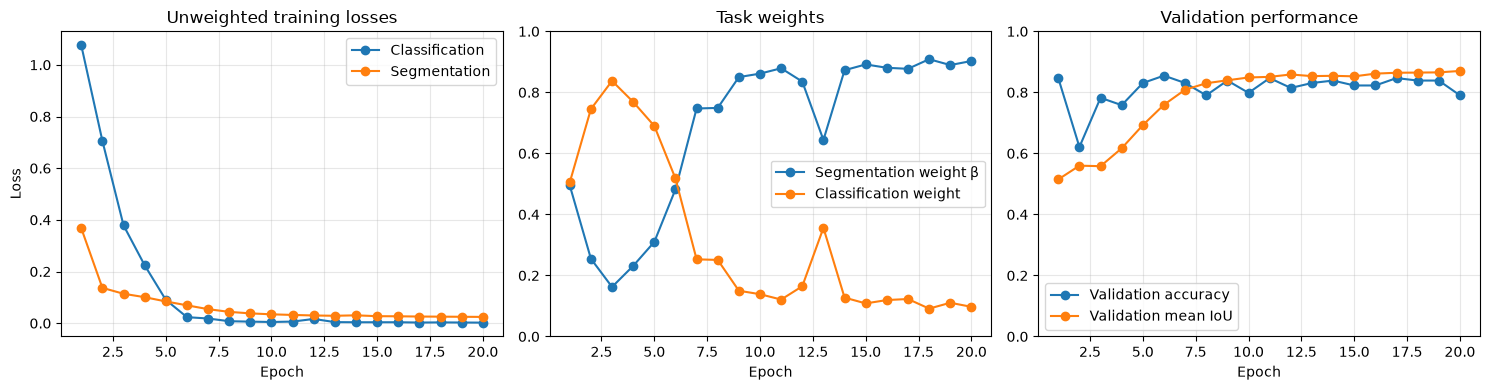

In [30]:
import json
import matplotlib.pyplot as plt

# history_path = run_folder / "history.json"

from pathlib import Path

diagnostic_run = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    r"\camel_resnet101_exclude0_lr001_20epochs_20261118_190547_808191"
)

history_path = diagnostic_run / "history.json"
print("Reading history:", history_path)

with open(history_path, encoding="utf-8") as file:
    history = json.load(file)

epoch_numbers = [row["epoch"] for row in history]
classification_losses = [
    row["train_classification_loss"] for row in history
]
segmentation_losses = [
    row["train_segmentation_loss"] for row in history
]
segmentation_weights = [
    row["segmentation_weight"] for row in history
]

print(
    "Epoch | Classification loss | Segmentation loss | "
    "Actual β | Expected β"
)

for index, row in enumerate(history):
    if index == 0:
        expected_beta = 0.495
    else:
        previous = history[index - 1]

        expected_beta = ( # Calculate expected β based on previous epoch's losses
            previous["train_segmentation_loss"]
            / max(
                previous["train_classification_loss"]
                + previous["train_segmentation_loss"],
                1e-7
            )
        )

    actual_beta = row["segmentation_weight"] #WHAT was RECORDED IN HISTORY AND REALLY  used in training for this epoch

    print(
        f"{row['epoch']:5d} | "
        f"{row['train_classification_loss']:19.4f} | "
        f"{row['train_segmentation_loss']:17.4f} | "
        f"{actual_beta:8.4f} | "
        f"{expected_beta:10.4f}"
    )

    assert abs(actual_beta - expected_beta) < 1e-6, (
        f"Weight update mismatch at epoch {row['epoch']}"
    )

print("\nCheck passed: β follows the previous epoch's loss ratio.")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(
    epoch_numbers, classification_losses,
    marker="o", label="Classification"
)
axes[0].plot(
    epoch_numbers, segmentation_losses,
    marker="o", label="Segmentation"
)
axes[0].set_title("Unweighted training losses")
axes[0].set_ylabel("Loss")

axes[1].plot(
    epoch_numbers, segmentation_weights,
    marker="o", label="Segmentation weight β"
)
axes[1].plot(
    epoch_numbers,
    [1 - beta for beta in segmentation_weights],
    marker="o", label="Classification weight"
)
axes[1].set_title("Task weights")
axes[1].set_ylim(0, 1)

axes[2].plot(
    epoch_numbers,
    [row["validation_accuracy"] / 100 for row in history],
    marker="o", label="Validation accuracy"
)
axes[2].plot(
    epoch_numbers,
    [row["validation_iou"] for row in history],
    marker="o", label="Validation mean IoU"
)
axes[2].set_title("Validation performance")
axes[2].set_ylim(0, 1)

for axis in axes:
    axis.set_xlabel("Epoch")
    axis.legend()
    axis.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    diagnostic_run / "adaptive_weight_diagnostics.png",
    dpi=150
)
plt.show()

### Model 2 — EfficientNet-B0

SGD LR 0.1 - adaptive training- fixed validation weights.
Maximum 200 epochs -  patience 7 -  select the lowest validation loss
Saved checkpoint: epoch 16

In [ ]:
#CHECK THE VALIDATION LOSS BREAKDOWN FOR THE SELECTED BO CHECKPOINT
from pathlib import Path
import torch
import torch.nn.functional as F

path = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    r"\camel_b0_dice_exclude0_20261115_194436_066635"
    r"\best_model.pt"
)

checkpoint = torch.load(
    path, map_location="cpu", weights_only=True
)

if "model" in globals():
    model.cpu()

check_model = CAMELModel(encoder_name="efficientnet-b0")
check_model.load_state_dict(checkpoint["model_state_dict"])
check_model = check_model.to(device)
check_model.eval()

loss_sums = {"include0": 0.0, "exclude0": 0.0}
total_images = 0

with torch.no_grad():
    for images, labels, masks in validationloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        cls_output, seg_output = check_model(images)

        cls_ce = F.cross_entropy(cls_output, labels)
        seg_ce = F.cross_entropy(seg_output, masks)

        probabilities = torch.softmax(seg_output, dim=1)
        targets = F.one_hot(
            masks, num_classes=6
        ).permute(0, 3, 1, 2).float()

        # Evaluate both Dice definitions on identical predictions.
        for variant, first_channel in [
            ("include0", 0),
            ("exclude0", 1),
        ]:
            p = probabilities[:, first_channel:]
            y = targets[:, first_channel:]

            dice_loss_value = 1 - (
                2 * (p * y).sum()
                / (p.sum() + y.sum() + 1e-7)
            )

            combined_loss = (
                0.5 * cls_ce
                + 0.25 * seg_ce
                + 0.25 * dice_loss_value
            )

            loss_sums[variant] += (
                combined_loss.item() * images.size(0)
            )

        total_images += images.size(0)

saved_loss = float(checkpoint["validation_loss"])

print("Checkpoint epoch:", checkpoint["epoch"])
print(
    "Recorded exclude-0 flag:",
    checkpoint.get("dice_excludes_class_zero", "Not recorded"),
)
print(f"\nSaved validation loss: {saved_loss:.8f}")

for variant, loss_sum in loss_sums.items():
    calculated = loss_sum / total_images
    difference = abs(calculated - saved_loss)

    print(
        f"{variant:8s} | Loss: {calculated:.8f} | "
        f"Difference: {difference:.8f} | "
        f"Matches: {difference < 1e-5}"
    )

check_model.cpu()
del check_model, checkpoint

if device.type == "cuda":
    torch.cuda.empty_cache()

Checkpoint epoch: 16
Recorded exclude-0 flag: Not recorded

Saved validation loss: 0.19862623
include0 | Loss: 0.19571326 | Difference: 0.00291297 | Matches: False
exclude0 | Loss: 0.19862623 | Difference: 0.00000000 | Matches: True


In [ ]:
import json
import time
from pathlib import Path
from datetime import datetime

import torch

required = [
    "CAMELModel",
    "calculate_losses",
    "update_segmentation_weight",
    "trainloader",
    "validationloader",
    "device"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Run the setup cells first. Missing: {missing}")

project_folder = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
)

resnet_checkpoint_path = project_folder / (
    "camel_adaptive_train_fixed_val_20261115_092825_748202"
) / "best_model.pt"

if not resnet_checkpoint_path.is_file():
    raise FileNotFoundError(
        f"Check the saved ResNet checkpoint path: {resnet_checkpoint_path}"
    )

encoder_name = "efficientnet-b0"

# run_name = datetime.now().strftime(
#     "camel_b0_adaptive_train_fixed_val_%Y%m%d_%H%M%S_%f"
# )

# Run A: False. Run B: True.
# exclude_zero_from_dice = False
exclude_zero_from_dice = True

loss_variant = (
    "exclude0" if exclude_zero_from_dice else "all6"
)

# Reset the training shuffle so both runs receive the same batch order.
# This is valid for our existing dataset without random augmentation.
trainloader.sampler.generator = torch.Generator().manual_seed(42)

# Improve repeatability on the same GPU/software environment.
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

run_name = (
    f"camel_b0_dice_{loss_variant}_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)

print("Dice variant:", loss_variant)

run_folder = project_folder / run_name
run_folder.mkdir(parents=True, exist_ok=False)

checkpoint_path = run_folder / "best_model.pt"
history_path = run_folder / "history.json"

print("ResNet checkpoint preserved:", resnet_checkpoint_path)
print("New B0 run:", run_folder)

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

if "model" in globals():
    model.cpu()

model = CAMELModel(encoder_name=encoder_name).to(device)

optimizer2 = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.0
)

epochs = 200
patience = 7

segmentation_weight = 0.495
best_validation_loss = float("inf")
epochs_without_improvement = 0
history = []

config = {
    "encoder": encoder_name,
    "seed": 42,
    "learning_rate": 0.1,
    "momentum": 0.0,
    "maximum_epochs": epochs,
    "patience": patience,
    "batch_size": trainloader.batch_size,
    "initial_segmentation_weight": segmentation_weight,
    "dice_excludes_class_zero": exclude_zero_from_dice,
    "dice_variant": loss_variant,
    "training_shuffle_seed": 42,
    "validation_weights": [0.5, 0.5],
    "class_names": list(dataset.class_names),
    "segmentation_classes": 6,
    "input_size": [320, 320],
    "train_indices": [int(i) for i in trainset.indices],
    "validation_indices": [int(i) for i in validationset.indices],
    "test_indices": [int(i) for i in testset.indices]
}

(run_folder / "config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

if device.type == "cuda":
    torch.cuda.synchronize()

training_start = time.perf_counter()

for epoch in range(epochs):
    epoch_start = time.perf_counter()

    model.train()

    train_classification_loss_sum = 0.0
    train_segmentation_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels, masks in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        optimizer2.zero_grad(set_to_none=True)

        classification_output, segmentation_output = model(images)

        loss, classification_loss, segmentation_loss = calculate_losses(
            classification_output,
            segmentation_output,
            labels,
            masks,
            segmentation_weight
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite training loss.")

        loss.backward()
        optimizer2.step()

        batch_count = images.size(0)

        train_classification_loss_sum += (
            classification_loss.item() * batch_count
        )
        train_segmentation_loss_sum += (
            segmentation_loss.item() * batch_count
        )

        train_correct += (
            classification_output.argmax(dim=1) == labels
        ).sum().item()

        train_total += batch_count

    average_classification_loss = (
        train_classification_loss_sum / train_total
    )
    average_segmentation_loss = (
        train_segmentation_loss_sum / train_total
    )

    train_loss = (
        (1 - segmentation_weight) * average_classification_loss
        + segmentation_weight * average_segmentation_loss
    )

    train_accuracy = 100 * train_correct / train_total

    model.eval()

    validation_loss_sum = 0.0
    validation_correct = 0
    validation_total = 0

    intersection = torch.zeros(6, device=device, dtype=torch.float64)
    predicted_pixels = torch.zeros_like(intersection)
    target_pixels = torch.zeros_like(intersection)

    with torch.no_grad():
        for images, labels, masks in validationloader:
            images = images.to(device)
            labels = labels.to(device)
            masks = masks.to(device)

            classification_output, segmentation_output = model(images)

            _, classification_loss, segmentation_loss = calculate_losses(
                classification_output,
                segmentation_output,
                labels,
                masks,
                segmentation_weight
            )

            # Keep the validation measurement fixed across epochs.
            loss = (
                0.5 * classification_loss
                + 0.5 * segmentation_loss
            )

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite validation loss.")

            batch_count = images.size(0)
            validation_loss_sum += loss.item() * batch_count
            validation_total += batch_count

            validation_correct += (
                classification_output.argmax(dim=1) == labels
            ).sum().item()

            predictions = segmentation_output.argmax(dim=1)

            for class_number in range(6):
                predicted_class = predictions == class_number
                target_class = masks == class_number

                intersection[class_number] += (
                    predicted_class & target_class
                ).sum()

                predicted_pixels[class_number] += predicted_class.sum()
                target_pixels[class_number] += target_class.sum()

    validation_loss = validation_loss_sum / validation_total
    validation_accuracy = 100 * validation_correct / validation_total

    denominator = predicted_pixels + target_pixels
    union = denominator - intersection
    valid_classes = union > 0

    validation_dice = (
        2 * intersection[valid_classes]
        / denominator[valid_classes]
    ).mean().item()

    validation_iou = (
        intersection[valid_classes]
        / union[valid_classes]
    ).mean().item()

    epoch_seconds = time.perf_counter() - epoch_start

    history.append({
        "epoch": epoch + 1,
        "segmentation_weight": segmentation_weight,
        "train_loss": train_loss,
        "train_classification_loss": average_classification_loss,
        "train_segmentation_loss": average_segmentation_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
        "validation_dice": validation_dice,
        "validation_iou": validation_iou,
        "seconds": epoch_seconds
    })

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "encoder_name": encoder_name,
            "epoch": epoch + 1,
            "segmentation_weight": segmentation_weight,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "validation_dice": validation_dice,
            "validation_iou": validation_iou,
            "config": config
        }, checkpoint_path)

    else:
        epochs_without_improvement += 1

    history_path.write_text(
        json.dumps(history, indent=2),
        encoding="utf-8"
    )

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"β: {segmentation_weight:.3f} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Acc: {validation_accuracy:.2f}% | "
        f"Val Dice: {validation_dice:.4f} | "
        f"Val IoU: {validation_iou:.4f} | "
        f"Time: {epoch_seconds:.0f}s"
    )

    segmentation_weight = update_segmentation_weight(
        average_classification_loss,
        average_segmentation_loss
    )

    if epochs_without_improvement >= patience:
        print("\nEarly stopping.")
        break

if device.type == "cuda":
    torch.cuda.synchronize()

training_seconds = time.perf_counter() - training_start

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

b0_checkpoint_path = checkpoint_path
b0_run_folder = run_folder

print(f"\nTraining time: {training_seconds / 60:.2f} minutes")
print("Selected encoder:", checkpoint["encoder_name"])
print("Selected epoch:", checkpoint["epoch"])
print(
    f"Selected validation accuracy: "
    f"{checkpoint['validation_accuracy']:.2f}%"
)
print(f"Selected validation Dice: {checkpoint['validation_dice']:.4f}")
print(f"Selected validation IoU: {checkpoint['validation_iou']:.4f}")
print("Checkpoint:", checkpoint_path.resolve())

Dice variant: exclude0
ResNet checkpoint preserved: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_adaptive_train_fixed_val_20261115_092825_748202\best_model.pt
New B0 run: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_b0_dice_exclude0_20261115_194436_066635
Epoch 1/200 | β: 0.495 | Train Loss: 0.7745 | Val Loss: 0.5478 | Train Acc: 48.98% | Val Acc: 69.35% | Val Dice: 0.7470 | Val IoU: 0.6270 | Time: 32s
Epoch 2/200 | β: 0.144 | Train Loss: 0.7637 | Val Loss: 0.6311 | Train Acc: 63.51% | Val Acc: 58.87% | Val Dice: 0.8748 | Val IoU: 0.7882 | Time: 32s
Epoch 3/200 | β: 0.058 | Train Loss: 0.7244 | Val Loss: 1.2964 | Train Acc: 68.79% | Val Acc: 45.97% | Val Dice: 0.8847 | Val IoU: 0.8030 | Time: 31s
Epoch 4/200 | β: 0.060 | Train Loss: 0.6422 | Val Loss: 0.3405 | Train Acc: 73.95% | Val Acc: 75.00% | Val Dice: 0.8869 | Val IoU: 0.8062 | Time: 28s
Epoch 5/200 | β: 0.064 | Train Loss: 0.6331 | Val Loss: 0.3081 | Train Acc: 72.87% | Val Acc: 

History: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_b0_dice_exclude0_20261115_194436_066635\history.json
Completed epochs: 23

Selected EfficientNet-B0 checkpoint:
Epoch: 16
Validation loss: 0.1986
Validation accuracy: 83.06%
Validation Dice: 0.9121
Validation IoU: 0.8454

Epoch | Classification loss | Segmentation loss | Actual β | Expected β
    1 |              1.3170 |            0.2211 |   0.4950 |     0.4950
    2 |              0.8827 |            0.0548 |   0.1437 |     0.1437
    3 |              0.7663 |            0.0493 |   0.0584 |     0.0584
    4 |              0.6805 |            0.0465 |   0.0605 |     0.0605
    5 |              0.6734 |            0.0434 |   0.0640 |     0.0640
    6 |              0.6380 |            0.0423 |   0.0606 |     0.0606
    7 |              0.6074 |            0.0417 |   0.0622 |     0.0622
    8 |              0.5351 |            0.0397 |   0.0642 |     0.0642
    9 |              0.5728 |            0.0386 |  

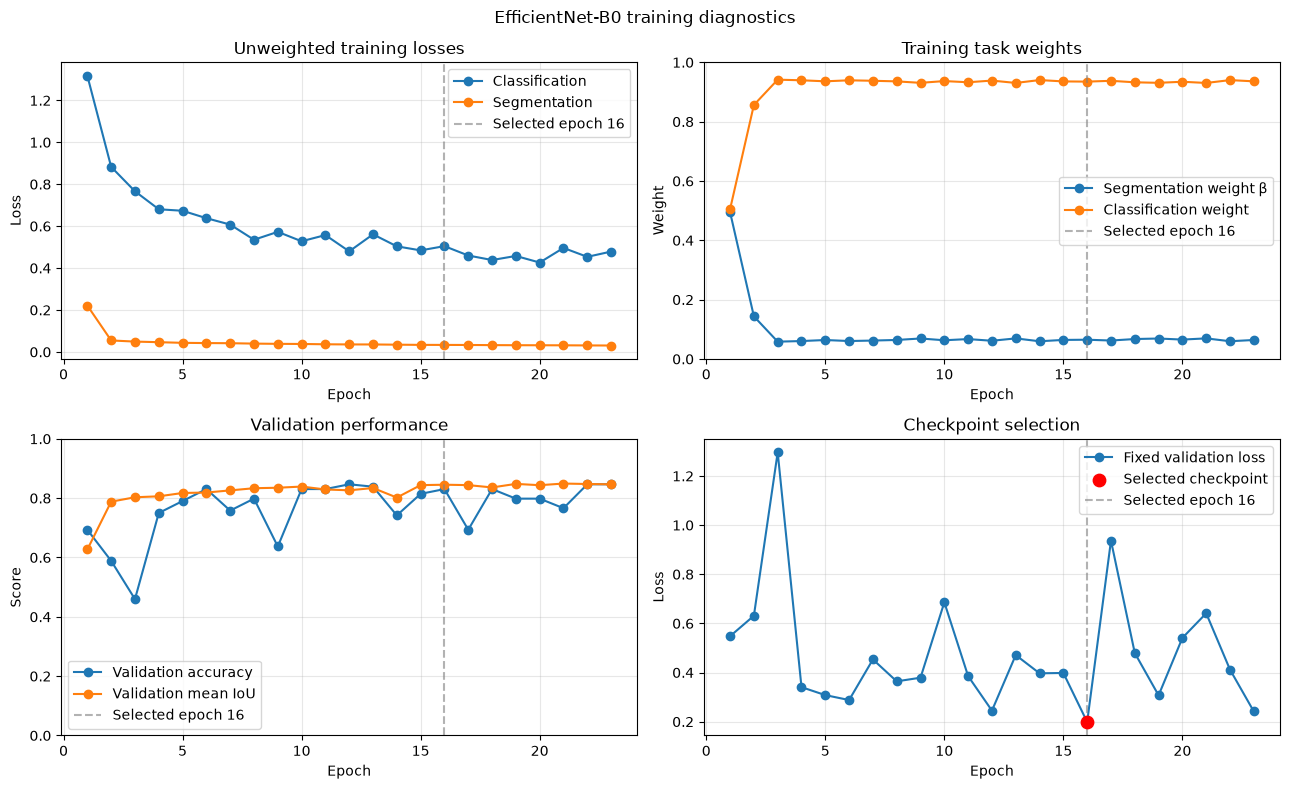


Saved figure: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_b0_dice_exclude0_20261115_194436_066635\adaptive_weight_diagnostics.png


In [24]:
import json
from pathlib import Path

import torch
import matplotlib.pyplot as plt

b0_run_folder = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    r"\camel_b0_dice_exclude0_20261115_194436_066635"
)

history_path = b0_run_folder / "history.json"
checkpoint_path = b0_run_folder / "best_model.pt"

with open(history_path, encoding="utf-8") as file:
    history = json.load(file)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert history, "The history file is empty."
assert checkpoint["encoder_name"] == "efficientnet-b0"

selected_epoch = int(checkpoint["epoch"])

print("History:", history_path)
print("Completed epochs:", len(history))

print("\nSelected EfficientNet-B0 checkpoint:")
print("Epoch:", selected_epoch)
print(f"Validation loss: {checkpoint['validation_loss']:.4f}")
print(f"Validation accuracy: {checkpoint['validation_accuracy']:.2f}%")
print(f"Validation Dice: {checkpoint['validation_dice']:.4f}")
print(f"Validation IoU: {checkpoint['validation_iou']:.4f}")

epoch_numbers = [row["epoch"] for row in history]

classification_losses = [
    row["train_classification_loss"] for row in history
]

segmentation_losses = [
    row["train_segmentation_loss"] for row in history
]

segmentation_weights = [
    row["segmentation_weight"] for row in history
]

validation_losses = [
    row["validation_loss"] for row in history
]

validation_accuracies = [
    row["validation_accuracy"] / 100 for row in history
]

validation_ious = [
    row["validation_iou"] for row in history
]

print(
    "\nEpoch | Classification loss | Segmentation loss | "
    "Actual β | Expected β"
)

for index, row in enumerate(history):
    if index == 0:
        expected_beta = 0.495
    else:
        previous = history[index - 1]

        expected_beta = (
            previous["train_segmentation_loss"]
            / max(
                previous["train_classification_loss"]
                + previous["train_segmentation_loss"],
                1e-7
            )
        )

    actual_beta = row["segmentation_weight"]

    print(
        f"{row['epoch']:5d} | "
        f"{row['train_classification_loss']:19.4f} | "
        f"{row['train_segmentation_loss']:17.4f} | "
        f"{actual_beta:8.4f} | "
        f"{expected_beta:10.4f}"
    )

    assert abs(actual_beta - expected_beta) < 1e-6, (
        f"Weight update mismatch at epoch {row['epoch']}"
    )

print("\nCheck passed: recorded β follows the previous epoch's loss ratio.")

best_loss_row = min(history, key=lambda row: row["validation_loss"])

assert selected_epoch == best_loss_row["epoch"], (
    "Checkpoint epoch does not match the lowest validation loss."
)

print("Check passed: checkpoint matches the lowest fixed validation loss.")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(
    epoch_numbers,
    classification_losses,
    marker="o",
    label="Classification"
)

axes[0, 0].plot(
    epoch_numbers,
    segmentation_losses,
    marker="o",
    label="Segmentation"
)

axes[0, 0].set_title("Unweighted training losses")
axes[0, 0].set_ylabel("Loss")

axes[0, 1].plot(
    epoch_numbers,
    segmentation_weights,
    marker="o",
    label="Segmentation weight β"
)

axes[0, 1].plot(
    epoch_numbers,
    [1 - beta for beta in segmentation_weights],
    marker="o",
    label="Classification weight"
)

axes[0, 1].set_title("Training task weights")
axes[0, 1].set_ylabel("Weight")
axes[0, 1].set_ylim(0, 1)

axes[1, 0].plot(
    epoch_numbers,
    validation_accuracies,
    marker="o",
    label="Validation accuracy"
)

axes[1, 0].plot(
    epoch_numbers,
    validation_ious,
    marker="o",
    label="Validation mean IoU"
)

axes[1, 0].set_title("Validation performance")
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_ylim(0, 1)

axes[1, 1].plot(
    epoch_numbers,
    validation_losses,
    marker="o",
    label="Fixed validation loss"
)

axes[1, 1].scatter(
    selected_epoch,
    checkpoint["validation_loss"],
    color="red",
    s=80,
    zorder=5,
    label="Selected checkpoint"
)

axes[1, 1].set_title("Checkpoint selection")
axes[1, 1].set_ylabel("Loss")

for axis in axes.flat:
    axis.axvline(
        selected_epoch,
        color="gray",
        linestyle="--",
        alpha=0.6,
        label=f"Selected epoch {selected_epoch}"
    )
    axis.set_xlabel("Epoch")
    axis.legend()
    axis.grid(alpha=0.3)

fig.suptitle("EfficientNet-B0 training diagnostics")
plt.tight_layout()

figure_path = b0_run_folder / "adaptive_weight_diagnostics.png"

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nSaved figure:", figure_path)

del checkpoint

### Model 3 — EfficientNet-B7: GPU Memory Check

SGD LR 0.1 - adaptive training - fixed validation weights
Maximum 200 epochs, patience 7 - select the lowest validation loss.
Saved checkpoint: epoch 6.

In [20]:
#CHECK THE VALIDATION LOSS BREAKDOWN FOR THE SELECTED B7 CHECKPOINT
from pathlib import Path
import torch
import torch.nn.functional as F

path = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    r"\camel_b7_dice_exclude0_20261115_222341_795805"
    r"\best_model.pt"
)

checkpoint = torch.load(
    path, map_location="cpu", weights_only=True
)

if "model" in globals():
    model.cpu()

check_model = CAMELModel(encoder_name="efficientnet-b7")
check_model.load_state_dict(checkpoint["model_state_dict"])
check_model = check_model.to(device)
check_model.eval()

loss_sums = {"include0": 0.0, "exclude0": 0.0}
total_images = 0

with torch.no_grad():
    for images, labels, masks in validationloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        cls_output, seg_output = check_model(images)

        cls_ce = F.cross_entropy(cls_output, labels)
        seg_ce = F.cross_entropy(seg_output, masks)

        probabilities = torch.softmax(seg_output, dim=1)
        targets = F.one_hot(
            masks, num_classes=6
        ).permute(0, 3, 1, 2).float()

        # Evaluate both Dice definitions on identical predictions.
        for variant, first_channel in [
            ("include0", 0),
            ("exclude0", 1),
        ]:
            p = probabilities[:, first_channel:]
            y = targets[:, first_channel:]

            dice_loss_value = 1 - (
                2 * (p * y).sum()
                / (p.sum() + y.sum() + 1e-7)
            )

            combined_loss = (
                0.5 * cls_ce
                + 0.25 * seg_ce
                + 0.25 * dice_loss_value
            )

            loss_sums[variant] += (
                combined_loss.item() * images.size(0)
            )

        total_images += images.size(0)

saved_loss = float(checkpoint["validation_loss"])

print("Checkpoint epoch:", checkpoint["epoch"])
print(
    "Recorded exclude-0 flag:",
    checkpoint.get("dice_excludes_class_zero", "Not recorded"),
)
print(f"\nSaved validation loss: {saved_loss:.8f}")

for variant, loss_sum in loss_sums.items():
    calculated = loss_sum / total_images
    difference = abs(calculated - saved_loss)

    print(
        f"{variant:8s} | Loss: {calculated:.8f} | "
        f"Difference: {difference:.8f} | "
        f"Matches: {difference < 1e-5}"
    )

check_model.cpu()
del check_model, checkpoint

if device.type == "cuda":
    torch.cuda.empty_cache()

Checkpoint epoch: 6
Recorded exclude-0 flag: Not recorded

Saved validation loss: 0.28681166
include0 | Loss: 0.28404005 | Difference: 0.00277161 | Matches: False
exclude0 | Loss: 0.28681166 | Difference: 0.00000000 | Matches: True


In [30]:
import gc
import json
import time
from pathlib import Path
from datetime import datetime

import torch

required = [
    "CAMELModel",
    "calculate_losses",
    "update_segmentation_weight",
    "trainloader",
    "validationloader",
    "dataset",
    "trainset",
    "validationset",
    "testset",
    "device"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Run the setup cells first. Missing: {missing}")

project_folder = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
)

resnet_checkpoint_path = project_folder / (
    "camel_adaptive_train_fixed_val_20261115_092825_748202"
) / "best_model.pt"

b0_checkpoint_path = project_folder / (
    "camel_b0_adaptive_train_fixed_val_20261115_095405_130988"
) / "best_model.pt"

b0_run_folder = b0_checkpoint_path.parent

for saved_path in [resnet_checkpoint_path, b0_checkpoint_path]:
    if not saved_path.is_file():
        raise FileNotFoundError(f"Checkpoint not found: {saved_path}")

encoder_name = "efficientnet-b7"

# run_name = datetime.now().strftime(
#     "camel_b7_adaptive_train_fixed_val_%Y%m%d_%H%M%S_%f"
# )

# Use the same Dice convention as the new ResNet and B0 runs.
exclude_zero_from_dice = True

trainloader.sampler.generator = torch.Generator().manual_seed(42)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

run_name = datetime.now().strftime(
    "camel_b7_dice_exclude0_%Y%m%d_%H%M%S_%f"
)

print("Encoder: efficientnet-b7 | Dice variant: exclude0")







run_folder = project_folder / run_name
run_folder.mkdir(parents=True, exist_ok=False)

checkpoint_path = run_folder / "best_model.pt"
history_path = run_folder / "history.json"

b7_run_folder = run_folder
b7_checkpoint_path = checkpoint_path

print("ResNet checkpoint preserved:", resnet_checkpoint_path)
print("B0 checkpoint preserved:", b0_checkpoint_path)
print("New B7 run:", run_folder)

if "model" in globals():
    model.cpu()

if "optimizer2" in globals():
    del optimizer2

gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

model = CAMELModel(
    encoder_name=encoder_name
).to(device)

optimizer2 = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.0
)

epochs = 200
patience = 7

segmentation_weight = 0.495
best_validation_loss = float("inf")
epochs_without_improvement = 0
history = []

config = {
    "encoder": encoder_name,
    "seed": 42,
    "learning_rate": 0.1,
    "momentum": 0.0,
    "maximum_epochs": epochs,
    "patience": patience,
    "batch_size": trainloader.batch_size,
    "initial_segmentation_weight": segmentation_weight,
    "dice_excludes_class_zero": exclude_zero_from_dice,
    "dice_variant": "exclude0",
    "training_shuffle_seed": 42,
    "validation_weights": [0.5, 0.5],
    "class_names": list(dataset.class_names),
    "segmentation_classes": 6,
    "input_size": [320, 320],
    "train_indices": [int(i) for i in trainset.indices],
    "validation_indices": [int(i) for i in validationset.indices],
    "test_indices": [int(i) for i in testset.indices]
}

(run_folder / "config.json").write_text(
    json.dumps(config, indent=2),
    encoding="utf-8"
)

if device.type == "cuda":
    torch.cuda.synchronize()

training_start = time.perf_counter()

for epoch in range(epochs):
    epoch_start = time.perf_counter()

    model.train()

    train_classification_loss_sum = 0.0
    train_segmentation_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels, masks in trainloader:
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        optimizer2.zero_grad(set_to_none=True)

        classification_output, segmentation_output = model(images)

        loss, classification_loss, segmentation_loss = calculate_losses(
            classification_output,
            segmentation_output,
            labels,
            masks,
            segmentation_weight
        )

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite training loss.")

        loss.backward()
        optimizer2.step()

        batch_count = images.size(0)

        train_classification_loss_sum += (
            classification_loss.item() * batch_count
        )
        train_segmentation_loss_sum += (
            segmentation_loss.item() * batch_count
        )

        train_correct += (
            classification_output.argmax(dim=1) == labels
        ).sum().item()

        train_total += batch_count

    average_classification_loss = (
        train_classification_loss_sum / train_total
    )
    average_segmentation_loss = (
        train_segmentation_loss_sum / train_total
    )

    train_loss = (
        (1 - segmentation_weight) * average_classification_loss
        + segmentation_weight * average_segmentation_loss
    )

    train_accuracy = 100 * train_correct / train_total

    model.eval()

    validation_loss_sum = 0.0
    validation_correct = 0
    validation_total = 0

    intersection = torch.zeros(
        6, device=device, dtype=torch.float64
    )
    predicted_pixels = torch.zeros_like(intersection)
    target_pixels = torch.zeros_like(intersection)

    with torch.no_grad():
        for images, labels, masks in validationloader:
            images = images.to(device)
            labels = labels.to(device)
            masks = masks.to(device)

            classification_output, segmentation_output = model(images)

            _, classification_loss, segmentation_loss = calculate_losses(
                classification_output,
                segmentation_output,
                labels,
                masks,
                segmentation_weight
            )

            # Fixed validation weights for checkpoint selection.
            loss = (
                0.5 * classification_loss
                + 0.5 * segmentation_loss
            )

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite validation loss.")

            batch_count = images.size(0)
            validation_loss_sum += loss.item() * batch_count
            validation_total += batch_count

            validation_correct += (
                classification_output.argmax(dim=1) == labels
            ).sum().item()

            predictions = segmentation_output.argmax(dim=1)

            for class_number in range(6):
                predicted_class = predictions == class_number
                target_class = masks == class_number

                intersection[class_number] += (
                    predicted_class & target_class
                ).sum()

                predicted_pixels[class_number] += predicted_class.sum()
                target_pixels[class_number] += target_class.sum()

    validation_loss = validation_loss_sum / validation_total
    validation_accuracy = 100 * validation_correct / validation_total

    denominator = predicted_pixels + target_pixels
    union = denominator - intersection
    valid_classes = union > 0

    validation_dice = (
        2 * intersection[valid_classes]
        / denominator[valid_classes]
    ).mean().item()

    validation_iou = (
        intersection[valid_classes]
        / union[valid_classes]
    ).mean().item()

    epoch_seconds = time.perf_counter() - epoch_start

    history.append({
        "epoch": epoch + 1,
        "segmentation_weight": segmentation_weight,
        "train_loss": train_loss,
        "train_classification_loss": average_classification_loss,
        "train_segmentation_loss": average_segmentation_loss,
        "train_accuracy": train_accuracy,
        "validation_loss": validation_loss,
        "validation_accuracy": validation_accuracy,
        "validation_dice": validation_dice,
        "validation_iou": validation_iou,
        "seconds": epoch_seconds
    })

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "encoder_name": encoder_name,
            "epoch": epoch + 1,
            "segmentation_weight": segmentation_weight,
            "validation_loss": validation_loss,
            "validation_accuracy": validation_accuracy,
            "validation_dice": validation_dice,
            "validation_iou": validation_iou,
            "config": config
        }, checkpoint_path)

    else:
        epochs_without_improvement += 1

    history_path.write_text(
        json.dumps(history, indent=2),
        encoding="utf-8"
    )

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"β: {segmentation_weight:.3f} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Acc: {validation_accuracy:.2f}% | "
        f"Val Dice: {validation_dice:.4f} | "
        f"Val IoU: {validation_iou:.4f} | "
        f"Time: {epoch_seconds:.0f}s"
    )

    segmentation_weight = update_segmentation_weight(
        average_classification_loss,
        average_segmentation_loss
    )

    if epochs_without_improvement >= patience:
        print("\nEarly stopping.")
        break

if device.type == "cuda":
    torch.cuda.synchronize()

training_seconds = time.perf_counter() - training_start

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(f"\nTraining time: {training_seconds / 60:.2f} minutes")
print("Selected encoder:", checkpoint["encoder_name"])
print("Selected epoch:", checkpoint["epoch"])
print(f"Selected validation loss: {checkpoint['validation_loss']:.4f}")
print(
    f"Selected validation accuracy: "
    f"{checkpoint['validation_accuracy']:.2f}%"
)
print(f"Selected validation Dice: {checkpoint['validation_dice']:.4f}")
print(f"Selected validation IoU: {checkpoint['validation_iou']:.4f}")
print("Checkpoint:", checkpoint_path.resolve())

del checkpoint

Encoder: efficientnet-b7 | Dice variant: exclude0
ResNet checkpoint preserved: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_adaptive_train_fixed_val_20261115_092825_748202\best_model.pt
B0 checkpoint preserved: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_b0_adaptive_train_fixed_val_20261115_095405_130988\best_model.pt
New B7 run: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_b7_dice_exclude0_20261115_222341_795805
Epoch 1/200 | β: 0.495 | Train Loss: 2.8469 | Val Loss: 1.4707 | Train Acc: 38.18% | Val Acc: 38.71% | Val Dice: 0.7306 | Val IoU: 0.5869 | Time: 76s
Epoch 2/200 | β: 0.042 | Train Loss: 2.6412 | Val Loss: 0.7147 | Train Acc: 38.78% | Val Acc: 45.16% | Val Dice: 0.8223 | Val IoU: 0.7076 | Time: 75s
Epoch 3/200 | β: 0.036 | Train Loss: 1.3398 | Val Loss: 0.5879 | Train Acc: 40.94% | Val Acc: 51.61% | Val Dice: 0.8652 | Val IoU: 0.7718 | Time: 75s
Epoch 4/200 | β: 0.051 | Train Loss: 1.1608 | Val Loss: 0

History: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_b7_dice_exclude0_20261115_222341_795805\history.json
Completed epochs: 13

Selected EfficientNet-B7 checkpoint:
Epoch: 6
Validation loss: 0.2868
Validation accuracy: 73.39%
Validation Dice: 0.8954
Validation IoU: 0.8187

Epoch | Classification loss | Segmentation loss | Actual β | Expected β
    1 |              5.4033 |            0.2389 |   0.4950 |     0.4950
    2 |              2.7534 |            0.1028 |   0.0423 |     0.0423
    3 |              1.3871 |            0.0741 |   0.0360 |     0.0360
    4 |              1.2194 |            0.0627 |   0.0507 |     0.0507
    5 |              1.1322 |            0.0579 |   0.0489 |     0.0489
    6 |              1.0607 |            0.0531 |   0.0487 |     0.0487
    7 |              1.0025 |            0.0528 |   0.0476 |     0.0476
    8 |              0.9070 |            0.0491 |   0.0500 |     0.0500
    9 |              0.9716 |            0.0459 |   

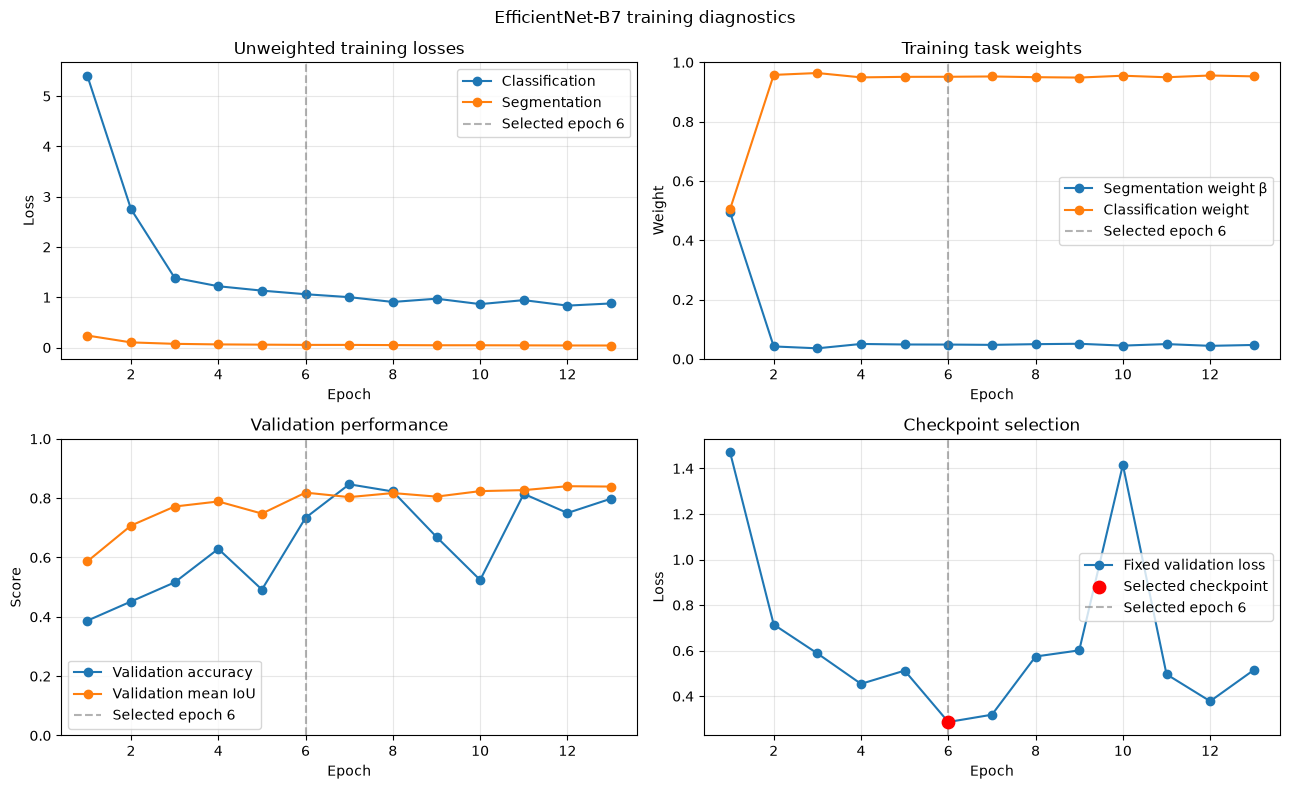


Saved figure: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_b7_dice_exclude0_20261115_222341_795805\adaptive_weight_diagnostics.png


In [23]:
import json
from pathlib import Path

import torch
import matplotlib.pyplot as plt

b7_run_folder = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    r"\camel_b7_dice_exclude0_20261115_222341_795805"
)

history_path = b7_run_folder / "history.json"
checkpoint_path = b7_run_folder / "best_model.pt"

with open(history_path, encoding="utf-8") as file:
    history = json.load(file)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

assert history, "The history file is empty."
assert checkpoint["encoder_name"] == "efficientnet-b7"

selected_epoch = int(checkpoint["epoch"])

print("History:", history_path)
print("Completed epochs:", len(history))

print("\nSelected EfficientNet-B7 checkpoint:")
print("Epoch:", selected_epoch)
print(f"Validation loss: {checkpoint['validation_loss']:.4f}")
print(f"Validation accuracy: {checkpoint['validation_accuracy']:.2f}%")
print(f"Validation Dice: {checkpoint['validation_dice']:.4f}")
print(f"Validation IoU: {checkpoint['validation_iou']:.4f}")

epoch_numbers = [row["epoch"] for row in history]

classification_losses = [
    row["train_classification_loss"] for row in history
]

segmentation_losses = [
    row["train_segmentation_loss"] for row in history
]

segmentation_weights = [
    row["segmentation_weight"] for row in history
]

validation_losses = [
    row["validation_loss"] for row in history
]

validation_accuracies = [
    row["validation_accuracy"] / 100 for row in history
]

validation_ious = [
    row["validation_iou"] for row in history
]

print(
    "\nEpoch | Classification loss | Segmentation loss | "
    "Actual β | Expected β"
)

for index, row in enumerate(history):
    if index == 0:
        expected_beta = 0.495
    else:
        previous = history[index - 1]

        expected_beta = (
            previous["train_segmentation_loss"]
            / max(
                previous["train_classification_loss"]
                + previous["train_segmentation_loss"],
                1e-7
            )
        )

    actual_beta = row["segmentation_weight"]

    print(
        f"{row['epoch']:5d} | "
        f"{row['train_classification_loss']:19.4f} | "
        f"{row['train_segmentation_loss']:17.4f} | "
        f"{actual_beta:8.4f} | "
        f"{expected_beta:10.4f}"
    )

    assert abs(actual_beta - expected_beta) < 1e-6, (
        f"Weight update mismatch at epoch {row['epoch']}"
    )

print("\nCheck passed: recorded β follows the previous epoch's loss ratio.")

best_loss_row = min(history, key=lambda row: row["validation_loss"])

assert selected_epoch == best_loss_row["epoch"], (
    "Checkpoint epoch does not match the lowest validation loss."
)

print("Check passed: checkpoint matches the lowest fixed validation loss.")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].plot(
    epoch_numbers,
    classification_losses,
    marker="o",
    label="Classification"
)

axes[0, 0].plot(
    epoch_numbers,
    segmentation_losses,
    marker="o",
    label="Segmentation"
)

axes[0, 0].set_title("Unweighted training losses")
axes[0, 0].set_ylabel("Loss")

axes[0, 1].plot(
    epoch_numbers,
    segmentation_weights,
    marker="o",
    label="Segmentation weight β"
)

axes[0, 1].plot(
    epoch_numbers,
    [1 - beta for beta in segmentation_weights],
    marker="o",
    label="Classification weight"
)

axes[0, 1].set_title("Training task weights")
axes[0, 1].set_ylabel("Weight")
axes[0, 1].set_ylim(0, 1)

axes[1, 0].plot(
    epoch_numbers,
    validation_accuracies,
    marker="o",
    label="Validation accuracy"
)

axes[1, 0].plot(
    epoch_numbers,
    validation_ious,
    marker="o",
    label="Validation mean IoU"
)

axes[1, 0].set_title("Validation performance")
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_ylim(0, 1)

axes[1, 1].plot(
    epoch_numbers,
    validation_losses,
    marker="o",
    label="Fixed validation loss"
)

axes[1, 1].scatter(
    selected_epoch,
    checkpoint["validation_loss"],
    color="red",
    s=80,
    zorder=5,
    label="Selected checkpoint"
)

axes[1, 1].set_title("Checkpoint selection")
axes[1, 1].set_ylabel("Loss")

for axis in axes.flat:
    axis.axvline(
        selected_epoch,
        color="gray",
        linestyle="--",
        alpha=0.6,
        label=f"Selected epoch {selected_epoch}"
    )
    axis.set_xlabel("Epoch")
    axis.legend()
    axis.grid(alpha=0.3)

fig.suptitle("EfficientNet-B7 training diagnostics")
plt.tight_layout()

figure_path = b7_run_folder / "adaptive_weight_diagnostics.png"

plt.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nSaved figure:", figure_path)

del checkpoint

| Selected model | Epoch | Validation accuracy | Dice | IoU |
|---|---:|---:|---:|---:|
| ResNet101 | 13 | 70.97% | 0.9028 | 0.8308 |
| **EfficientNet-B0** | **20** | **91.94%** | **0.9112** | **0.8441** |
| EfficientNet-B7 | 3 | 75.00% | 0.8667 | 0.7761 |

### Three-model confidence-aware ensemble — validation

- Load the saved ResNet101, EfficientNet-B0 and EfficientNet-B7 checkpoints.
- Measure classification ECE per image and segmentation ECE per pixel.
- Follow CAMEL Equations 5–6 to calculate separate weights for each task.
- Average probabilities, then select the class with the highest probability.
- Compare each model, equal averaging and confidence-aware averaging.
- Save the validation-derived weights for later test evaluation.

This is our three-model, two-task adaptation. No training or test evaluation occurs here.
Pixel ECE pools all six mask classes, so large regions can dominate it.

In [ ]:
import gc
import json
from pathlib import Path
from datetime import datetime

import torch
from torch.utils.data import SequentialSampler

required = [
    "CAMELModel",
    "validationloader",
    "validationset",
    "dataset",
    "device"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Run the setup cells first. Missing: {missing}")

# All models must see the same images in the same order.
assert isinstance(validationloader.sampler, SequentialSampler)
assert not validationloader.drop_last
assert len(validationset) == 124
assert list(dataset.class_names) == ["AMD", "DME", "Normal"]

project_folder = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
)

# model_settings = [
#     (
#         "Adaptive ResNet101",
#         "resnet101",
#         project_folder
#         / "camel_adaptive_train_fixed_val_20261115_092825_748202"
#         / "best_model.pt"
#     ),
#     (
#         "Adaptive EfficientNet-B0",
#         "efficientnet-b0",
#         project_folder
#         / "camel_b0_adaptive_train_fixed_val_20261115_095405_130988"
#         / "best_model.pt"
#     ),
#     (
#         "Adaptive EfficientNet-B7",
#         "efficientnet-b7",
#         project_folder
#         / "camel_b7_adaptive_train_fixed_val_20261115_101554_470209"
#         / "best_model.pt"
#     )
# ]

model_settings = [
    (
        "ResNet101 LR0.01 joint",
        "resnet101",
        project_folder
        / "camel_resnet101_exclude0_lr001_20epochs_20261118_190547_808191"
        / "best_joint.pt"
    ),
    (
        "Exclude-0 EfficientNet-B0",
        "efficientnet-b0",
        project_folder
        / "camel_b0_dice_exclude0_20261115_194436_066635"
        / "best_model.pt"
    ),
    (
        "Exclude-0 EfficientNet-B7",
        "efficientnet-b7",
        project_folder
        / "camel_b7_dice_exclude0_20261115_222341_795805"
        / "best_model.pt"
    )
]



for name, encoder_name, path in model_settings:
    if not path.is_file():
        raise FileNotFoundError(f"Missing checkpoint: {path}")

if "model" in globals():
    model.cpu()

if "optimizer2" in globals():
    del optimizer2

gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()

number_of_bins = 10
number_of_mask_classes = 6

saved_predictions = []
reference_labels = []
reference_masks = []

classification_errors = []
segmentation_errors = []
checkpoint_details = []


def new_ece_counts():
    return torch.zeros(
        3, number_of_bins,
        device=device,
        dtype=torch.float64
    )


def update_ece_counts(counts, probabilities, targets):
    confidences, predictions = probabilities.max(dim=1)
    correct = predictions == targets

    # Same bin intervals as the released ECE utility.
    for bin_number in range(number_of_bins):
        lower = bin_number / number_of_bins
        upper = (bin_number + 1) / number_of_bins

        in_bin = (
            (confidences > lower)
            & (confidences <= upper)
        )

        counts[0, bin_number] += in_bin.sum()
        counts[1, bin_number] += confidences[in_bin].sum(
            dtype=torch.float64
        )
        counts[2, bin_number] += correct[in_bin].sum()


def finish_ece(counts):
    nonempty = counts[0] > 0

    bin_counts = counts[0, nonempty]
    bin_confidences = counts[1, nonempty] / bin_counts
    bin_accuracies = counts[2, nonempty] / bin_counts

    # Larger bins contribute more, as in the released utility.
    bin_weights = bin_counts / bin_counts.sum()

    return (
        bin_weights * (bin_accuracies - bin_confidences).abs()
    ).sum().item()


for model_index, (name, encoder_name, path) in enumerate(model_settings):
    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["encoder_name"] == encoder_name

    # B0/B7 checkpoints include their validation split.
    config = checkpoint.get("config", {})

    if "validation_indices" in config:
        assert config["validation_indices"] == [
            int(i) for i in validationset.indices
        ], f"Validation split mismatch: {name}"

    member = CAMELModel(encoder_name=encoder_name)

    # Restore every saved parameter; do not use a fresh model's predictions.
    member.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )
    member = member.to(device)
    member.eval()

    checkpoint_details.append({
        "name": name,
        "encoder_name": encoder_name,
        "path": str(path),
        "selected_epoch": int(checkpoint["epoch"])
    })

    del checkpoint

    classification_batches = []
    segmentation_batches = []

    classification_counts = new_ece_counts()
    segmentation_counts = new_ece_counts()

    batches_seen = 0

    with torch.no_grad():
        for batch_index, (images, labels, masks) in enumerate(
            validationloader
        ):
            images = images.to(device)
            device_labels = labels.to(device)
            device_masks = masks.to(device)

            classification_output, segmentation_output = member(images)

            assert classification_output.shape == (images.size(0), 3)
            assert segmentation_output.shape == (
                images.size(0), 6, masks.size(1), masks.size(2)
            )

            # Our heads return logits, so apply softmax once.
            cls_probabilities = torch.softmax(
                classification_output, dim=1
            )
            seg_probabilities = torch.softmax(
                segmentation_output, dim=1
            )

            if not (
                torch.isfinite(cls_probabilities).all().item()
                and torch.isfinite(seg_probabilities).all().item()
            ):
                raise RuntimeError(f"Non-finite predictions: {name}")

            update_ece_counts(
                classification_counts,
                cls_probabilities,
                device_labels
            )

            # Each pixel is one observation for segmentation ECE.
            update_ece_counts(
                segmentation_counts,
                seg_probabilities,
                device_masks
            )

            # Cache on CPU so only one model needs GPU memory.
            classification_batches.append(cls_probabilities.cpu())
            segmentation_batches.append(seg_probabilities.cpu())

            if model_index == 0:
                reference_labels.append(labels.cpu().clone())
                reference_masks.append(masks.cpu().clone())
            else:
                assert torch.equal(
                    labels.cpu(), reference_labels[batch_index]
                )
                assert torch.equal(
                    masks.cpu(), reference_masks[batch_index]
                )

            batches_seen += 1

    assert batches_seen == len(reference_labels)

    classification_ece = finish_ece(classification_counts)
    segmentation_ece = finish_ece(segmentation_counts)

    classification_errors.append(classification_ece)
    segmentation_errors.append(segmentation_ece)

    saved_predictions.append((
        classification_batches,
        segmentation_batches
    ))

    print(
        f"{name} | "
        f"Classification ECE: {classification_ece:.4f} | "
        f"Segmentation ECE: {segmentation_ece:.4f}"
    )

    del member
    del classification_output, segmentation_output
    del cls_probabilities, seg_probabilities
    del images, device_labels, device_masks
    del classification_counts, segmentation_counts

    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()


def reliability_weights(ece_values):
    errors = torch.tensor(ece_values, dtype=torch.float64)

    assert torch.isfinite(errors).all()
    assert (errors >= 0).all()

    # Our fallback: use equal weights if every ECE is zero.
    if errors.sum().item() == 0:
        return torch.ones_like(errors) / len(errors)

    # CAMEL Equation 5.
    reliability = 1 - errors / errors.sum()

    # CAMEL Equation 6 normalizes the reliability scores.
    return reliability / reliability.sum()


classification_weights = reliability_weights(classification_errors)
segmentation_weights = reliability_weights(segmentation_errors)

equal_weights = torch.full(
    (len(model_settings),),
    1 / len(model_settings),
    dtype=torch.float64
)

print("\nWeights calculated from validation only:")

for index, (name, _, _) in enumerate(model_settings):
    print(
        f"{name} | "
        f"Classification: {classification_weights[index]:.6f} | "
        f"Segmentation: {segmentation_weights[index]:.6f}"
    )

assert abs(classification_weights.sum().item() - 1) < 1e-10
assert abs(segmentation_weights.sum().item() - 1) < 1e-10


def evaluate_cached_predictions(cls_weights, seg_weights):
    correct = 0
    total = 0

    intersection = torch.zeros(6, dtype=torch.float64)
    predicted_pixels = torch.zeros_like(intersection)
    target_pixels = torch.zeros_like(intersection)

    for batch_index in range(len(reference_labels)):
        cls_probabilities = torch.zeros_like(
            saved_predictions[0][0][batch_index]
        )
        seg_probabilities = torch.zeros_like(
            saved_predictions[0][1][batch_index]
        )

        # Combine probabilities, not network parameters or class IDs.
        for model_index in range(len(saved_predictions)):
            cls_probabilities += (
                float(cls_weights[model_index])
                * saved_predictions[model_index][0][batch_index]
            )

            seg_probabilities += (
                float(seg_weights[model_index])
                * saved_predictions[model_index][1][batch_index]
            )

        labels = reference_labels[batch_index]
        masks = reference_masks[batch_index]

        predicted_labels = cls_probabilities.argmax(dim=1)
        predicted_masks = seg_probabilities.argmax(dim=1)

        correct += (predicted_labels == labels).sum().item()
        total += labels.size(0)

        for class_number in range(number_of_mask_classes):
            predicted_class = predicted_masks == class_number
            target_class = masks == class_number

            intersection[class_number] += (
                predicted_class & target_class
            ).sum()

            predicted_pixels[class_number] += predicted_class.sum()
            target_pixels[class_number] += target_class.sum()

    denominator = predicted_pixels + target_pixels
    union = denominator - intersection
    valid_classes = union > 0

    # Keep the same all-six-class metrics as our earlier evaluations.
    mean_dice = (
        2 * intersection[valid_classes]
        / denominator[valid_classes]
    ).mean().item()

    mean_iou = (
        intersection[valid_classes]
        / union[valid_classes]
    ).mean().item()

    return {
        "accuracy_percent": 100 * correct / total,
        "mean_dice": mean_dice,
        "mean_iou": mean_iou,
        "image_count": total
    }


validation_results = {}

# A weight of 1 for one member gives its individual result.
for model_index, (name, _, _) in enumerate(model_settings):
    single_weights = torch.zeros(len(model_settings))
    single_weights[model_index] = 1

    validation_results[name] = evaluate_cached_predictions(
        single_weights,
        single_weights
    )

validation_results["Equal averaging"] = evaluate_cached_predictions(
    equal_weights,
    equal_weights
)

validation_results["Confidence-aware weighting"] = (
    evaluate_cached_predictions(
        classification_weights,
        segmentation_weights
    )
)

print("\nValidation comparison:")

for name, result in validation_results.items():
    print(
        f"{name} | "
        f"Accuracy: {result['accuracy_percent']:.2f}% | "
        f"Dice: {result['mean_dice']:.4f} | "
        f"IoU: {result['mean_iou']:.4f}"
    )

ensemble_folder = project_folder / datetime.now().strftime(
    "camel_newresnet_lr0p01_b0_b7_validation_%Y%m%d_%H%M%S_%f"
)
ensemble_folder.mkdir(parents=True, exist_ok=False)

ensemble_settings = {
    "models": checkpoint_details,
    "class_names": list(dataset.class_names),
    "number_of_mask_classes": number_of_mask_classes,
    "number_of_ece_bins": number_of_bins,
    "classification_ece": classification_errors,
    "segmentation_ece": segmentation_errors,
    "classification_weights": classification_weights.tolist(),
    "segmentation_weights": segmentation_weights.tolist(),
    "weight_source": "validation",
    "validation_indices": [int(i) for i in validationset.indices],
    "validation_batch_size": validationloader.batch_size,
    "validation_results": validation_results,
    "notes": [
        "Three-model, two-task PyTorch adaptation.",
        "Reliability weighting follows CAMEL Equations 5 and 6.",
        "ECE uses the released utility's bin-frequency weighting.",
        "Segmentation ECE pools all six classes and all pixels.",
        "No training or test evaluation performed in this cell."
    ]
}

ensemble_settings_path = ensemble_folder / "ensemble_settings.json"

ensemble_settings_path.write_text(
    json.dumps(ensemble_settings, indent=2),
    encoding="utf-8"
)

print("\nSaved settings and results:", ensemble_settings_path)

# Predictions can be regenerated from the saved checkpoints.
del saved_predictions, reference_labels, reference_masks
gc.collect()

# Pass this exact validation settings file to the test cell
new_resnet_ensemble_settings_path = ensemble_settings_path.resolve()

print("\nReady for test evaluation:")
print(new_resnet_ensemble_settings_path)

for setting in ensemble_settings["models"]:
    print(
        f"{setting['name']} | "
        f"Selected epoch: {setting['selected_epoch']}"
    )

ResNet checkpoint: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_resnet101_exclude0_lr001_20epochs_20261118_190547_808191\best_joint.pt
ResNet101 LR0.01 joint | Classification ECE: 0.1436 | Segmentation ECE: 0.0048
Exclude-0 EfficientNet-B0 | Classification ECE: 0.0580 | Segmentation ECE: 0.0066
Exclude-0 EfficientNet-B7 | Classification ECE: 0.0495 | Segmentation ECE: 0.0102

Weights calculated from validation only:
ResNet101 LR0.01 joint | Classification: 0.214036 | Segmentation: 0.389096
Exclude-0 EfficientNet-B0 | Classification: 0.384603 | Segmentation: 0.347551
Exclude-0 EfficientNet-B7 | Classification: 0.401361 | Segmentation: 0.263352

Validation comparison:
ResNet101 LR0.01 joint | Accuracy: 84.68% | Dice: 0.9232 | IoU: 0.8643
Exclude-0 EfficientNet-B0 | Accuracy: 83.06% | Dice: 0.9121 | IoU: 0.8454
Exclude-0 EfficientNet-B7 | Accuracy: 73.39% | Dice: 0.8954 | IoU: 0.8187
Equal averaging | Accuracy: 84.68% | Dice: 0.9243 | IoU: 0.8653
Confidence-aware 

### Validation results

| Method | Accuracy ↑ | Dice ↑ | IoU ↑ |
|---|---:|---:|---:|
| ResNet101 | 84.68% | 0.9232 | 0.8643 |
| B0 | 83.06% | 0.9121 | 0.8454 |
| B7 | 73.39% | 0.8954 | 0.8187 |
| Equal ensemble | 84.68% | 0.9243 | 0.8653 |
| ECE-weighted ensemble | 84.68% | **0.9260** | **0.8682** |

Weights were calculated from validation only.

### Now ensemble model is tested on test data

Using validation settings: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_newresnet_lr0p01_b0_b7_validation_20261119_155126_920786\ensemble_settings.json
Test images: 715
Classification weights: [0.21403612196445465, 0.38460323214530945, 0.4013606309890747]
Segmentation weights: [0.38909611105918884, 0.34755146503448486, 0.2633524239063263]
Loaded: ResNet101 LR0.01 joint | Selected epoch: 17
Loaded: Exclude-0 EfficientNet-B0 | Selected epoch: 16
Loaded: Exclude-0 EfficientNet-B7 | Selected epoch: 6
Test batches completed: 50/358
Test batches completed: 100/358
Test batches completed: 150/358
Test batches completed: 200/358
Test batches completed: 250/358
Test batches completed: 300/358
Test batches completed: 350/358
Test batches completed: 358/358

Final test comparison:
ResNet101 LR0.01 joint | Accuracy: 65.31% | Dice: 0.9274 | IoU: 0.8709
Exclude-0 EfficientNet-B0 | Accuracy: 76.36% | Dice: 0.9264 | IoU: 0.8684
Exclude-0 EfficientNet-B7 | Accuracy: 50.63% | Di

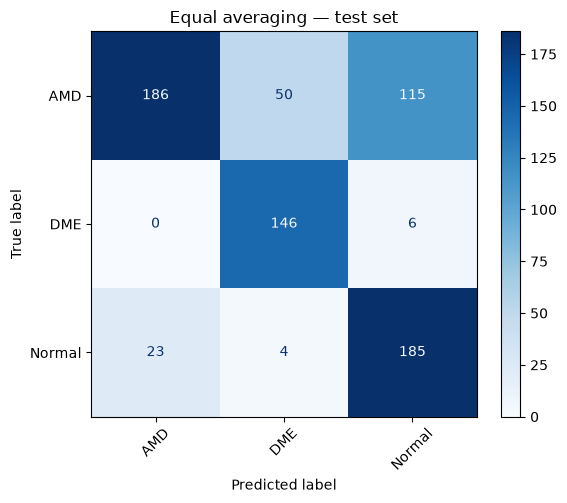


Confidence-aware weighting — classification report
              precision    recall  f1-score   support

         AMD     0.9058    0.4929    0.6384       351
         DME     0.7010    0.9408    0.8034       152
      Normal     0.6094    0.9198    0.7331       212

    accuracy                         0.7147       715
   macro avg     0.7387    0.7845    0.7249       715
weighted avg     0.7743    0.7147    0.7015       715

Segmentation scores:
Class 0 | Dice: 0.9937 | IoU: 0.9875
Class 1 | Dice: 0.9498 | IoU: 0.9045
Class 2 | Dice: 0.9340 | IoU: 0.8762
Class 3 | Dice: 0.8729 | IoU: 0.7745
Class 4 | Dice: 0.8532 | IoU: 0.7439
Class 5 | Dice: 0.9966 | IoU: 0.9932


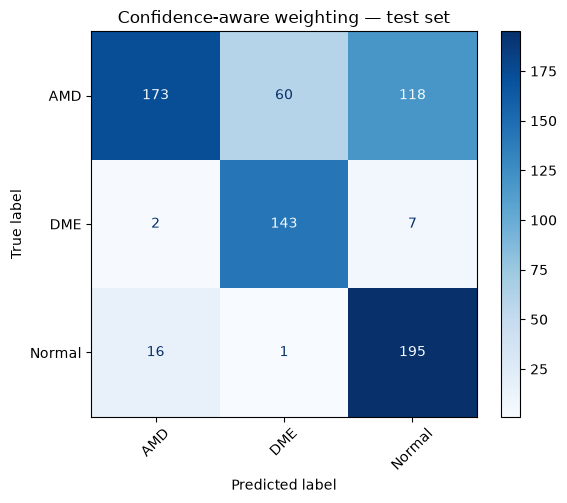


Saved test results: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_newresnet_lr0p01_b0_b7_validation_20261119_155126_920786\test_evaluation_20261119_155816_650255\test_results.json
Saved figures: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_newresnet_lr0p01_b0_b7_validation_20261119_155126_920786\test_evaluation_20261119_155816_650255


In [24]:
import gc
import json
from pathlib import Path
from datetime import datetime

import torch
import matplotlib.pyplot as plt

from torch.utils.data import SequentialSampler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

required = [
    "CAMELModel",
    "testloader",
    "testset",
    "dataset",
    "device"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(f"Run the setup cells first. Missing: {missing}")

# settings_path = Path(
#     r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
#     r"\FrameX-EN3160-CAMEL"
#     r"\camel_adaptive_ensemble_validation_20261115_104337_180245"
#     r"\ensemble_settings.json"
# )

if "new_resnet_ensemble_settings_path" not in globals():
    raise RuntimeError(
        "Run the updated validation cell first."
    )

settings_path = Path(new_resnet_ensemble_settings_path)

assert settings_path.is_file()
assert settings_path.parent.name.startswith(
    "camel_newresnet_lr0p01_b0_b7_validation_"
)

print("Using validation settings:", settings_path)






with open(settings_path, encoding="utf-8") as file:
    ensemble_settings = json.load(file)

model_settings = ensemble_settings["models"]
class_names = ensemble_settings["class_names"]
number_of_mask_classes = ensemble_settings["number_of_mask_classes"]

assert ensemble_settings["weight_source"] == "validation"
assert list(dataset.class_names) == class_names
assert len(model_settings) == 3
assert number_of_mask_classes == 6
assert len(testset) == 715
assert isinstance(testloader.sampler, SequentialSampler)
assert not testloader.drop_last
assert testloader.dataset is testset

test_indices = [int(i) for i in testset.indices]
validation_indices = ensemble_settings["validation_indices"]

assert set(test_indices).isdisjoint(validation_indices)

# Use the saved validation weights without changing them.
classification_weights = torch.tensor(
    ensemble_settings["classification_weights"],
    device=device,
    dtype=torch.float32
)

segmentation_weights = torch.tensor(
    ensemble_settings["segmentation_weights"],
    device=device,
    dtype=torch.float32
)

for weights in [classification_weights, segmentation_weights]:
    assert weights.numel() == len(model_settings)
    assert torch.isfinite(weights).all().item()
    assert (weights >= 0).all().item()
    assert abs(weights.sum().item() - 1) < 1e-6

print("Test images:", len(testset))
print("Classification weights:", classification_weights.cpu().tolist())
print("Segmentation weights:", segmentation_weights.cpu().tolist())

if "model" in globals():
    model.cpu()

if "optimizer2" in globals():
    del optimizer2

# Release models from a previous execution of this cell.
if "test_models" in globals():
    for previous_model in test_models:
        previous_model.cpu()
    del test_models

gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()

test_models = []

for setting in model_settings:
    checkpoint_path = Path(setting["path"])

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    assert checkpoint["encoder_name"] == setting["encoder_name"]
    assert int(checkpoint["epoch"]) == setting["selected_epoch"]

    # Check split metadata where it was saved during training.
    config = checkpoint.get("config", {})

    if "test_indices" in config:
        assert config["test_indices"] == test_indices, (
            f"Test split mismatch: {setting['name']}"
        )

    if "validation_indices" in config:
        assert config["validation_indices"] == validation_indices, (
            f"Validation split mismatch: {setting['name']}"
        )

    member = CAMELModel(
        encoder_name=setting["encoder_name"]
    )

    member.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    member = member.to(device)
    member.eval()

    test_models.append(member)

    print(
        f"Loaded: {setting['name']} | "
        f"Selected epoch: {setting['selected_epoch']}"
    )

    del checkpoint

method_names = [
    setting["name"] for setting in model_settings
] + [
    "Equal averaging",
    "Confidence-aware weighting"
]


def new_statistics():
    return {
        "correct": 0,
        "total": 0,
        "intersection": torch.zeros(
            number_of_mask_classes,
            device=device,
            dtype=torch.float64
        ),
        "predicted_pixels": torch.zeros(
            number_of_mask_classes,
            device=device,
            dtype=torch.float64
        ),
        "target_pixels": torch.zeros(
            number_of_mask_classes,
            device=device,
            dtype=torch.float64
        ),
        "true_labels": [],
        "predictions": []
    }


statistics = {
    name: new_statistics()
    for name in method_names
}


def update_statistics(
    stats,
    classification_probabilities,
    segmentation_probabilities,
    labels,
    masks
):
    predicted_labels = classification_probabilities.argmax(dim=1)
    predicted_masks = segmentation_probabilities.argmax(dim=1)

    stats["correct"] += (
        predicted_labels == labels
    ).sum().item()

    stats["total"] += labels.size(0)

    stats["true_labels"].extend(labels.cpu().tolist())
    stats["predictions"].extend(predicted_labels.cpu().tolist())

    for class_number in range(number_of_mask_classes):
        predicted_class = predicted_masks == class_number
        target_class = masks == class_number

        stats["intersection"][class_number] += (
            predicted_class & target_class
        ).sum()

        stats["predicted_pixels"][class_number] += predicted_class.sum()
        stats["target_pixels"][class_number] += target_class.sum()


with torch.no_grad():
    for batch_index, (images, labels, masks) in enumerate(testloader):
        images = images.to(device)
        labels = labels.to(device)
        masks = masks.to(device)

        batch_count = images.size(0)

        equal_cls = torch.zeros(
            batch_count, len(class_names), device=device
        )
        weighted_cls = torch.zeros_like(equal_cls)

        equal_seg = torch.zeros(
            batch_count,
            number_of_mask_classes,
            masks.size(1),
            masks.size(2),
            device=device
        )
        weighted_seg = torch.zeros_like(equal_seg)

        for model_index, member in enumerate(test_models):
            classification_output, segmentation_output = member(images)

            cls_probabilities = torch.softmax(
                classification_output, dim=1
            )
            seg_probabilities = torch.softmax(
                segmentation_output, dim=1
            )

            if not (
                torch.isfinite(cls_probabilities).all().item()
                and torch.isfinite(seg_probabilities).all().item()
            ):
                raise RuntimeError("Non-finite test probabilities.")

            name = model_settings[model_index]["name"]

            update_statistics(
                statistics[name],
                cls_probabilities,
                seg_probabilities,
                labels,
                masks
            )

            # Equal averaging is our comparison baseline.
            equal_cls += cls_probabilities / len(test_models)
            equal_seg += seg_probabilities / len(test_models)

            # CAMEL-style probability averaging with frozen task weights.
            weighted_cls += (
                classification_weights[model_index] * cls_probabilities
            )
            weighted_seg += (
                segmentation_weights[model_index] * seg_probabilities
            )

            del classification_output, segmentation_output
            del cls_probabilities, seg_probabilities

        update_statistics(
            statistics["Equal averaging"],
            equal_cls,
            equal_seg,
            labels,
            masks
        )

        update_statistics(
            statistics["Confidence-aware weighting"],
            weighted_cls,
            weighted_seg,
            labels,
            masks
        )

        if (batch_index + 1) % 50 == 0 or (
            batch_index + 1 == len(testloader)
        ):
            print(
                f"Test batches completed: "
                f"{batch_index + 1}/{len(testloader)}"
            )

        del images, labels, masks
        del equal_cls, weighted_cls, equal_seg, weighted_seg


test_results = {}

for name, stats in statistics.items():
    assert stats["total"] == len(testset)

    intersection = stats["intersection"].cpu()
    predicted_pixels = stats["predicted_pixels"].cpu()
    target_pixels = stats["target_pixels"].cpu()

    denominator = predicted_pixels + target_pixels
    union = denominator - intersection
    valid_classes = union > 0

    dice_scores = torch.full_like(intersection, float("nan"))
    iou_scores = torch.full_like(intersection, float("nan"))

    dice_scores[valid_classes] = (
        2 * intersection[valid_classes]
        / denominator[valid_classes]
    )

    iou_scores[valid_classes] = (
        intersection[valid_classes]
        / union[valid_classes]
    )

    report = classification_report(
        stats["true_labels"],
        stats["predictions"],
        labels=list(range(len(class_names))),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    matrix = confusion_matrix(
        stats["true_labels"],
        stats["predictions"],
        labels=list(range(len(class_names)))
    )

    test_results[name] = {
        "accuracy_percent": 100 * stats["correct"] / stats["total"],
        "mean_dice": dice_scores[valid_classes].mean().item(),
        "mean_iou": iou_scores[valid_classes].mean().item(),
        "class_dice": [
            float(dice_scores[i]) if valid_classes[i].item() else None
            for i in range(number_of_mask_classes)
        ],
        "class_iou": [
            float(iou_scores[i]) if valid_classes[i].item() else None
            for i in range(number_of_mask_classes)
        ],
        "image_count": stats["total"],
        "true_labels": stats["true_labels"],
        "predictions": stats["predictions"],
        "classification_report": report,
        "confusion_matrix": matrix.tolist()
    }

# Release the models after inference.
for member in test_models:
    member.cpu()

del member, test_models, statistics
gc.collect()

if device.type == "cuda":
    torch.cuda.empty_cache()

print("\nFinal test comparison:")

for name, result in test_results.items():
    print(
        f"{name} | "
        f"Accuracy: {result['accuracy_percent']:.2f}% | "
        f"Dice: {result['mean_dice']:.4f} | "
        f"IoU: {result['mean_iou']:.4f}"
    )

test_output_folder = settings_path.parent / datetime.now().strftime(
    "test_evaluation_%Y%m%d_%H%M%S_%f"
)
test_output_folder.mkdir(parents=True, exist_ok=False)

results_path = test_output_folder / "test_results.json"

results_path.write_text(
    json.dumps(
        {
            "ensemble_settings_path": str(settings_path),
            "ensemble_settings": ensemble_settings,
            "test_indices": test_indices,
            "test_batch_size": testloader.batch_size,
            "results": test_results,
            "note": (
                "Weights were fixed from validation. "
                "This test split was also inspected in earlier experiments."
            )
        },
        indent=2,
        allow_nan=False
    ),
    encoding="utf-8"
)

for name in ["Equal averaging", "Confidence-aware weighting"]:
    result = test_results[name]

    print(f"\n{name} — classification report")

    print(classification_report(
        result["true_labels"],
        result["predictions"],
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    print("Segmentation scores:")

    for class_number in range(number_of_mask_classes):
        dice = result["class_dice"][class_number]
        iou = result["class_iou"][class_number]

        if dice is None:
            print(f"Class {class_number}: absent from prediction and target")
        else:
            print(
                f"Class {class_number} | "
                f"Dice: {dice:.4f} | IoU: {iou:.4f}"
            )

    matrix = confusion_matrix(
        result["true_labels"],
        result["predictions"],
        labels=list(range(len(class_names)))
    )

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=class_names
    ).plot(
        ax=ax,
        xticks_rotation=45,
        cmap="Blues"
    )

    ax.set_title(f"{name} — test set")
    fig.tight_layout()

    figure_name = name.lower().replace(" ", "_").replace("-", "_")

    fig.savefig(
        test_output_folder / f"{figure_name}_confusion_matrix.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("\nSaved test results:", results_path)
print("Saved figures:", test_output_folder)

<!-- ### Model test results - all include 0 in dice loss

| Test method | Accuracy ↑ | Dice ↑ | IoU ↑ |
|---|---:|---:|---:|
| ResNet101 | 54.97% | 0.9105 | 0.8430 |
| **B0** | **73.71%** | 0.9232 | 0.8626 |
| B7 | 55.52% | 0.8883 | 0.8072 |
| Equal ensemble | 66.01% | 0.9246 | 0.8649 |
| **Confidence-aware ensemble** | 71.05% | **0.9255** | **0.8664** | -->

<!-- ### Adaptive three-model ensemble — test results, Dice excludes ID 0

| Test method | Accuracy ↑ | Dice ↑ | IoU ↑ |
|---|---:|---:|---:|
| ResNet101 | 23.22% | 0.8913 | 0.8155 |
| **B0** | **76.36%** | **0.9264** | **0.8684** |
| B7 | 50.63% | 0.9078 | 0.8379 |
| Equal ensemble | 68.25% | 0.9230 | 0.8627 |
| Confidence-aware ensemble | 67.27% | 0.9243 | 0.8648 |

- All methods were evaluated on the same 715 test images.
- ID 0 was excluded from Dice loss only; evaluation includes all six classes.
- B0 outperformed both ensembles in accuracy, Dice and IoU. -->

### Updated test results — three-model CAMEL adaptation

Dice loss excludes ID 0
 evaluation includes all six mask classes
The new ResNet uses LR 0.01 and the epoch-17 joint-score checkpoin

| Method | Accuracy ↑ | Mean Dice ↑ | Mean IoU ↑ |
|---|---:|---:|---:|
| ResNet101 — LR 0.01 | 65.31% | 0.9274 | 0.8709 |
| **EfficientNet-B0** | **76.36%** | 0.9264 | 0.8684 |
| EfficientNet-B7 | 50.63% | 0.9078 | 0.8379 |
| Equal ensemble | 72.31% | 0.9325 | 0.8784 |
| **Confidence-aware ensemble** | 71.47% | **0.9334** | **0.8800** |
| Paper — CAMEL without ensemble | 65.07% | — | 0.8624 |
| Paper — full CAMEL | 73.48% | — | 0.9117 |

Paper values: [OCT5k results, Table 4](https://

**Key findings**

- Confidence-aware ensembling achieved the best segmentation: IoU **0.8800**.
- It exceeded the best individual IoU by **0.0091**.
- B0 retained the highest classification accuracy: **76.36%**.
- ECE weighting improved IoU over equal averaging by **0.0016**, but reduced accuracy by **0.84 percentage points**.
- Replacing the old ResNet improved weighted-ensemble accuracy from **67.27% to 71.47%** and IoU from **0.8648 to 0.8800**.


### Previous experiments

| Experiment | Main finding |
|---|---|
| Controlled B0 Dice comparison | Excluding ID 0 improved validation IoU but reduced accuracy. |
| Previous exclude-0 ensemble | Weighted test accuracy: 67.27%; IoU: 0.8648. |
| Updated ResNet ensemble | Weighted test accuracy: 71.47%; IoU: 0.8800. |

The ResNet update changed learning rate, training duration and checkpoint selection.
Its improvement cannot be attributed to learning rate alone.

# CHANGES MADE

### FINAL DEMO: SAVED THREE-MODEL ENSEMBLE

Ensemble models:
- ResNet101 LR0.01 joint | selected epoch 17
- Exclude-0 EfficientNet-B0 | selected epoch 16
- Exclude-0 EfficientNet-B7 | selected epoch 6
Predictions complete: ResNet101 LR0.01 joint
Predictions complete: Exclude-0 EfficientNet-B0
Predictions complete: Exclude-0 EfficientNet-B7


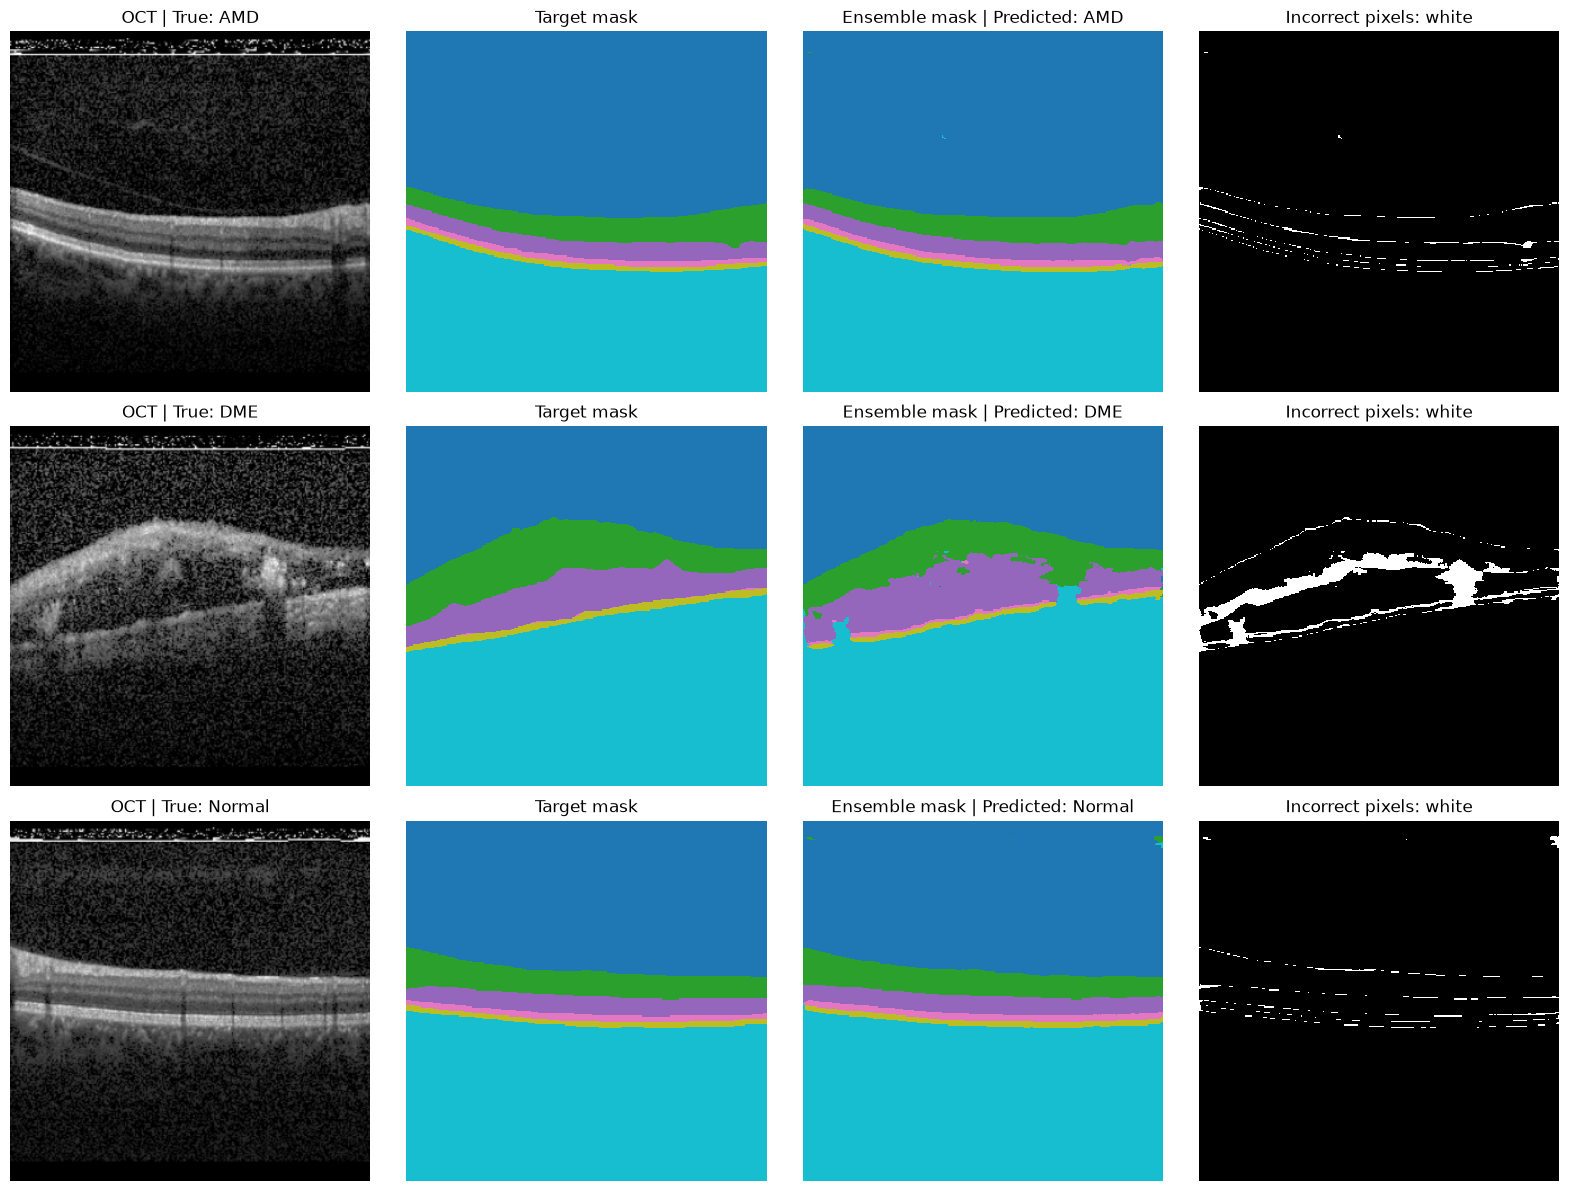

Saved demo figure: C:\Users\asus\Documents\FrameX-EN3160-CAMEL\FrameX-EN3160-CAMEL\camel_newresnet_lr0p01_b0_b7_validation_20261119_155126_920786\ensemble_demo_20261119_221812_034859.png


In [22]:
# FINAL DEMO: SAVED THREE-MODEL ENSEMBLE
import json
import gc
from pathlib import Path
from datetime import datetime

import torch
import matplotlib.pyplot as plt


# Check that notebook setup has already run.
required = ["dataset", "testloader", "CAMELModel", "device"]
missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        f"Run the notebook setup cells first. Missing: {missing}"
    )


# Load the ensemble configuration and validation-derived weights.
demo_folder = Path(
    r"C:\Users\asus\Documents\FrameX-EN3160-CAMEL"
    r"\FrameX-EN3160-CAMEL"
    r"\camel_newresnet_lr0p01_b0_b7_validation_20261119_155126_920786"
)

settings_path = demo_folder / "ensemble_settings.json"

with open(settings_path, encoding="utf-8") as file:
    settings = json.load(file)

assert settings["weight_source"] == "validation"

model_settings = settings["models"]
classification_weights = settings["classification_weights"]
segmentation_weights = settings["segmentation_weights"]
class_names = settings["class_names"]

assert list(dataset.class_names) == class_names
assert len(model_settings) == len(classification_weights)
assert len(model_settings) == len(segmentation_weights)

print("Ensemble models:")
for member in model_settings:
    print(f"- {member['name']} | selected epoch {member['selected_epoch']}")


# Select one test image for each disease class.
examples = {}

for images, labels, masks in testloader:
    for i in range(images.size(0)):
        class_id = labels[i].item()

        if class_id not in examples:
            examples[class_id] = (
                images[i].cpu(),
                masks[i].cpu(),
            )

    if len(examples) == len(class_names):
        break

if len(examples) != len(class_names):
    raise ValueError("The test set does not contain every disease class.")

selected_classes = sorted(examples)

selected_images = torch.stack([
    examples[class_id][0]
    for class_id in selected_classes
])

selected_masks = torch.stack([
    examples[class_id][1]
    for class_id in selected_classes
])

number_of_images = len(selected_classes)
height, width = selected_masks.shape[-2:]

classification_probabilities = torch.zeros(
    number_of_images,
    len(class_names),
    dtype=torch.float32,
)

segmentation_probabilities = torch.zeros(
    number_of_images,
    6,
    height,
    width,
    dtype=torch.float32,
)


# Keep any existing notebook model on CPU while loading ensemble members.
had_existing_model = "model" in globals()

if had_existing_model:
    model.cpu()

if device.type == "cuda":
    torch.cuda.empty_cache()


# Predict with each saved member and combine its probabilities.
for model_index, member_settings in enumerate(model_settings):
    name = member_settings["name"]
    encoder_name = member_settings["encoder_name"]
    checkpoint_path = Path(member_settings["path"])

    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)

    member = CAMELModel(encoder_name=encoder_name)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True,
    )

    member.load_state_dict(checkpoint["model_state_dict"])
    del checkpoint

    member = member.to(device)
    member.eval()

    with torch.no_grad():
        for i in range(number_of_images):
            image = selected_images[i:i + 1].to(device)

            classification_output, segmentation_output = member(image)

            classification_probabilities[i] += (
                float(classification_weights[model_index])
                * torch.softmax(classification_output, dim=1)[0].cpu()
            )

            segmentation_probabilities[i] += (
                float(segmentation_weights[model_index])
                * torch.softmax(segmentation_output, dim=1)[0].cpu()
            )

    print("Predictions complete:", name)

    member.cpu()
    del member
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()


# Convert combined probabilities to final class and pixel predictions.
predicted_classes = classification_probabilities.argmax(dim=1)
predicted_masks = segmentation_probabilities.argmax(dim=1)

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

mask_colors = plt.get_cmap("tab10", 6)

fig, axes = plt.subplots(
    number_of_images,
    4,
    figsize=(16, 4 * number_of_images),
    squeeze=False,
)

for i, class_id in enumerate(selected_classes):
    image = (selected_images[i] * std + mean).clamp(0, 1).mean(dim=0)

    true_disease = class_names[class_id]
    predicted_disease = class_names[predicted_classes[i].item()]
    pixel_errors = predicted_masks[i] != selected_masks[i]

    axes[i, 0].imshow(image, cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"OCT | True: {true_disease}")

    axes[i, 1].imshow(
        selected_masks[i],
        cmap=mask_colors,
        vmin=-0.5,
        vmax=5.5,
        interpolation="nearest",
    )
    axes[i, 1].set_title("Target mask")

    axes[i, 2].imshow(
        predicted_masks[i],
        cmap=mask_colors,
        vmin=-0.5,
        vmax=5.5,
        interpolation="nearest",
    )
    axes[i, 2].set_title(f"Ensemble mask | Predicted: {predicted_disease}")

    axes[i, 3].imshow(
        pixel_errors,
        cmap="gray",
        vmin=0,
        vmax=1,
        interpolation="nearest",
    )
    axes[i, 3].set_title("Incorrect pixels: white")

    for axis in axes[i]:
        axis.axis("off")

plt.tight_layout()

figure_path = demo_folder / (
    f"ensemble_demo_{datetime.now():%Y%m%d_%H%M%S_%f}.png"
)

plt.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved demo figure:", figure_path)


# Restore the notebook's existing model to its previous device.
if had_existing_model:
    model.to(device)